# NF-ToN-IoT-v3 — Data understanding

**Owner:** Cyrine Chabbar. Main notebook for NF-ToN-IoT-v3, with the checks of Ahmed Hamouda's analysis added at the end (outputs computed on the full dataset). Written findings for every step: `docs/checks ds1.docx` and the merged section at the end of this notebook.

In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

for folder, subfolders, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file == 'NF-ToN-IoT-v3.csv':
            print("Dataset found:", os.path.join(folder, file))


Dataset found: /content/drive/MyDrive/DS/NF_ToN_IoT_v3./NF-ToN-IoT-v3.csv


In [ ]:

import pandas as pd

path = "/content/drive/MyDrive/DS/NF_ToN_IoT_v3./NF-ToN-IoT-v3.csv"

# Read only the first 5 rows to avoid filling RAM
df_preview = pd.read_csv(path, nrows=5)

print("Number of columns:", len(df_preview.columns))
print("\nColumn names and data types:")
print(df_preview.dtypes.to_string())

print("\nFirst 5 rows:")
display(df_preview)


Number of columns: 55

Column names and data types:
FLOW_START_MILLISECONDS         int64
FLOW_END_MILLISECONDS           int64
IPV4_SRC_ADDR                  object
L4_SRC_PORT                     int64
IPV4_DST_ADDR                  object
L4_DST_PORT                     int64
PROTOCOL                        int64
L7_PROTO                        int64
IN_BYTES                        int64
IN_PKTS                         int64
OUT_BYTES                       int64
OUT_PKTS                        int64
TCP_FLAGS                       int64
CLIENT_TCP_FLAGS                int64
SERVER_TCP_FLAGS                int64
FLOW_DURATION_MILLISECONDS      int64
DURATION_IN                     int64
DURATION_OUT                    int64
MIN_TTL                         int64
MAX_TTL                         int64
LONGEST_FLOW_PKT                int64
SHORTEST_FLOW_PKT               int64
MIN_IP_PKT_LEN                  int64
MAX_IP_PKT_LEN                  int64
SRC_TO_DST_SECOND_BYTES         int6

,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,...,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
0,1556028590618,1556028590618,192.168.1.32,41315,192.168.1.169,10010,6,0,44,1,...,0,0,0,0,0,0,0,0,0,Benign
1,1556028590618,1556028590621,192.168.1.32,41315,192.168.1.194,49400,6,0,44,1,...,0,0,0,0,0,0,0,0,0,Benign
2,1556028590618,1556028590621,192.168.1.32,41315,192.168.1.193,8008,6,161,44,1,...,0,0,0,0,0,0,0,0,1,scanning
3,1556028590624,1556028590628,192.168.1.32,41315,192.168.1.194,85,6,0,44,1,...,0,0,0,0,0,0,0,0,0,Benign
4,1556028590624,1556028590624,192.168.1.32,41317,192.168.1.180,1056,6,0,44,1,...,0,0,0,0,0,0,0,0,0,Benign


In [ ]:

# Count all data rows without loading the dataset into RAM
with open(path, "rb") as f:
    total_rows = sum(chunk.count(b"\n") for chunk in iter(lambda: f.read(8 * 1024 * 1024), b"")) - 1

print("Total rows:", total_rows)
print("Total columns:", len(df_preview.columns))


Total rows: 27520260
Total columns: 55


In [ ]:

print("Rows processed:", total_processed)
print("First column count:", full_stats.iloc[0]["count"])


Rows processed: 27520260
First column count: 20260.0


In [ ]:

print("Total processed:", total_processed)
print("Numeric column count:", len(columns))
print("Counts range:", counts.min(), counts.max())
print("First 5 counts:", counts[:5])


Total processed: 27520260
Numeric column count: 52
Counts range: 20260.0 20260.0
First 5 counts: [20260. 20260. 20260. 20260. 20260.]


In [ ]:

import pandas as pd
import numpy as np

# Reset everything BEFORE processing
total_processed = 0
counts = None

for chunk in pd.read_csv(path, chunksize=100000):
    numeric = chunk.select_dtypes(include="number")
    values = numeric.to_numpy(dtype=np.float64)

    if counts is None:
        columns = numeric.columns
        n = len(columns)
        counts = np.zeros(n)
        means = np.zeros(n)
        M2 = np.zeros(n)
        minimums = np.full(n, np.inf)
        maximums = np.full(n, -np.inf)

    # Stable, chunk-by-chunk statistics
    for j in range(len(columns)):
        x = values[:, j]
        x = x[np.isfinite(x)]

        if len(x) == 0:
            continue

        batch_n = len(x)
        batch_mean = x.mean()
        batch_M2 = ((x - batch_mean) ** 2).sum()

        combined_n = counts[j] + batch_n
        delta = batch_mean - means[j]

        means[j] += delta * batch_n / combined_n
        M2[j] += batch_M2 + delta**2 * counts[j] * batch_n / combined_n
        counts[j] = combined_n

        minimums[j] = min(minimums[j], x.min())
        maximums[j] = max(maximums[j], x.max())

    total_processed += len(chunk)

    if total_processed % 5000000 < len(chunk):
        print(f"Processed {total_processed:,} rows")

full_stats = pd.DataFrame({
    "count": counts.astype(int),
    "mean": means,
    "std": np.sqrt(M2 / np.maximum(counts - 1, 1)),
    "min": minimums,
    "max": maximums
}, index=columns)

print("\nRows processed:", total_processed)
print("Counts range:", counts.min(), counts.max())

display(full_stats)


Processed 5,000,000 rows
Processed 10,000,000 rows
Processed 15,000,000 rows
Processed 20,000,000 rows
Processed 25,000,000 rows

Rows processed: 27520260
Counts range: 27520260.0 27520260.0


,count,mean,std,min,max
FLOW_START_MILLISECONDS,27520260,1.556211e+12,1.462831e+08,1.556029e+12,1.556549e+12
FLOW_END_MILLISECONDS,27520260,1.556211e+12,1.462832e+08,1.556029e+12,1.556549e+12
L4_SRC_PORT,27520260,3.298734e+04,2.270672e+04,0.000000e+00,6.553500e+04
L4_DST_PORT,27520260,1.816723e+04,2.277636e+04,0.000000e+00,6.553500e+04
PROTOCOL,27520260,7.719449e+00,4.090834e+00,1.000000e+00,5.800000e+01
L7_PROTO,27520260,2.733168e+01,4.362540e+01,0.000000e+00,4.010000e+02
IN_BYTES,27520260,4.544818e+02,3.886208e+04,4.000000e+00,7.984694e+07
IN_PKTS,27520260,4.049334e+00,6.241651e+02,1.000000e+00,1.220131e+06
OUT_BYTES,27520260,3.722711e+02,2.762322e+04,0.000000e+00,7.022131e+07
OUT_PKTS,27520260,1.909364e+00,3.766641e+02,0.000000e+00,1.350048e+06


In [ ]:

import os

for root, dirs, files in os.walk("/content/drive/MyDrive/DS"):
    for file in files:
        if "NetFlow_v3_Features" in file:
            print(os.path.join(root, file))


/content/drive/MyDrive/DS/NF_ToN_IoT_v3./NetFlow_v3_Features.csv
/content/drive/MyDrive/DS/seconddataset /NetFlow_v3_Features.csv


In [ ]:

dictionary_path = "/content/drive/MyDrive/DS/NF_ToN_IoT_v3./NetFlow_v3_Features.csv"

dictionary = pd.read_csv(dictionary_path)

print("Dictionary shape:", dictionary.shape)
print("Dictionary columns:", dictionary.columns.tolist())

display(dictionary.head())


Dictionary shape: (53, 2)
Dictionary columns: ['Feature', 'Description']


,Feature,Description
0,IPV4_SRC_ADDR,IPv4 source address
1,IPV4_DST_ADDR,IPv4 destination address
2,L4_SRC_PORT,IPv4 source port number
3,L4_DST_PORT,IPv4 destination port number
4,PROTOCOL,IP protocol identifier byte


In [ ]:

# Remove accidental spaces from dictionary feature names
dictionary["Feature"] = dictionary["Feature"].str.strip()

# Read only the CSV header (not the whole dataset)
dataset_columns = pd.read_csv(path, nrows=0).columns.str.strip().tolist()

documented = set(dictionary["Feature"])
actual_features = set(dataset_columns) - {"Label", "Attack"}

print("Documented features:", len(documented))
print("Dataset features:", len(actual_features))
print("Missing from dataset:", sorted(documented - actual_features))
print("Missing from dictionary:", sorted(actual_features - documented))


Documented features: 53
Dataset features: 53
Missing from dataset: []
Missing from dictionary: []


In [ ]:

# Inspect column types from the full-dataset scan
print("Numeric columns:", len(columns))
print("Other columns:",
      [c for c in dataset_columns if c not in columns])

# Show the types in the first 5 rows
preview = pd.read_csv(path, nrows=5)
display(preview.dtypes.to_frame("Preview dtype"))


Numeric columns: 52
Other columns: ['IPV4_SRC_ADDR', 'IPV4_DST_ADDR', 'Attack']


,Preview dtype
FLOW_START_MILLISECONDS,int64
FLOW_END_MILLISECONDS,int64
IPV4_SRC_ADDR,object
L4_SRC_PORT,int64
IPV4_DST_ADDR,object
L4_DST_PORT,int64
PROTOCOL,int64
L7_PROTO,int64
IN_BYTES,int64
IN_PKTS,int64


In [ ]:

# Check data types in EVERY chunk of the CSV
type_sets = {col: set() for col in dataset_columns}
rows_checked = 0

for chunk in pd.read_csv(path, chunksize=100000):
    for col, dtype in chunk.dtypes.items():
        type_sets[col].add(str(dtype))
    rows_checked += len(chunk)

type_report = pd.DataFrame({
    "Column": dataset_columns,
    "Observed dtypes": [
        ", ".join(sorted(type_sets[col]))
        for col in dataset_columns
    ]
})

print("Rows checked:", rows_checked)
display(type_report)


Rows checked: 27520260


,Column,Observed dtypes
0,FLOW_START_MILLISECONDS,int64
1,FLOW_END_MILLISECONDS,int64
2,IPV4_SRC_ADDR,object
3,L4_SRC_PORT,int64
4,IPV4_DST_ADDR,object
5,L4_DST_PORT,int64
6,PROTOCOL,int64
7,L7_PROTO,int64
8,IN_BYTES,int64
9,IN_PKTS,int64


In [ ]:

%pip -q install duckdb
import duckdb
print("DuckDB ready!")


DuckDB ready!


In [ ]:

import duckdb

con = duckdb.connect()
con.execute("SET memory_limit = '3GB'")
con.execute("SET threads = 2")
con.execute("SET preserve_insertion_order = false")

# Process columns in small batches to reduce memory usage
results = []

for i in range(0, len(dataset_columns), 3):
    batch = dataset_columns[i:i+3]

    expressions = [
        f'COUNT(DISTINCT "{col}") AS "n{j}"'
        for j, col in enumerate(batch)
    ]

    query = f"""
        SELECT {", ".join(expressions)}
        FROM read_csv(
            '{path}',
            header=true,
            all_varchar=true
        )
    """

    counts_batch = con.execute(query).fetchone()

    for col, count in zip(batch, counts_batch):
        results.append((col, count))

    print(f"Completed {min(i+3, len(dataset_columns))}/55 columns")

distinct_report = pd.DataFrame(
    results,
    columns=["Column", "Distinct values"]
)

display(distinct_report)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Completed 3/55 columns


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Completed 6/55 columns


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

...

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Completed 54/55 columns


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Completed 55/55 columns


,Column,Distinct values
0,FLOW_START_MILLISECONDS,12299784
1,FLOW_END_MILLISECONDS,12439429
2,IPV4_SRC_ADDR,15270
3,L4_SRC_PORT,65536
4,IPV4_DST_ADDR,8777
5,L4_DST_PORT,65536
6,PROTOCOL,5
7,L7_PROTO,133
8,IN_BYTES,18423
9,IN_PKTS,2421


In [ ]:

# Build the complete Step 0.3 feature dictionary

descriptions = dict(zip(
    dictionary["Feature"],
    dictionary["Description"]
))

descriptions["Label"] = "Binary classification target (0 = benign, 1 = attack)"
descriptions["Attack"] = "Attack category / benign class"

feature_report = pd.DataFrame({
    "Feature": dataset_columns,
    "Description": [
        descriptions.get(col, "NOT DOCUMENTED")
        for col in dataset_columns
    ],
    "Data type": [
        ", ".join(sorted(type_sets[col]))
        for col in dataset_columns
    ],
    "Distinct values": [
        dict(results)[col]
        for col in dataset_columns
    ],
    "Example value": [
        preview[col].iloc[0]
        for col in dataset_columns
    ]
})

pd.set_option("display.max_colwidth", 180)
display(feature_report)

print("Total columns:", len(feature_report))
print("Undocumented columns:",
      (feature_report["Description"] == "NOT DOCUMENTED").sum())


,Feature,Description,Data type,Distinct values,Example value
0,FLOW_START_MILLISECONDS,Flow start timestamp in milliseconds,int64,12299784,1556028590618
1,FLOW_END_MILLISECONDS,Flow end timestamp in milliseconds,int64,12439429,1556028590618
2,IPV4_SRC_ADDR,IPv4 source address,object,15270,192.168.1.32
3,L4_SRC_PORT,IPv4 source port number,int64,65536,41315
4,IPV4_DST_ADDR,IPv4 destination address,object,8777,192.168.1.169
5,L4_DST_PORT,IPv4 destination port number,int64,65536,10010
6,PROTOCOL,IP protocol identifier byte,int64,5,6
7,L7_PROTO,Layer 7 protocol (numeric),int64,133,0
8,IN_BYTES,Incoming number of bytes,int64,18423,44
9,IN_PKTS,Incoming number of packets,int64,2421,1


Total columns: 55
Undocumented columns: 0


In [ ]:

# Inspect suspicious dictionary descriptions exactly as stored

suspect_features = [
    "DURATION_IN",
    "DURATION_OUT",
    "NUM_PKTS_1024_TO_1514_BYTES",
    "SRC_TO_DST_IAT_MIN",
    "SRC_TO_DST_IAT_MAX",
    "SRC_TO_DST_IAT_AVG",
    "SRC_TO_DST_IAT_STDDEV",
    "DST_TO_SRC_IAT_MIN",
    "DST_TO_SRC_IAT_MAX",
    "DST_TO_SRC_IAT_AVG",
    "DST_TO_SRC_IAT_STDDEV"
]

for feature in suspect_features:
    description = descriptions[feature]
    print(f"{feature}: {description!r}")


DURATION_IN: 'Client to Server stream duration (msec)'
DURATION_OUT: 'Client to Server stream duration (msec)'
NUM_PKTS_1024_TO_1514_BYTES: 'Packets whose IP size >��1024 and <= 1514'
SRC_TO_DST_IAT_MIN: 'Minimum Inter-Packet Arrval Time (src->dst)'
SRC_TO_DST_IAT_MAX: 'Maximum Inter-Packet Arrval Time (src->dst)'
SRC_TO_DST_IAT_AVG: 'Average Inter-Packet Arrval Time (src->dst)'
SRC_TO_DST_IAT_STDDEV: 'Sandard Deviaion Inter-Packet Arrval Time (src->dst)'
DST_TO_SRC_IAT_MIN: 'Minimum Inter-Packet Arrval Time (dst > src)'
DST_TO_SRC_IAT_MAX: 'Minimum Inter-Packet Arrval Time  (dst > src)'
DST_TO_SRC_IAT_AVG: 'Minimum Inter-Packet Arrval Time  (dst > src)'
DST_TO_SRC_IAT_STDDEV: 'Minimum Inter-Packet Arrval Time  (dst > src)'


In [ ]:

# Step 0.4 — Save ToN-IoT schema

ton_schema = pd.DataFrame({
    "Column": dataset_columns,
    "Data type": [
        ", ".join(sorted(type_sets[col]))
        for col in dataset_columns
    ],
    "Position": range(1, len(dataset_columns) + 1)
})

display(ton_schema)

ton_schema.to_csv(
    "/content/drive/MyDrive/DS/ToN_schema.csv",
    index=False
)

print("Schema saved successfully!")


,Column,Data type,Position
0,FLOW_START_MILLISECONDS,int64,1
1,FLOW_END_MILLISECONDS,int64,2
2,IPV4_SRC_ADDR,object,3
3,L4_SRC_PORT,int64,4
4,IPV4_DST_ADDR,object,5
5,L4_DST_PORT,int64,6
6,PROTOCOL,int64,7
7,L7_PROTO,int64,8
8,IN_BYTES,int64,9
9,IN_PKTS,int64,10


Schema saved successfully!


In [ ]:

import os

# Look for Ahmed's datasets or saved schema files
for root, dirs, files in os.walk("/content/drive/MyDrive/DS"):
    for file in files:
        if any(word in file.lower() for word in [
            "unsw", "cic", "schema"
        ]):
            print(os.path.join(root, file))


/content/drive/MyDrive/DS/ToN_schema.csv


In [ ]:

import pandas as pd

# Count every Label and Attack category across the FULL dataset
label_counts = pd.Series(dtype="int64")
attack_counts = pd.Series(dtype="int64")
total_rows = 0

for chunk in pd.read_csv(
    path,
    usecols=["Label", "Attack"],
    chunksize=500000
):
    label_counts = label_counts.add(
        chunk["Label"].value_counts(dropna=False),
        fill_value=0
    )

    attack_counts = attack_counts.add(
        chunk["Attack"].value_counts(dropna=False),
        fill_value=0
    )

    total_rows += len(chunk)

label_report = pd.DataFrame({
    "Count": label_counts.astype("int64"),
    "Percentage": (label_counts / total_rows * 100).round(2)
})

attack_report = pd.DataFrame({
    "Count": attack_counts.astype("int64"),
    "Percentage": (attack_counts / total_rows * 100).round(2)
})

print("Total rows checked:", total_rows)

print("\nLABEL DISTRIBUTION")
display(label_report)

print("\nATTACK DISTRIBUTION")
display(attack_report)


Total rows checked: 27520260

LABEL DISTRIBUTION


,Count,Percentage
Label,,
0,16792214,61.02
1,10728046,38.98



ATTACK DISTRIBUTION


,Count,Percentage
Attack,,
Backdoor,203384,0.74
Benign,16792214,61.02
ddos,4141256,15.05
dos,203456,0.74
injection,381777,1.39
mitm,6013,0.02
password,1594777,5.79
ransomware,3971,0.01
scanning,1358977,4.94


In [ ]:

# Check Label and Attack consistency across ALL rows

consistency_counts = {}
inconsistent_count = 0
total_checked = 0

for chunk in pd.read_csv(
    path,
    usecols=["Label", "Attack"],
    chunksize=500000
):
    # Count each Attack / Label combination
    counts = chunk.groupby(
        ["Attack", "Label"], dropna=False
    ).size()

    for key, count in counts.items():
        consistency_counts[key] = (
            consistency_counts.get(key, 0) + int(count)
        )

    # Detect incorrect combinations
    invalid = (
        ((chunk["Attack"] == "Benign") & (chunk["Label"] != 0))
        |
        ((chunk["Attack"] != "Benign") & (chunk["Label"] != 1))
    )

    inconsistent_count += int(invalid.sum())
    total_checked += len(chunk)

consistency_report = pd.DataFrame(
    [
        {"Attack": attack, "Label": label, "Count": count}
        for (attack, label), count in consistency_counts.items()
    ]
).sort_values(["Attack", "Label"])

display(consistency_report)

print("Rows checked:", total_checked)
print("Inconsistent records:", inconsistent_count)


,Attack,Label,Count
7,Backdoor,1,203384
0,Benign,0,16792214
4,ddos,1,4141256
2,dos,1,203456
3,injection,1,381777
9,mitm,1,6013
5,password,1,1594777
8,ransomware,1,3971
1,scanning,1,1358977
6,xss,1,2834435


Rows checked: 27520260
Inconsistent records: 0


In [ ]:

# Check 1.3 — Missing and blank target values

missing_label = 0
missing_attack = 0
blank_attack = 0
rows_checked = 0

for chunk in pd.read_csv(
    path,
    usecols=["Label", "Attack"],
    chunksize=500000
):
    missing_label += chunk["Label"].isna().sum()
    missing_attack += chunk["Attack"].isna().sum()

    blank_attack += (
        chunk["Attack"]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
        & chunk["Attack"].notna()
    ).sum()

    rows_checked += len(chunk)

print("Rows checked:", rows_checked)
print("Missing Label values:", int(missing_label))
print("Missing Attack values:", int(missing_attack))
print("Blank Attack names:", int(blank_attack))


Rows checked: 27520260
Missing Label values: 0
Missing Attack values: 0
Blank Attack names: 0


In [ ]:

# Check attack category spelling and formatting

attack_names = sorted(attack_counts.index.tolist())

print("Attack categories:")
for name in attack_names:
    print(repr(name))

print("\nNames with surrounding spaces:")
print([name for name in attack_names if name != name.strip()])

print("\nNames that become duplicates after lowercase/strip:")
normalized = [name.strip().lower() for name in attack_names]
print(len(normalized) - len(set(normalized)))


Attack categories:
'Backdoor'
'Benign'
'ddos'
'dos'
'injection'
'mitm'
'password'
'ransomware'
'scanning'
'xss'

Names with surrounding spaces:
[]

Names that become duplicates after lowercase/strip:
0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import pandas as pd

# Restore dataset path
path = "/content/drive/MyDrive/DS/NF_ToN_IoT_v3./NF-ToN-IoT-v3.csv"

# Restore column names and preview
dataset_columns = pd.read_csv(path, nrows=0).columns.tolist()
preview = pd.read_csv(path, nrows=5)

print("Dataset columns:", len(dataset_columns))
print("Preview loaded successfully!")
display(preview.head(2))


Dataset columns: 55
Preview loaded successfully!


,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,...,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
0,1556028590618,1556028590618,192.168.1.32,41315,192.168.1.169,10010,6,0,44,1,...,0,0,0,0,0,0,0,0,0,Benign
1,1556028590618,1556028590621,192.168.1.32,41315,192.168.1.194,49400,6,0,44,1,...,0,0,0,0,0,0,0,0,0,Benign


In [ ]:

# Check 2.1 — Exact protocol value counts

protocol_counts = {}
l7_counts = {}

for chunk in pd.read_csv(
    path,
    usecols=["PROTOCOL", "L7_PROTO"],
    chunksize=500000
):
    for col, result in [
        ("PROTOCOL", protocol_counts),
        ("L7_PROTO", l7_counts)
    ]:
        for value, count in chunk[col].value_counts().items():
            result[value] = result.get(value, 0) + int(count)

print("PROTOCOL values:")
print(dict(sorted(protocol_counts.items())))

print("\nL7_PROTO distinct values:", len(l7_counts))

print("\nTop 20 L7_PROTO values:")
display(
    pd.Series(l7_counts)
    .sort_values(ascending=False)
    .head(20)
    .to_frame("Count")
)


PROTOCOL values:
{1: 215377, 2: 24847, 6: 22875991, 17: 4402790, 58: 1255}

L7_PROTO distinct values: 133

Top 20 L7_PROTO values:


,Count
0,8452498
7,7304463
91,6155642
5,4244397
1,222886
81,215377
131,156372
12,74799
3,42728
92,41337


In [ ]:

# Check 2.2 — Ranges and distinct values of coded fields

coded_columns = [
    "TCP_FLAGS",
    "CLIENT_TCP_FLAGS",
    "SERVER_TCP_FLAGS",
    "ICMP_TYPE",
    "ICMP_IPV4_TYPE",
    "DNS_QUERY_TYPE",
    "FTP_COMMAND_RET_CODE"
]

summary = {}

for chunk in pd.read_csv(
    path,
    usecols=coded_columns,
    chunksize=500000
):
    for col in coded_columns:
        if col not in summary:
            summary[col] = {
                "min": chunk[col].min(),
                "max": chunk[col].max(),
                "values": set()
            }

        summary[col]["min"] = min(
            summary[col]["min"], chunk[col].min()
        )
        summary[col]["max"] = max(
            summary[col]["max"], chunk[col].max()
        )
        summary[col]["values"].update(chunk[col].unique())

report = pd.DataFrame([
    {
        "Column": col,
        "Minimum": summary[col]["min"],
        "Maximum": summary[col]["max"],
        "Distinct values": len(summary[col]["values"])
    }
    for col in coded_columns
])

display(report)


,Column,Minimum,Maximum,Distinct values
0,TCP_FLAGS,0,219,26
1,CLIENT_TCP_FLAGS,0,219,25
2,SERVER_TCP_FLAGS,0,31,20
3,ICMP_TYPE,0,65280,359
4,ICMP_IPV4_TYPE,0,255,256
5,DNS_QUERY_TYPE,0,11828,13
6,FTP_COMMAND_RET_CODE,0,553,17


In [ ]:

# Check exact DNS and FTP code frequencies

code_counts = {
    "DNS_QUERY_TYPE": {},
    "FTP_COMMAND_RET_CODE": {}
}

for chunk in pd.read_csv(
    path,
    usecols=list(code_counts),
    chunksize=500000
):
    for col in code_counts:
        for value, count in chunk[col].value_counts().items():
            code_counts[col][int(value)] = (
                code_counts[col].get(int(value), 0) + int(count)
            )

for col, counts in code_counts.items():
    print("\n", col)
    display(pd.DataFrame({
        "Code": sorted(counts),
        "Count": [counts[v] for v in sorted(counts)]
    }))



 DNS_QUERY_TYPE


,Code,Count
0,0,23275172
1,1,3439757
2,2,3693
3,6,23
4,12,57309
5,16,369
6,28,708961
7,33,8264
8,43,13619
9,48,1554



 FTP_COMMAND_RET_CODE


,Code,Count
0,0,27432034
1,150,15
2,200,5
3,213,6
4,215,6
5,220,35
6,221,32
7,227,68
8,229,4
9,230,80


In [ ]:

# Find the actual row containing DNS_QUERY_TYPE = 11828

for chunk in pd.read_csv(path, chunksize=500000):
    matches = chunk[chunk["DNS_QUERY_TYPE"] == 11828]

    if not matches.empty:
        print("Matching rows:", len(matches))
        display(matches[[
            "FLOW_START_MILLISECONDS",
            "IPV4_SRC_ADDR",
            "IPV4_DST_ADDR",
            "PROTOCOL",
            "L7_PROTO",
            "DNS_QUERY_ID",
            "DNS_QUERY_TYPE",
            "DNS_TTL_ANSWER",
            "Label",
            "Attack"
        ]])
        break


Matching rows: 1


,FLOW_START_MILLISECONDS,IPV4_SRC_ADDR,IPV4_DST_ADDR,PROTOCOL,L7_PROTO,DNS_QUERY_ID,DNS_QUERY_TYPE,DNS_TTL_ANSWER,Label,Attack
8205351,1556079687097,192.168.1.31,192.168.1.194,6,5,49164,11828,0,0,Benign


In [ ]:

# Check 2.5 — TCP flag values and their frequencies

for col in [
    "TCP_FLAGS",
    "CLIENT_TCP_FLAGS",
    "SERVER_TCP_FLAGS"
]:
    print(f"\n{col}")
    print("Distinct values:", len(summary[col]["values"]))
    print("Values:", sorted(summary[col]["values"]))



TCP_FLAGS
Distinct values: 26
Values: [np.int64(0), np.int64(2), np.int64(4), np.int64(6), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(41), np.int64(57), np.int64(211), np.int64(214), np.int64(215), np.int64(219)]

CLIENT_TCP_FLAGS
Distinct values: 25
Values: [np.int64(0), np.int64(2), np.int64(4), np.int64(6), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(41), np.int64(198), np.int64(211), np.int64(215), np.int64(219)]

SERVER_TCP_FLAGS
Distinct values: 20
Values: [np.int64(0), np.int64(2), np.int64(4), np.int64(6), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np

In [ ]:

# Check TCP flags on flows where PROTOCOL is not TCP (6)

non_tcp_counts = {}
examples = []
rows_checked = 0

cols = [
    "PROTOCOL", "TCP_FLAGS",
    "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS",
    "Label", "Attack"
]

for chunk in pd.read_csv(path, usecols=cols, chunksize=500000):
    mask = (
        (chunk["PROTOCOL"] != 6)
        & (
            (chunk["TCP_FLAGS"] != 0)
            | (chunk["CLIENT_TCP_FLAGS"] != 0)
            | (chunk["SERVER_TCP_FLAGS"] != 0)
        )
    )

    for protocol, count in chunk.loc[mask, "PROTOCOL"].value_counts().items():
        non_tcp_counts[int(protocol)] = (
            non_tcp_counts.get(int(protocol), 0) + int(count)
        )

    if len(examples) < 5:
        examples.extend(
            chunk.loc[mask, cols].head(5 - len(examples)).to_dict("records")
        )

    rows_checked += len(chunk)

print("Rows checked:", rows_checked)
print("Non-TCP rows with nonzero TCP flags:", sum(non_tcp_counts.values()))
print("Breakdown by protocol:", non_tcp_counts)
display(pd.DataFrame(examples))


Rows checked: 27520260
Non-TCP rows with nonzero TCP flags: 0
Breakdown by protocol: {}


""


In [ ]:

# Check 2.7 — ICMP fields on non-ICMP flows

affected = {}
examples = []
rows_checked = 0

cols = [
    "PROTOCOL", "ICMP_TYPE", "ICMP_IPV4_TYPE",
    "Label", "Attack"
]

for chunk in pd.read_csv(path, usecols=cols, chunksize=500000):
    mask = (
        ~chunk["PROTOCOL"].isin([1, 58])
        & (
            (chunk["ICMP_TYPE"] != 0)
            | (chunk["ICMP_IPV4_TYPE"] != 0)
        )
    )

    for protocol, count in chunk.loc[mask, "PROTOCOL"].value_counts().items():
        affected[int(protocol)] = affected.get(int(protocol), 0) + int(count)

    if len(examples) < 5:
        examples.extend(
            chunk.loc[mask, cols].head(5 - len(examples)).to_dict("records")
        )

    rows_checked += len(chunk)

print("Rows checked:", rows_checked)
print("Non-ICMP rows with nonzero ICMP fields:", sum(affected.values()))
print("Breakdown by protocol:", affected)
display(pd.DataFrame(examples))


Rows checked: 27520260
Non-ICMP rows with nonzero ICMP fields: 429291
Breakdown by protocol: {6: 429291}


,PROTOCOL,ICMP_TYPE,ICMP_IPV4_TYPE,Label,Attack
0,6,9728,38,0,Benign
1,6,47616,186,0,Benign
2,6,63744,249,0,Benign
3,6,14336,56,0,Benign
4,6,36096,141,0,Benign


In [ ]:

# Check relationship between the two ICMP fields

total_checked = 0
matching = 0
different = 0
examples = []

for chunk in pd.read_csv(
    path,
    usecols=["PROTOCOL", "ICMP_TYPE", "ICMP_IPV4_TYPE"],
    chunksize=500000
):
    # Extract the type from the combined ICMP field
    extracted_type = chunk["ICMP_TYPE"] // 256

    match = extracted_type == chunk["ICMP_IPV4_TYPE"]

    matching += int(match.sum())
    different += int((~match).sum())
    total_checked += len(chunk)

    if len(examples) < 5:
        examples.extend(
            chunk.loc[~match].head(5 - len(examples)).to_dict("records")
        )

print("Rows checked:", total_checked)
print("Matching rows:", matching)
print("Different rows:", different)
display(pd.DataFrame(examples))


Rows checked: 27520260
Matching rows: 27520260
Different rows: 0


""


In [ ]:

# Check 2.9 — Breakdown of suspicious ICMP values by attack type

attack_breakdown = {}

for chunk in pd.read_csv(
    path,
    usecols=["PROTOCOL", "ICMP_TYPE", "ICMP_IPV4_TYPE", "Attack"],
    chunksize=500000
):
    mask = (
        (chunk["PROTOCOL"] == 6)
        & (
            (chunk["ICMP_TYPE"] != 0)
            | (chunk["ICMP_IPV4_TYPE"] != 0)
        )
    )

    for attack, count in chunk.loc[mask, "Attack"].value_counts().items():
        attack_breakdown[attack] = (
            attack_breakdown.get(attack, 0) + int(count)
        )

display(
    pd.DataFrame(
        sorted(attack_breakdown.items()),
        columns=["Attack", "Affected records"]
    )
)

print("Total affected:", sum(attack_breakdown.values()))


,Attack,Affected records
0,Backdoor,190616
1,Benign,138224
2,ddos,57731
3,dos,104
4,injection,6126
5,mitm,145
6,password,19367
7,ransomware,468
8,scanning,495
9,xss,16015


Total affected: 429291


In [ ]:

# Check 2.10 — L7 protocol codes for flows with DNS information

dns_l7_counts = {}

for chunk in pd.read_csv(
    path,
    usecols=[
        "L7_PROTO", "DNS_QUERY_ID",
        "DNS_QUERY_TYPE", "DNS_TTL_ANSWER"
    ],
    chunksize=500000
):
    mask = (
        (chunk["DNS_QUERY_ID"] != 0)
        | (chunk["DNS_QUERY_TYPE"] != 0)
        | (chunk["DNS_TTL_ANSWER"] != 0)
    )

    for code, count in chunk.loc[mask, "L7_PROTO"].value_counts().items():
        dns_l7_counts[int(code)] = (
            dns_l7_counts.get(int(code), 0) + int(count)
        )

display(
    pd.DataFrame(
        sorted(dns_l7_counts.items(), key=lambda x: -x[1]),
        columns=["L7_PROTO", "Records with DNS fields"]
    )
)

print("Total records:", sum(dns_l7_counts.values()))


,L7_PROTO,Records with DNS fields
0,5,4232056
1,154,13058


Total records: 4245114


In [ ]:

# Check 2.11 — Network protocols of records with DNS fields

dns_protocol_counts = {}

for chunk in pd.read_csv(
    path,
    usecols=[
        "PROTOCOL", "DNS_QUERY_ID",
        "DNS_QUERY_TYPE", "DNS_TTL_ANSWER"
    ],
    chunksize=500000
):
    mask = (
        (chunk["DNS_QUERY_ID"] != 0)
        | (chunk["DNS_QUERY_TYPE"] != 0)
        | (chunk["DNS_TTL_ANSWER"] != 0)
    )

    for protocol, count in chunk.loc[mask, "PROTOCOL"].value_counts().items():
        dns_protocol_counts[int(protocol)] = (
            dns_protocol_counts.get(int(protocol), 0) + int(count)
        )

print("DNS-related records by network protocol:")
print(dict(sorted(dns_protocol_counts.items())))
print("Total:", sum(dns_protocol_counts.values()))


DNS-related records by network protocol:
{6: 178, 17: 4244936}
Total: 4245114


In [ ]:

# Check 2.12 — FTP return codes by application protocol

ftp_l7_counts = {}

for chunk in pd.read_csv(
    path,
    usecols=["L7_PROTO", "FTP_COMMAND_RET_CODE"],
    chunksize=500000
):
    mask = chunk["FTP_COMMAND_RET_CODE"] != 0

    for code, count in chunk.loc[mask, "L7_PROTO"].value_counts().items():
        ftp_l7_counts[int(code)] = (
            ftp_l7_counts.get(int(code), 0) + int(count)
        )

print("L7 protocol codes with nonzero FTP return codes:")
print(dict(sorted(ftp_l7_counts.items())))
print("Total:", sum(ftp_l7_counts.values()))


L7 protocol codes with nonzero FTP return codes:
{1: 88199, 91: 27}
Total: 88226


In [ ]:

# Inspect records with FTP codes and L7_PROTO = 91

examples = []
total = 0

cols = [
    "PROTOCOL", "L7_PROTO", "L4_SRC_PORT",
    "L4_DST_PORT", "FTP_COMMAND_RET_CODE",
    "Label", "Attack"
]

for chunk in pd.read_csv(path, usecols=cols, chunksize=500000):
    mask = (
        (chunk["L7_PROTO"] == 91)
        & (chunk["FTP_COMMAND_RET_CODE"] != 0)
    )

    total += int(mask.sum())

    if len(examples) < 10:
        examples.extend(
            chunk.loc[mask, cols]
            .head(10 - len(examples))
            .to_dict("records")
        )

print("Matching records:", total)
display(pd.DataFrame(examples))


Matching records: 27


,PROTOCOL,L7_PROTO,L4_SRC_PORT,L4_DST_PORT,FTP_COMMAND_RET_CODE,Label,Attack
0,6,91,48140,21,220,0,Benign
1,6,91,48170,21,220,0,Benign
2,6,91,49610,21,530,0,Benign
3,6,91,39426,21,220,0,Benign
4,6,91,39438,21,220,0,Benign
5,6,91,39470,21,530,0,Benign
6,6,91,39480,21,220,0,Benign
7,6,91,56190,21,530,1,scanning
8,6,91,56292,21,530,1,scanning
9,6,91,38240,21,220,0,Benign


In [ ]:

# Check L7 protocol distribution for TCP records
# containing nonzero ICMP values

l7_breakdown = {}

for chunk in pd.read_csv(
    path,
    usecols=[
        "PROTOCOL", "L7_PROTO",
        "ICMP_TYPE", "ICMP_IPV4_TYPE"
    ],
    chunksize=500000
):
    mask = (
        (chunk["PROTOCOL"] == 6)
        & (
            (chunk["ICMP_TYPE"] != 0)
            | (chunk["ICMP_IPV4_TYPE"] != 0)
        )
    )

    for code, count in chunk.loc[mask, "L7_PROTO"].value_counts().items():
        l7_breakdown[int(code)] = (
            l7_breakdown.get(int(code), 0) + int(count)
        )

display(
    pd.DataFrame(
        sorted(l7_breakdown.items(), key=lambda x: -x[1]),
        columns=["L7_PROTO", "Affected records"]
    )
)

print("Total:", sum(l7_breakdown.values()))


,L7_PROTO,Affected records
0,7,137195
1,91,132022
2,131,83450
3,0,51914
4,1,22229
5,170,1190
6,10,477
7,41,147
8,4,141
9,77,82


Total: 429291


In [ ]:

# Check 2.15 — ICMP field values by IP protocol

protocol_summary = {}

for chunk in pd.read_csv(
    path,
    usecols=["PROTOCOL", "ICMP_TYPE", "ICMP_IPV4_TYPE"],
    chunksize=500000
):
    for protocol, group in chunk.groupby("PROTOCOL"):
        p = int(protocol)

        if p not in protocol_summary:
            protocol_summary[p] = {
                "Total records": 0,
                "Nonzero ICMP fields": 0
            }

        protocol_summary[p]["Total records"] += len(group)
        protocol_summary[p]["Nonzero ICMP fields"] += int(
            (
                (group["ICMP_TYPE"] != 0)
                | (group["ICMP_IPV4_TYPE"] != 0)
            ).sum()
        )

display(pd.DataFrame([
    {"PROTOCOL": p, **values}
    for p, values in sorted(protocol_summary.items())
]))


,PROTOCOL,Total records,Nonzero ICMP fields
0,1,215377,214869
1,2,24847,0
2,6,22875991,429291
3,17,4402790,0
4,58,1255,1255


In [ ]:

# Check 2.16 — Most common ICMP values on TCP records

icmp_tcp_counts = {}

for chunk in pd.read_csv(
    path,
    usecols=["PROTOCOL", "ICMP_TYPE", "ICMP_IPV4_TYPE"],
    chunksize=500000
):
    mask = (
        (chunk["PROTOCOL"] == 6)
        & (chunk["ICMP_TYPE"] != 0)
    )

    counts = chunk.loc[mask, "ICMP_IPV4_TYPE"].value_counts()

    for value, count in counts.items():
        icmp_tcp_counts[int(value)] = (
            icmp_tcp_counts.get(int(value), 0) + int(count)
        )

display(
    pd.DataFrame(
        sorted(icmp_tcp_counts.items(), key=lambda x: -x[1])[:20],
        columns=["ICMP_IPV4_TYPE", "Affected TCP records"]
    )
)

print("Distinct ICMP types on TCP:",
      len(icmp_tcp_counts))


,ICMP_IPV4_TYPE,Affected TCP records
0,144,144059
1,60,58041
2,73,48113
3,96,28663
4,137,24203
5,44,22619
6,48,17996
7,178,8499
8,40,7889
9,185,6730


Distinct ICMP types on TCP: 256


In [ ]:

# Check whether ICMP_TYPE contains a nonzero code byte
# on the suspicious TCP records

total = 0
zero_code = 0
nonzero_code = 0

for chunk in pd.read_csv(
    path,
    usecols=["PROTOCOL", "ICMP_TYPE"],
    chunksize=500000
):
    values = chunk.loc[
        (chunk["PROTOCOL"] == 6)
        & (chunk["ICMP_TYPE"] != 0),
        "ICMP_TYPE"
    ]

    total += len(values)
    zero_code += int((values % 256 == 0).sum())
    nonzero_code += int((values % 256 != 0).sum())

print("Affected TCP records:", total)
print("ICMP code byte = 0:", zero_code)
print("ICMP code byte != 0:", nonzero_code)


Affected TCP records: 429291
ICMP code byte = 0: 429171
ICMP code byte != 0: 120


In [ ]:

# Step 3.1 — Missing and blank values in all columns

missing_counts = {col: 0 for col in dataset_columns}
blank_counts = {col: 0 for col in dataset_columns}
total_rows = 0

for chunk in pd.read_csv(path, chunksize=500000):
    total_rows += len(chunk)

    # Count missing values
    for col, count in chunk.isna().sum().items():
        missing_counts[col] += int(count)

    # Count blank text values
    for col in ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "Attack"]:
        blank_counts[col] += int(
            (
                chunk[col].notna()
                & chunk[col].astype("string").str.strip().eq("")
            ).fillna(False).sum()
        )

missing_report = pd.DataFrame({
    "Column": dataset_columns,
    "Missing values": [missing_counts[c] for c in dataset_columns],
    "Blank text values": [blank_counts[c] for c in dataset_columns]
})

missing_report["Missing %"] = (
    missing_report["Missing values"] / total_rows * 100
).round(4)

print("Rows checked:", total_rows)
print("Total missing values:", sum(missing_counts.values()))
print("Total blank text values:", sum(blank_counts.values()))

display(missing_report)


Rows checked: 27520260
Total missing values: 0
Total blank text values: 0


,Column,Missing values,Blank text values,Missing %
0,FLOW_START_MILLISECONDS,0,0,0.0
1,FLOW_END_MILLISECONDS,0,0,0.0
2,IPV4_SRC_ADDR,0,0,0.0
3,L4_SRC_PORT,0,0,0.0
4,IPV4_DST_ADDR,0,0,0.0
5,L4_DST_PORT,0,0,0.0
6,PROTOCOL,0,0,0.0
7,L7_PROTO,0,0,0.0
8,IN_BYTES,0,0,0.0
9,IN_PKTS,0,0,0.0


In [ ]:

# Step 3.2 — Count zeros across all numeric columns

numeric_columns = preview.select_dtypes(include="number").columns.tolist()

zero_counts = {col: 0 for col in numeric_columns}
rows_checked = 0

for chunk in pd.read_csv(
    path,
    usecols=numeric_columns,
    chunksize=500000
):
    counts = (chunk == 0).sum()

    for col in numeric_columns:
        zero_counts[col] += int(counts[col])

    rows_checked += len(chunk)

zero_report = pd.DataFrame({
    "Column": numeric_columns,
    "Zero count": [zero_counts[c] for c in numeric_columns]
})

zero_report["Zero %"] = (
    zero_report["Zero count"] / rows_checked * 100
).round(2)

display(zero_report.sort_values("Zero %", ascending=False))

print("Rows checked:", rows_checked)


,Column,Zero count,Zero %
42,FTP_COMMAND_RET_CODE,27432034,99.68
26,RETRANSMITTED_OUT_BYTES,27237076,98.97
27,RETRANSMITTED_OUT_PKTS,27237076,98.97
24,RETRANSMITTED_IN_BYTES,27090888,98.44
25,RETRANSMITTED_IN_PKTS,27090888,98.44
37,ICMP_TYPE,26874845,97.65
38,ICMP_IPV4_TYPE,26874850,97.65
47,DST_TO_SRC_IAT_MIN,26401361,95.93
41,DNS_TTL_ANSWER,26392823,95.90
31,NUM_PKTS_128_TO_256_BYTES,25503318,92.67


Rows checked: 27520260


In [ ]:

# Check 3.3 — Zero TTL values by network protocol

ttl_results = {}

for chunk in pd.read_csv(
    path,
    usecols=["PROTOCOL", "MIN_TTL", "MAX_TTL"],
    chunksize=500000
):
    for protocol, group in chunk.groupby("PROTOCOL"):
        p = int(protocol)

        if p not in ttl_results:
            ttl_results[p] = {
                "Total": 0,
                "Both TTL zero": 0,
                "Only one TTL zero": 0
            }

        ttl_results[p]["Total"] += len(group)

        both_zero = (
            (group["MIN_TTL"] == 0)
            & (group["MAX_TTL"] == 0)
        )

        one_zero = (
            (group["MIN_TTL"] == 0)
            ^ (group["MAX_TTL"] == 0)
        )

        ttl_results[p]["Both TTL zero"] += int(both_zero.sum())
        ttl_results[p]["Only one TTL zero"] += int(one_zero.sum())

display(pd.DataFrame([
    {"PROTOCOL": p, **values}
    for p, values in sorted(ttl_results.items())
]))


,PROTOCOL,Total,Both TTL zero,Only one TTL zero
0,1,215377,59439,0
1,2,24847,10669,0
2,6,22875991,14248755,0
3,17,4402790,4173410,0
4,58,1255,133,0


In [ ]:

# Check 3.4 — Consistency between outgoing packets and bytes

results = {
    "OUT_PKTS = 0 and OUT_BYTES = 0": 0,
    "OUT_PKTS = 0 and OUT_BYTES > 0": 0,
    "OUT_PKTS > 0 and OUT_BYTES = 0": 0,
    "OUT_PKTS > 0 and OUT_BYTES > 0": 0
}

for chunk in pd.read_csv(
    path,
    usecols=["OUT_PKTS", "OUT_BYTES"],
    chunksize=500000
):
    p = chunk["OUT_PKTS"]
    b = chunk["OUT_BYTES"]

    results["OUT_PKTS = 0 and OUT_BYTES = 0"] += int(
        ((p == 0) & (b == 0)).sum()
    )
    results["OUT_PKTS = 0 and OUT_BYTES > 0"] += int(
        ((p == 0) & (b > 0)).sum()
    )
    results["OUT_PKTS > 0 and OUT_BYTES = 0"] += int(
        ((p > 0) & (b == 0)).sum()
    )
    results["OUT_PKTS > 0 and OUT_BYTES > 0"] += int(
        ((p > 0) & (b > 0)).sum()
    )

display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))


,Condition,Records
0,OUT_PKTS = 0 and OUT_BYTES = 0,11838182
1,OUT_PKTS = 0 and OUT_BYTES > 0,0
2,OUT_PKTS > 0 and OUT_BYTES = 0,0
3,OUT_PKTS > 0 and OUT_BYTES > 0,15682078


In [ ]:

# Check 3.5 — Zero directional durations and packet counts

results = {
    "DURATION_IN = 0 and IN_PKTS = 1": 0,
    "DURATION_IN = 0 and IN_PKTS > 1": 0,
    "DURATION_OUT = 0 and OUT_PKTS = 0": 0,
    "DURATION_OUT = 0 and OUT_PKTS = 1": 0,
    "DURATION_OUT = 0 and OUT_PKTS > 1": 0
}

for chunk in pd.read_csv(
    path,
    usecols=[
        "DURATION_IN", "DURATION_OUT",
        "IN_PKTS", "OUT_PKTS"
    ],
    chunksize=500000
):
    results["DURATION_IN = 0 and IN_PKTS = 1"] += int(
        ((chunk["DURATION_IN"] == 0) & (chunk["IN_PKTS"] == 1)).sum()
    )
    results["DURATION_IN = 0 and IN_PKTS > 1"] += int(
        ((chunk["DURATION_IN"] == 0) & (chunk["IN_PKTS"] > 1)).sum()
    )
    results["DURATION_OUT = 0 and OUT_PKTS = 0"] += int(
        ((chunk["DURATION_OUT"] == 0) & (chunk["OUT_PKTS"] == 0)).sum()
    )
    results["DURATION_OUT = 0 and OUT_PKTS = 1"] += int(
        ((chunk["DURATION_OUT"] == 0) & (chunk["OUT_PKTS"] == 1)).sum()
    )
    results["DURATION_OUT = 0 and OUT_PKTS > 1"] += int(
        ((chunk["DURATION_OUT"] == 0) & (chunk["OUT_PKTS"] > 1)).sum()
    )

display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))


,Condition,Records
0,DURATION_IN = 0 and IN_PKTS = 1,18545882
1,DURATION_IN = 0 and IN_PKTS > 1,3057741
2,DURATION_OUT = 0 and OUT_PKTS = 0,11838182
3,DURATION_OUT = 0 and OUT_PKTS = 1,10713148
4,DURATION_OUT = 0 and OUT_PKTS > 1,229474


In [ ]:

# Check 3.6 — Zero directional duration with multiple packets

results = {
    "IN: zero duration, >1 packet, total duration >0": 0,
    "OUT: zero duration, >1 packet, total duration >0": 0,
    "Both directions zero, total duration >0": 0
}

for chunk in pd.read_csv(
    path,
    usecols=[
        "FLOW_DURATION_MILLISECONDS",
        "DURATION_IN", "DURATION_OUT",
        "IN_PKTS", "OUT_PKTS"
    ],
    chunksize=500000
):
    total_positive = chunk["FLOW_DURATION_MILLISECONDS"] > 0

    results["IN: zero duration, >1 packet, total duration >0"] += int(
        (
            (chunk["DURATION_IN"] == 0)
            & (chunk["IN_PKTS"] > 1)
            & total_positive
        ).sum()
    )

    results["OUT: zero duration, >1 packet, total duration >0"] += int(
        (
            (chunk["DURATION_OUT"] == 0)
            & (chunk["OUT_PKTS"] > 1)
            & total_positive
        ).sum()
    )

    results["Both directions zero, total duration >0"] += int(
        (
            (chunk["DURATION_IN"] == 0)
            & (chunk["DURATION_OUT"] == 0)
            & total_positive
        ).sum()
    )

display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))


,Condition,Records
0,"IN: zero duration, >1 packet, total duration >0",3057741
1,"OUT: zero duration, >1 packet, total duration >0",229474
2,"Both directions zero, total duration >0",21585985


In [ ]:

# Check 3.7 — Zero TTL values in active flows

results = {
    "Both TTL = 0": 0,
    "Both TTL = 0 and IN_PKTS > 0": 0,
    "Both TTL = 0 and flow duration > 0": 0,
    "Both TTL = 0 and IN_PKTS > 1": 0
}

for chunk in pd.read_csv(
    path,
    usecols=[
        "MIN_TTL", "MAX_TTL",
        "IN_PKTS", "FLOW_DURATION_MILLISECONDS"
    ],
    chunksize=500000
):
    zero_ttl = (
        (chunk["MIN_TTL"] == 0)
        & (chunk["MAX_TTL"] == 0)
    )

    results["Both TTL = 0"] += int(zero_ttl.sum())

    results["Both TTL = 0 and IN_PKTS > 0"] += int(
        (zero_ttl & (chunk["IN_PKTS"] > 0)).sum()
    )

    results["Both TTL = 0 and flow duration > 0"] += int(
        (zero_ttl & (chunk["FLOW_DURATION_MILLISECONDS"] > 0)).sum()
    )

    results["Both TTL = 0 and IN_PKTS > 1"] += int(
        (zero_ttl & (chunk["IN_PKTS"] > 1)).sum()
    )

display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))


,Condition,Records
0,Both TTL = 0,18492406
1,Both TTL = 0 and IN_PKTS > 0,18492406
2,Both TTL = 0 and flow duration > 0,18492406
3,Both TTL = 0 and IN_PKTS > 1,14


In [ ]:

# Check 3.8 — Inspect zero-TTL records with multiple incoming packets

examples = []
total = 0

for chunk in pd.read_csv(path, chunksize=500000):
    mask = (
        (chunk["MIN_TTL"] == 0)
        & (chunk["MAX_TTL"] == 0)
        & (chunk["IN_PKTS"] > 1)
    )

    total += int(mask.sum())

    if len(examples) < 14:
        selected = chunk.loc[mask, [
            "PROTOCOL", "IN_PKTS", "OUT_PKTS",
            "MIN_TTL", "MAX_TTL",
            "FLOW_DURATION_MILLISECONDS",
            "Label", "Attack"
        ]]

        examples.extend(
            selected.head(14 - len(examples)).to_dict("records")
        )

print("Matching records:", total)
display(pd.DataFrame(examples))


Matching records: 14


,PROTOCOL,IN_PKTS,OUT_PKTS,MIN_TTL,MAX_TTL,FLOW_DURATION_MILLISECONDS,Label,Attack
0,17,2,0,0,0,1,0,Benign
1,17,2,0,0,0,1,0,Benign
2,17,2,0,0,0,1,0,Benign
3,17,2,0,0,0,1,0,Benign
4,17,2,0,0,0,1,0,Benign
5,17,2,0,0,0,1,0,Benign
6,17,2,0,0,0,1,0,Benign
7,17,2,0,0,0,1,0,Benign
8,17,3,0,0,0,1,0,Benign
9,17,3,0,0,0,1,0,Benign


In [ ]:

# Step 4.1 — Find the team's shared validation file

import os

for root, dirs, files in os.walk("/content/drive/MyDrive/DS"):
    if "config.py" in files:
        print(os.path.join(root, "config.py"))
    if root.count(os.sep) > 8:
        dirs[:] = []


In [ ]:

# Look for the project folder in Colab
!ls -la /content


total 20
drwxr-xr-x 1 root root 4096 Oct 23 21:02 .
drwxr-xr-x 1 root root 4096 Oct 23 20:48 ..
drwxr-xr-x 4 root root 4096 Oct 21 13:23 .config
drwx------ 5 root root 4096 Oct 23 21:02 drive
drwxr-xr-x 1 root root 4096 Oct 21 13:23 sample_data


In [ ]:

# Step 4.1 — Check whether flow end time is before start time

invalid_count = 0
examples = []
rows_checked = 0

for chunk in pd.read_csv(
    path,
    usecols=[
        "FLOW_START_MILLISECONDS",
        "FLOW_END_MILLISECONDS",
        "Label",
        "Attack"
    ],
    chunksize=500000
):
    invalid = (
        chunk["FLOW_END_MILLISECONDS"]
        < chunk["FLOW_START_MILLISECONDS"]
    )

    invalid_count += int(invalid.sum())
    rows_checked += len(chunk)

    if len(examples) < 5:
        examples.extend(
            chunk.loc[invalid]
            .head(5 - len(examples))
            .to_dict("records")
        )

print("Rows checked:", rows_checked)
print("End before start:", invalid_count)
display(pd.DataFrame(examples))


Rows checked: 27520260
End before start: 0


""


In [ ]:

# Step 4.2 — Compare flow duration with timestamps

results = {
    "Exact match": 0,
    "Difference of 1 ms": 0,
    "Difference greater than 1 ms": 0
}

examples = []
rows_checked = 0

for chunk in pd.read_csv(
    path,
    usecols=[
        "FLOW_START_MILLISECONDS",
        "FLOW_END_MILLISECONDS",
        "FLOW_DURATION_MILLISECONDS",
        "Label",
        "Attack"
    ],
    chunksize=500000
):
    calculated = (
        chunk["FLOW_END_MILLISECONDS"]
        - chunk["FLOW_START_MILLISECONDS"]
    )

    difference = (
        chunk["FLOW_DURATION_MILLISECONDS"] - calculated
    ).abs()

    results["Exact match"] += int((difference == 0).sum())
    results["Difference of 1 ms"] += int((difference == 1).sum())
    results["Difference greater than 1 ms"] += int((difference > 1).sum())

    rows_checked += len(chunk)

    if len(examples) < 5:
        selected = chunk.loc[difference > 1].copy()
        selected["Calculated duration"] = calculated[difference > 1]
        examples.extend(
            selected.head(5 - len(examples)).to_dict("records")
        )

print("Rows checked:", rows_checked)
display(pd.DataFrame(results.items(), columns=["Condition", "Records"]))
display(pd.DataFrame(examples))


Rows checked: 27520260


,Condition,Records
0,Exact match,5936711
1,Difference of 1 ms,21583549
2,Difference greater than 1 ms,0


""


In [ ]:

# Step 4.3 — Check shortest and longest packet sizes

invalid_count = 0
rows_checked = 0
examples = []

for chunk in pd.read_csv(
    path,
    usecols=[
        "SHORTEST_FLOW_PKT",
        "LONGEST_FLOW_PKT",
        "Label",
        "Attack"
    ],
    chunksize=500000
):
    invalid = (
        chunk["SHORTEST_FLOW_PKT"]
        > chunk["LONGEST_FLOW_PKT"]
    )

    invalid_count += int(invalid.sum())
    rows_checked += len(chunk)

    if len(examples) < 5:
        examples.extend(
            chunk.loc[invalid]
            .head(5 - len(examples))
            .to_dict("records")
        )

print("Rows checked:", rows_checked)
print("Shortest packet > longest packet:", invalid_count)
display(pd.DataFrame(examples))


Rows checked: 27520260
Shortest packet > longest packet: 0


""


In [ ]:

# Step 4.4 — Check minimum and maximum IP packet lengths

invalid_count = 0
rows_checked = 0
examples = []

for chunk in pd.read_csv(
    path,
    usecols=[
        "MIN_IP_PKT_LEN",
        "MAX_IP_PKT_LEN",
        "Label",
        "Attack"
    ],
    chunksize=500000
):
    invalid = (
        chunk["MIN_IP_PKT_LEN"]
        > chunk["MAX_IP_PKT_LEN"]
    )

    invalid_count += int(invalid.sum())
    rows_checked += len(chunk)

    if len(examples) < 5:
        examples.extend(
            chunk.loc[invalid]
            .head(5 - len(examples))
            .to_dict("records")
        )

print("Rows checked:", rows_checked)
print("MIN_IP_PKT_LEN > MAX_IP_PKT_LEN:", invalid_count)
display(pd.DataFrame(examples))


Rows checked: 27520260
MIN_IP_PKT_LEN > MAX_IP_PKT_LEN: 0


""


In [ ]:

# Step 4.5 — Check TTL minimum and maximum consistency

invalid_count = 0
rows_checked = 0
examples = []

for chunk in pd.read_csv(
    path,
    usecols=["MIN_TTL", "MAX_TTL", "Label", "Attack"],
    chunksize=500000
):
    invalid = chunk["MIN_TTL"] > chunk["MAX_TTL"]

    invalid_count += int(invalid.sum())
    rows_checked += len(chunk)

    if len(examples) < 5:
        examples.extend(
            chunk.loc[invalid]
            .head(5 - len(examples))
            .to_dict("records")
        )

print("Rows checked:", rows_checked)
print("MIN_TTL > MAX_TTL:", invalid_count)
display(pd.DataFrame(examples))


Rows checked: 27520260
MIN_TTL > MAX_TTL: 0


""


In [ ]:

# Step 4.6 — Check IAT minimum and maximum

results = {
    "SRC_TO_DST: MIN > MAX": 0,
    "DST_TO_SRC: MIN > MAX": 0
}

examples = []
rows_checked = 0

for chunk in pd.read_csv(
    path,
    usecols=[
        "SRC_TO_DST_IAT_MIN", "SRC_TO_DST_IAT_MAX",
        "DST_TO_SRC_IAT_MIN", "DST_TO_SRC_IAT_MAX",
        "Label", "Attack"
    ],
    chunksize=500000
):
    invalid_in = (
        chunk["SRC_TO_DST_IAT_MIN"]
        > chunk["SRC_TO_DST_IAT_MAX"]
    )

    invalid_out = (
        chunk["DST_TO_SRC_IAT_MIN"]
        > chunk["DST_TO_SRC_IAT_MAX"]
    )

    results["SRC_TO_DST: MIN > MAX"] += int(invalid_in.sum())
    results["DST_TO_SRC: MIN > MAX"] += int(invalid_out.sum())

    rows_checked += len(chunk)

    if len(examples) < 5:
        selected = chunk.loc[invalid_in | invalid_out]
        examples.extend(
            selected.head(5 - len(examples)).to_dict("records")
        )

print("Rows checked:", rows_checked)
display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))
display(pd.DataFrame(examples))


Rows checked: 27520260


,Condition,Records
0,SRC_TO_DST: MIN > MAX,0
1,DST_TO_SRC: MIN > MAX,0


""


In [ ]:

# Step 4.7 — Check whether average IAT is within MIN and MAX

results = {
    "SRC_TO_DST: AVG < MIN": 0,
    "SRC_TO_DST: AVG > MAX": 0,
    "DST_TO_SRC: AVG < MIN": 0,
    "DST_TO_SRC: AVG > MAX": 0
}

examples = []
rows_checked = 0

for chunk in pd.read_csv(
    path,
    usecols=[
        "SRC_TO_DST_IAT_MIN", "SRC_TO_DST_IAT_AVG", "SRC_TO_DST_IAT_MAX",
        "DST_TO_SRC_IAT_MIN", "DST_TO_SRC_IAT_AVG", "DST_TO_SRC_IAT_MAX",
        "Label", "Attack"
    ],
    chunksize=500000
):
    a = chunk["SRC_TO_DST_IAT_AVG"]
    b = chunk["DST_TO_SRC_IAT_AVG"]

    invalid = {
        "SRC_TO_DST: AVG < MIN": a < chunk["SRC_TO_DST_IAT_MIN"],
        "SRC_TO_DST: AVG > MAX": a > chunk["SRC_TO_DST_IAT_MAX"],
        "DST_TO_SRC: AVG < MIN": b < chunk["DST_TO_SRC_IAT_MIN"],
        "DST_TO_SRC: AVG > MAX": b > chunk["DST_TO_SRC_IAT_MAX"]
    }

    for condition, mask in invalid.items():
        results[condition] += int(mask.sum())

    rows_checked += len(chunk)

    combined = (
        invalid["SRC_TO_DST: AVG < MIN"]
        | invalid["SRC_TO_DST: AVG > MAX"]
        | invalid["DST_TO_SRC: AVG < MIN"]
        | invalid["DST_TO_SRC: AVG > MAX"]
    )

    if len(examples) < 5:
        examples.extend(
            chunk.loc[combined]
            .head(5 - len(examples))
            .to_dict("records")
        )

print("Rows checked:", rows_checked)
display(pd.DataFrame(results.items(), columns=["Condition", "Records"]))
display(pd.DataFrame(examples))


Rows checked: 27520260


,Condition,Records
0,SRC_TO_DST: AVG < MIN,149230
1,SRC_TO_DST: AVG > MAX,0
2,DST_TO_SRC: AVG < MIN,367515
3,DST_TO_SRC: AVG > MAX,0


,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,Label,Attack
0,718,718,718,718,718,359,0,Benign
1,1,1,0,1,1,0,0,Benign
2,1849,1849,1849,1848,1848,924,0,Benign
3,12,12,6,4,4,4,0,Benign
4,1,1,0,0,0,0,0,Benign


In [ ]:

# Step 4.8 — Count unique IAT violations and overlap

src_invalid = 0
dst_invalid = 0
both_invalid = 0
unique_invalid = 0

for chunk in pd.read_csv(
    path,
    usecols=[
        "SRC_TO_DST_IAT_MIN", "SRC_TO_DST_IAT_AVG",
        "DST_TO_SRC_IAT_MIN", "DST_TO_SRC_IAT_AVG"
    ],
    chunksize=500000
):
    src = chunk["SRC_TO_DST_IAT_AVG"] < chunk["SRC_TO_DST_IAT_MIN"]
    dst = chunk["DST_TO_SRC_IAT_AVG"] < chunk["DST_TO_SRC_IAT_MIN"]

    src_invalid += int(src.sum())
    dst_invalid += int(dst.sum())
    both_invalid += int((src & dst).sum())
    unique_invalid += int((src | dst).sum())

print("Source-to-destination violations:", src_invalid)
print("Destination-to-source violations:", dst_invalid)
print("Violations in both directions:", both_invalid)
print("Unique affected records:", unique_invalid)
print("Percentage of dataset:", round(unique_invalid / 27520260 * 100, 4), "%")


Source-to-destination violations: 149230
Destination-to-source violations: 367515
Violations in both directions: 60566
Unique affected records: 456179
Percentage of dataset: 1.6576 %


In [ ]:

# Step 4.9 — Check negative numeric values

numeric_cols = preview.select_dtypes(include="number").columns.tolist()
negative_counts = {col: 0 for col in numeric_cols}

rows_checked = 0

for chunk in pd.read_csv(
    path,
    usecols=numeric_cols,
    chunksize=500000
):
    counts = (chunk < 0).sum()

    for col in numeric_cols:
        negative_counts[col] += int(counts[col])

    rows_checked += len(chunk)

negative_report = pd.DataFrame({
    "Column": numeric_cols,
    "Negative values": [negative_counts[c] for c in numeric_cols]
})

print("Rows checked:", rows_checked)
print("Columns containing negatives:",
      (negative_report["Negative values"] > 0).sum())

display(negative_report[negative_report["Negative values"] > 0])


Rows checked: 27520260
Columns containing negatives: 0


,Column,Negative values


In [ ]:

# Step 4.10 — Retransmitted packets vs total packets

results = {
    "RETRANSMITTED_IN_PKTS > IN_PKTS": 0,
    "RETRANSMITTED_OUT_PKTS > OUT_PKTS": 0,
    "Unique affected records": 0
}

examples = []
rows_checked = 0

for chunk in pd.read_csv(
    path,
    usecols=[
        "RETRANSMITTED_IN_PKTS", "IN_PKTS",
        "RETRANSMITTED_OUT_PKTS", "OUT_PKTS",
        "Label", "Attack"
    ],
    chunksize=500000
):
    invalid_in = (
        chunk["RETRANSMITTED_IN_PKTS"] > chunk["IN_PKTS"]
    )

    invalid_out = (
        chunk["RETRANSMITTED_OUT_PKTS"] > chunk["OUT_PKTS"]
    )

    combined = invalid_in | invalid_out

    results["RETRANSMITTED_IN_PKTS > IN_PKTS"] += int(invalid_in.sum())
    results["RETRANSMITTED_OUT_PKTS > OUT_PKTS"] += int(invalid_out.sum())
    results["Unique affected records"] += int(combined.sum())

    rows_checked += len(chunk)

    if len(examples) < 5:
        examples.extend(
            chunk.loc[combined]
            .head(5 - len(examples))
            .to_dict("records")
        )

print("Rows checked:", rows_checked)
display(pd.DataFrame(results.items(), columns=["Condition", "Records"]))
display(pd.DataFrame(examples))


Rows checked: 27520260


,Condition,Records
0,RETRANSMITTED_IN_PKTS > IN_PKTS,0
1,RETRANSMITTED_OUT_PKTS > OUT_PKTS,0
2,Unique affected records,0


""


In [ ]:

# Step 4.11 — Retransmitted bytes vs total bytes

results = {
    "RETRANSMITTED_IN_BYTES > IN_BYTES": 0,
    "RETRANSMITTED_OUT_BYTES > OUT_BYTES": 0,
    "Unique affected records": 0
}

examples = []
rows_checked = 0

for chunk in pd.read_csv(
    path,
    usecols=[
        "RETRANSMITTED_IN_BYTES", "IN_BYTES",
        "RETRANSMITTED_OUT_BYTES", "OUT_BYTES",
        "Label", "Attack"
    ],
    chunksize=500000
):
    invalid_in = (
        chunk["RETRANSMITTED_IN_BYTES"] > chunk["IN_BYTES"]
    )

    invalid_out = (
        chunk["RETRANSMITTED_OUT_BYTES"] > chunk["OUT_BYTES"]
    )

    combined = invalid_in | invalid_out

    results["RETRANSMITTED_IN_BYTES > IN_BYTES"] += int(invalid_in.sum())
    results["RETRANSMITTED_OUT_BYTES > OUT_BYTES"] += int(invalid_out.sum())
    results["Unique affected records"] += int(combined.sum())

    rows_checked += len(chunk)

    if len(examples) < 5:
        examples.extend(
            chunk.loc[combined]
            .head(5 - len(examples))
            .to_dict("records")
        )

print("Rows checked:", rows_checked)
display(pd.DataFrame(results.items(), columns=["Condition", "Records"]))
display(pd.DataFrame(examples))


Rows checked: 27520260


,Condition,Records
0,RETRANSMITTED_IN_BYTES > IN_BYTES,0
1,RETRANSMITTED_OUT_BYTES > OUT_BYTES,0
2,Unique affected records,0


""


In [ ]:

# Step 4.12 — Packet-size bins vs total packets

bins = [
    "NUM_PKTS_UP_TO_128_BYTES",
    "NUM_PKTS_128_TO_256_BYTES",
    "NUM_PKTS_256_TO_512_BYTES",
    "NUM_PKTS_512_TO_1024_BYTES",
    "NUM_PKTS_1024_TO_1514_BYTES"
]

results = {
    "Bin sum > total packets": 0,
    "Bin sum = total packets": 0,
    "Bin sum < total packets": 0
}

examples = []
rows_checked = 0

for chunk in pd.read_csv(
    path,
    usecols=bins + ["IN_PKTS", "OUT_PKTS", "Label", "Attack"],
    chunksize=500000
):
    bin_sum = chunk[bins].sum(axis=1)
    total_pkts = chunk["IN_PKTS"] + chunk["OUT_PKTS"]

    above = bin_sum > total_pkts
    equal = bin_sum == total_pkts
    below = bin_sum < total_pkts

    results["Bin sum > total packets"] += int(above.sum())
    results["Bin sum = total packets"] += int(equal.sum())
    results["Bin sum < total packets"] += int(below.sum())

    rows_checked += len(chunk)

    if len(examples) < 5:
        selected = chunk.loc[above].copy()
        selected["Bin sum"] = bin_sum[above]
        selected["Total packets"] = total_pkts[above]
        examples.extend(
            selected.head(5 - len(examples)).to_dict("records")
        )

print("Rows checked:", rows_checked)
display(pd.DataFrame(results.items(), columns=["Condition", "Records"]))
display(pd.DataFrame(examples))


Rows checked: 27520260


,Condition,Records
0,Bin sum > total packets,148116
1,Bin sum = total packets,27371590
2,Bin sum < total packets,554


,IN_PKTS,OUT_PKTS,NUM_PKTS_UP_TO_128_BYTES,NUM_PKTS_128_TO_256_BYTES,NUM_PKTS_256_TO_512_BYTES,NUM_PKTS_512_TO_1024_BYTES,NUM_PKTS_1024_TO_1514_BYTES,Label,Attack,Bin sum,Total packets
0,1,1,3,0,0,0,0,0,Benign,3,2
1,1,0,3,0,0,0,0,0,Benign,3,1
2,4,3,8,0,0,0,0,0,Benign,8,7
3,3,1,11,0,0,0,0,0,Benign,11,4
4,2,1,4,0,0,0,0,0,Benign,4,3


In [ ]:

# Step 4.13 — Packet-size bin mismatches by attack category

bins = [
    "NUM_PKTS_UP_TO_128_BYTES",
    "NUM_PKTS_128_TO_256_BYTES",
    "NUM_PKTS_256_TO_512_BYTES",
    "NUM_PKTS_512_TO_1024_BYTES",
    "NUM_PKTS_1024_TO_1514_BYTES"
]

category_counts = {}

for chunk in pd.read_csv(
    path,
    usecols=bins + ["IN_PKTS", "OUT_PKTS", "Attack"],
    chunksize=500000
):
    bin_sum = chunk[bins].sum(axis=1)
    total = chunk["IN_PKTS"] + chunk["OUT_PKTS"]

    mismatch = bin_sum != total

    for attack, count in chunk.loc[mismatch, "Attack"].value_counts().items():
        category_counts[attack] = category_counts.get(attack, 0) + int(count)

display(pd.DataFrame(
    sorted(category_counts.items(), key=lambda x: -x[1]),
    columns=["Attack category", "Affected records"]
))

print("Total affected:", sum(category_counts.values()))


,Attack category,Affected records
0,Benign,79028
1,password,66022
2,mitm,3449
3,scanning,171


Total affected: 148670


In [ ]:

# Step 4.14 — Investigate packet-size bin undercounts

bins = [
    "NUM_PKTS_UP_TO_128_BYTES",
    "NUM_PKTS_128_TO_256_BYTES",
    "NUM_PKTS_256_TO_512_BYTES",
    "NUM_PKTS_512_TO_1024_BYTES",
    "NUM_PKTS_1024_TO_1514_BYTES"
]

results = {
    "Bin sum < total packets": 0,
    "Undercount with MAX_IP_PKT_LEN > 1514": 0,
    "Undercount with MAX_IP_PKT_LEN <= 1514": 0
}

examples = []

for chunk in pd.read_csv(
    path,
    usecols=bins + [
        "IN_PKTS", "OUT_PKTS",
        "MAX_IP_PKT_LEN", "Label", "Attack"
    ],
    chunksize=500000
):
    bin_sum = chunk[bins].sum(axis=1)
    total = chunk["IN_PKTS"] + chunk["OUT_PKTS"]

    undercount = bin_sum < total

    results["Bin sum < total packets"] += int(undercount.sum())
    results["Undercount with MAX_IP_PKT_LEN > 1514"] += int(
        (undercount & (chunk["MAX_IP_PKT_LEN"] > 1514)).sum()
    )
    results["Undercount with MAX_IP_PKT_LEN <= 1514"] += int(
        (undercount & (chunk["MAX_IP_PKT_LEN"] <= 1514)).sum()
    )

    if len(examples) < 5:
        selected = chunk.loc[undercount].copy()
        selected["Bin sum"] = bin_sum[undercount]
        selected["Total packets"] = total[undercount]

        examples.extend(
            selected.head(5 - len(examples)).to_dict("records")
        )

display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))

display(pd.DataFrame(examples))


,Condition,Records
0,Bin sum < total packets,554
1,Undercount with MAX_IP_PKT_LEN > 1514,554
2,Undercount with MAX_IP_PKT_LEN <= 1514,0


,IN_PKTS,OUT_PKTS,MAX_IP_PKT_LEN,NUM_PKTS_UP_TO_128_BYTES,NUM_PKTS_128_TO_256_BYTES,NUM_PKTS_256_TO_512_BYTES,NUM_PKTS_512_TO_1024_BYTES,NUM_PKTS_1024_TO_1514_BYTES,Label,Attack,Bin sum,Total packets
0,1,2,1532,1,0,0,0,0,0,Benign,1,3
1,1,2,1667,1,0,0,0,0,0,Benign,1,3
2,1,2,1679,1,0,0,0,0,0,Benign,1,3
3,1,2,2140,1,0,0,0,0,0,Benign,1,3
4,1,2,2143,1,0,0,0,0,0,Benign,1,3


In [ ]:

# Step 4.15 — Measure packet-size bin overcounts

overcount_distribution = {}
largest_difference = 0
largest_examples = []

for chunk in pd.read_csv(
    path,
    usecols=bins + ["IN_PKTS", "OUT_PKTS", "Attack"],
    chunksize=500000
):
    difference = (
        chunk[bins].sum(axis=1)
        - chunk["IN_PKTS"]
        - chunk["OUT_PKTS"]
    )

    positive = difference[difference > 0]

    for value, count in positive.value_counts().items():
        value = int(value)
        overcount_distribution[value] = (
            overcount_distribution.get(value, 0) + int(count)
        )

    if not positive.empty:
        largest_difference = max(
            largest_difference, int(positive.max())
        )

print("Overcounted records:", sum(overcount_distribution.values()))
print("Largest overcount:", largest_difference)

display(pd.DataFrame(
    sorted(overcount_distribution.items(), key=lambda x: -x[1])[:15],
    columns=["Extra packets counted", "Records"]
))


Overcounted records: 148116
Largest overcount: 326281


,Extra packets counted,Records
0,5,30054
1,13,18537
2,21,18379
3,12,10532
4,18,10426
5,31,8764
6,26,5196
7,1,548
8,32,355
9,3,224


In [ ]:

# Check whether these two packet-length columns are identical

different = 0
examples = []

for chunk in pd.read_csv(
    path,
    usecols=["LONGEST_FLOW_PKT", "MAX_IP_PKT_LEN", "Attack"],
    chunksize=500000
):
    mask = chunk["LONGEST_FLOW_PKT"] != chunk["MAX_IP_PKT_LEN"]
    different += int(mask.sum())

    if len(examples) < 5:
        examples.extend(
            chunk.loc[mask].head(5 - len(examples)).to_dict("records")
        )

print("Rows with different values:", different)
display(pd.DataFrame(examples))


Rows with different values: 0


""


In [ ]:

# Compare SHORTEST_FLOW_PKT and MIN_IP_PKT_LEN

different = 0
examples = []

for chunk in pd.read_csv(
    path,
    usecols=["SHORTEST_FLOW_PKT", "MIN_IP_PKT_LEN", "Attack"],
    chunksize=500000
):
    mask = chunk["SHORTEST_FLOW_PKT"] != chunk["MIN_IP_PKT_LEN"]
    different += int(mask.sum())

    if len(examples) < 5:
        examples.extend(
            chunk.loc[mask].head(5 - len(examples)).to_dict("records")
        )

print("Rows with different values:", different)
display(pd.DataFrame(examples))


Rows with different values: 11838122


,SHORTEST_FLOW_PKT,MIN_IP_PKT_LEN,Attack
0,44,0,Benign
1,44,0,Benign
2,44,0,Benign
3,44,0,Benign
4,44,0,Benign


In [ ]:

# Investigate MIN_IP_PKT_LEN = 0

results = {
    "MIN_IP_PKT_LEN = 0": 0,
    "MIN_IP_PKT_LEN = 0 and SHORTEST_FLOW_PKT > 0": 0,
    "Different values with MIN_IP_PKT_LEN > 0": 0
}

for chunk in pd.read_csv(
    path,
    usecols=["SHORTEST_FLOW_PKT", "MIN_IP_PKT_LEN"],
    chunksize=500000
):
    zero = chunk["MIN_IP_PKT_LEN"] == 0
    different = chunk["SHORTEST_FLOW_PKT"] != chunk["MIN_IP_PKT_LEN"]

    results["MIN_IP_PKT_LEN = 0"] += int(zero.sum())
    results["MIN_IP_PKT_LEN = 0 and SHORTEST_FLOW_PKT > 0"] += int(
        (zero & (chunk["SHORTEST_FLOW_PKT"] > 0)).sum()
    )
    results["Different values with MIN_IP_PKT_LEN > 0"] += int(
        (different & ~zero).sum()
    )

display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))


,Condition,Records
0,MIN_IP_PKT_LEN = 0,11838122
1,MIN_IP_PKT_LEN = 0 and SHORTEST_FLOW_PKT > 0,11838122
2,Different values with MIN_IP_PKT_LEN > 0,0


In [ ]:

# Compare zero minimum IP packet length with zero outgoing packets

results = {
    "MIN_IP_PKT_LEN = 0 and OUT_PKTS = 0": 0,
    "MIN_IP_PKT_LEN = 0 and OUT_PKTS > 0": 0,
    "MIN_IP_PKT_LEN > 0 and OUT_PKTS = 0": 0
}

for chunk in pd.read_csv(
    path,
    usecols=["MIN_IP_PKT_LEN", "OUT_PKTS"],
    chunksize=500000
):
    min_zero = chunk["MIN_IP_PKT_LEN"] == 0
    out_zero = chunk["OUT_PKTS"] == 0

    results["MIN_IP_PKT_LEN = 0 and OUT_PKTS = 0"] += int(
        (min_zero & out_zero).sum()
    )
    results["MIN_IP_PKT_LEN = 0 and OUT_PKTS > 0"] += int(
        (min_zero & ~out_zero).sum()
    )
    results["MIN_IP_PKT_LEN > 0 and OUT_PKTS = 0"] += int(
        (~min_zero & out_zero).sum()
    )

display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))


,Condition,Records
0,MIN_IP_PKT_LEN = 0 and OUT_PKTS = 0,11838122
1,MIN_IP_PKT_LEN = 0 and OUT_PKTS > 0,0
2,MIN_IP_PKT_LEN > 0 and OUT_PKTS = 0,60


In [ ]:

# Inspect the 60 exceptional records

exceptions = []
total = 0

columns = [
    "IN_PKTS", "OUT_PKTS", "IN_BYTES", "OUT_BYTES",
    "SHORTEST_FLOW_PKT", "MIN_IP_PKT_LEN",
    "MAX_IP_PKT_LEN", "PROTOCOL", "Label", "Attack"
]

for chunk in pd.read_csv(path, usecols=columns, chunksize=500000):
    mask = (chunk["OUT_PKTS"] == 0) & (chunk["MIN_IP_PKT_LEN"] > 0)
    total += int(mask.sum())

    if len(exceptions) < 10:
        examples = chunk.loc[mask].head(10 - len(exceptions))
        for idx, record in examples.iterrows():
            row = record.to_dict()
            row["CSV row index"] = int(idx)
            exceptions.append(row)

print("Total exceptions:", total)
display(pd.DataFrame(exceptions))


Total exceptions: 60


,PROTOCOL,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,SHORTEST_FLOW_PKT,MIN_IP_PKT_LEN,MAX_IP_PKT_LEN,Label,Attack,CSV row index
0,17,69,1,0,0,69,69,69,0,Benign,94588
1,17,73,1,0,0,73,73,73,0,Benign,6236712
2,17,118,1,0,0,118,118,118,0,Benign,8899981
3,6,85,2,0,0,52,52,76,1,scanning,9318488
4,17,72,1,0,0,72,72,72,0,Benign,19274308
5,17,70,1,0,0,70,70,70,0,Benign,19522876
6,17,73,1,0,0,73,73,73,0,Benign,19544887
7,17,71,1,0,0,71,71,71,0,Benign,19549380
8,17,72,1,0,0,72,72,72,0,Benign,19563633
9,17,72,1,0,0,72,72,72,0,Benign,19563958


In [ ]:

# Reload the feature dictionary
dictionary_path = "/content/drive/MyDrive/DS/NF_ToN_IoT_v3./NetFlow_v3_Features.csv"

dictionary = pd.read_csv(dictionary_path)
dictionary["Feature"] = dictionary["Feature"].str.strip()

# Display the four packet-length definitions
display(
    dictionary[
        dictionary["Feature"].isin([
            "MIN_IP_PKT_LEN",
            "SHORTEST_FLOW_PKT",
            "MAX_IP_PKT_LEN",
            "LONGEST_FLOW_PKT"
        ])
    ]
)


,Feature,Description
18,LONGEST_FLOW_PKT,Longest packet (bytes) of the flow
19,SHORTEST_FLOW_PKT,Shortest packet (bytes) of the flow
20,MIN_IP_PKT_LEN,Len of the smallest flow IP packet observed
21,MAX_IP_PKT_LEN,Len of the largest flow IP packet observed


In [ ]:

# Count the 60 exceptions by attack category

counts = {}

for chunk in pd.read_csv(
    path,
    usecols=["MIN_IP_PKT_LEN", "OUT_PKTS", "Attack"],
    chunksize=500000
):
    mask = (chunk["OUT_PKTS"] == 0) & (chunk["MIN_IP_PKT_LEN"] > 0)

    for attack, count in chunk.loc[mask, "Attack"].value_counts().items():
        counts[attack] = counts.get(attack, 0) + int(count)

display(pd.DataFrame(
    sorted(counts.items(), key=lambda x: -x[1]),
    columns=["Attack category", "Records"]
))

print("Total exceptions:", sum(counts.values()))


,Attack category,Records
0,mitm,33
1,Benign,24
2,password,2
3,scanning,1


Total exceptions: 60


In [ ]:

import numpy as np

# Compare combined TCP flags with directional flags
total = 0
mismatches = 0
examples = []

for chunk in pd.read_csv(
    path,
    usecols=[
        "PROTOCOL", "TCP_FLAGS",
        "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS", "Attack"
    ],
    chunksize=500000
):
    tcp = chunk[chunk["PROTOCOL"] == 6]

    expected = np.bitwise_or(
        tcp["CLIENT_TCP_FLAGS"].to_numpy(dtype=np.int64),
        tcp["SERVER_TCP_FLAGS"].to_numpy(dtype=np.int64)
    )

    mask = tcp["TCP_FLAGS"].to_numpy() != expected

    total += len(tcp)
    mismatches += int(mask.sum())

    if len(examples) < 5:
        selected = tcp.loc[mask].head(5 - len(examples)).copy()
        selected["Expected TCP_FLAGS"] = expected[mask][:len(selected)]
        examples.extend(selected.to_dict("records"))

print("TCP records checked:", total)
print("Flag mismatches:", mismatches)
display(pd.DataFrame(examples))


TCP records checked: 22875991
Flag mismatches: 0


""


In [ ]:

# Check consistency between packet counts and byte counts

results = {
    "IN_PKTS > 0 and IN_BYTES = 0": 0,
    "IN_PKTS = 0 and IN_BYTES > 0": 0,
    "OUT_PKTS > 0 and OUT_BYTES = 0": 0,
    "OUT_PKTS = 0 and OUT_BYTES > 0": 0
}

examples = []

for chunk in pd.read_csv(
    path,
    usecols=["IN_PKTS", "IN_BYTES", "OUT_PKTS", "OUT_BYTES", "Attack"],
    chunksize=500000
):
    conditions = {
        "IN_PKTS > 0 and IN_BYTES = 0":
            (chunk["IN_PKTS"] > 0) & (chunk["IN_BYTES"] == 0),
        "IN_PKTS = 0 and IN_BYTES > 0":
            (chunk["IN_PKTS"] == 0) & (chunk["IN_BYTES"] > 0),
        "OUT_PKTS > 0 and OUT_BYTES = 0":
            (chunk["OUT_PKTS"] > 0) & (chunk["OUT_BYTES"] == 0),
        "OUT_PKTS = 0 and OUT_BYTES > 0":
            (chunk["OUT_PKTS"] == 0) & (chunk["OUT_BYTES"] > 0)
    }

    for name, mask in conditions.items():
        results[name] += int(mask.sum())

        if mask.any() and len(examples) < 5:
            selected = chunk.loc[mask].head(5 - len(examples)).copy()
            selected["Condition"] = name
            examples.extend(selected.to_dict("records"))

display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))
display(pd.DataFrame(examples))


,Condition,Records
0,IN_PKTS > 0 and IN_BYTES = 0,0
1,IN_PKTS = 0 and IN_BYTES > 0,0
2,OUT_PKTS > 0 and OUT_BYTES = 0,0
3,OUT_PKTS = 0 and OUT_BYTES > 0,0


""


In [ ]:

# Check packet length against bytes in single-packet flows

results = {
    "Single incoming-packet flows": 0,
    "LONGEST_FLOW_PKT > IN_BYTES": 0,
    "LONGEST_FLOW_PKT = IN_BYTES": 0,
    "LONGEST_FLOW_PKT < IN_BYTES": 0
}

examples = []

for chunk in pd.read_csv(
    path,
    usecols=[
        "IN_PKTS", "OUT_PKTS", "IN_BYTES",
        "LONGEST_FLOW_PKT", "Attack"
    ],
    chunksize=500000
):
    single = (chunk["IN_PKTS"] == 1) & (chunk["OUT_PKTS"] == 0)

    greater = single & (chunk["LONGEST_FLOW_PKT"] > chunk["IN_BYTES"])
    equal = single & (chunk["LONGEST_FLOW_PKT"] == chunk["IN_BYTES"])
    smaller = single & (chunk["LONGEST_FLOW_PKT"] < chunk["IN_BYTES"])

    results["Single incoming-packet flows"] += int(single.sum())
    results["LONGEST_FLOW_PKT > IN_BYTES"] += int(greater.sum())
    results["LONGEST_FLOW_PKT = IN_BYTES"] += int(equal.sum())
    results["LONGEST_FLOW_PKT < IN_BYTES"] += int(smaller.sum())

    if len(examples) < 5:
        examples.extend(
            chunk.loc[greater].head(5 - len(examples)).to_dict("records")
        )

display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))
display(pd.DataFrame(examples))


,Condition,Records
0,Single incoming-packet flows,11226360
1,LONGEST_FLOW_PKT > IN_BYTES,17
2,LONGEST_FLOW_PKT = IN_BYTES,11226343
3,LONGEST_FLOW_PKT < IN_BYTES,0


,IN_BYTES,IN_PKTS,OUT_PKTS,LONGEST_FLOW_PKT,Attack
0,9,1,0,68,Benign
1,9,1,0,68,Benign
2,4,1,0,105,Benign
3,4,1,0,86,Benign
4,4,1,0,86,Benign


In [ ]:

# Investigate the 17 unusual single-packet flows

columns = [
    "IN_BYTES", "IN_PKTS", "OUT_PKTS",
    "LONGEST_FLOW_PKT", "PROTOCOL", "Attack"
]

records = []
total = 0

for chunk in pd.read_csv(path, usecols=columns, chunksize=500000):
    mask = (
        (chunk["IN_PKTS"] == 1)
        & (chunk["OUT_PKTS"] == 0)
        & (chunk["LONGEST_FLOW_PKT"] > chunk["IN_BYTES"])
    )

    total += int(mask.sum())

    for idx, row in chunk.loc[mask].iterrows():
        record = row.to_dict()
        record["CSV row index"] = int(idx)
        records.append(record)

print("Total unusual records:", total)
display(pd.DataFrame(records))


Total unusual records: 17


,PROTOCOL,IN_BYTES,IN_PKTS,OUT_PKTS,LONGEST_FLOW_PKT,Attack,CSV row index
0,6,9,1,0,68,Benign,3439874
1,6,9,1,0,68,Benign,3447124
2,6,4,1,0,105,Benign,20477936
3,6,4,1,0,86,Benign,20962770
4,6,4,1,0,86,Benign,20962773
5,17,70,1,0,228,mitm,27497388
6,17,70,1,0,252,mitm,27497391
7,17,70,1,0,234,mitm,27497392
8,17,70,1,0,258,mitm,27497393
9,17,70,1,0,228,mitm,27497409


In [ ]:

# Compare the official definitions of the relevant features

display(
    dictionary[
        dictionary["Feature"].isin([
            "IN_BYTES",
            "IN_PKTS",
            "LONGEST_FLOW_PKT",
            "MAX_IP_PKT_LEN"
        ])
    ]
)


,Feature,Description
6,IN_BYTES,Incoming number of bytes
8,IN_PKTS,Incoming number of packets
18,LONGEST_FLOW_PKT,Longest packet (bytes) of the flow
21,MAX_IP_PKT_LEN,Len of the largest flow IP packet observed


In [ ]:

# Find the actual TCP window column names
print([col for col in pd.read_csv(path, nrows=0).columns if "WIN" in col.upper()])


['TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT']


In [ ]:

# Check TCP window values in non-TCP records

results = {
    "Non-TCP records": 0,
    "Non-TCP with TCP_WIN_MAX_IN > 0": 0,
    "Non-TCP with TCP_WIN_MAX_OUT > 0": 0,
    "Unique non-TCP records with nonzero window": 0
}

examples = []

for chunk in pd.read_csv(
    path,
    usecols=["PROTOCOL", "TCP_WIN_MAX_IN", "TCP_WIN_MAX_OUT", "Attack"],
    chunksize=500000
):
    non_tcp = chunk["PROTOCOL"] != 6
    in_nonzero = non_tcp & (chunk["TCP_WIN_MAX_IN"] > 0)
    out_nonzero = non_tcp & (chunk["TCP_WIN_MAX_OUT"] > 0)
    affected = in_nonzero | out_nonzero

    results["Non-TCP records"] += int(non_tcp.sum())
    results["Non-TCP with TCP_WIN_MAX_IN > 0"] += int(in_nonzero.sum())
    results["Non-TCP with TCP_WIN_MAX_OUT > 0"] += int(out_nonzero.sum())
    results["Unique non-TCP records with nonzero window"] += int(affected.sum())

    if len(examples) < 5:
        examples.extend(
            chunk.loc[affected].head(5 - len(examples)).to_dict("records")
        )

display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))
display(pd.DataFrame(examples))


,Condition,Records
0,Non-TCP records,4644269
1,Non-TCP with TCP_WIN_MAX_IN > 0,0
2,Non-TCP with TCP_WIN_MAX_OUT > 0,0
3,Unique non-TCP records with nonzero window,0


""


In [ ]:

# Check zero TCP window values in TCP flows

results = {
    "TCP records": 0,
    "TCP_WIN_MAX_IN = 0": 0,
    "TCP_WIN_MAX_OUT = 0": 0,
    "Both TCP windows = 0": 0,
    "Both TCP windows > 0": 0
}

for chunk in pd.read_csv(
    path,
    usecols=["PROTOCOL", "TCP_WIN_MAX_IN", "TCP_WIN_MAX_OUT"],
    chunksize=500000
):
    tcp = chunk["PROTOCOL"] == 6
    in_zero = chunk["TCP_WIN_MAX_IN"] == 0
    out_zero = chunk["TCP_WIN_MAX_OUT"] == 0

    results["TCP records"] += int(tcp.sum())
    results["TCP_WIN_MAX_IN = 0"] += int((tcp & in_zero).sum())
    results["TCP_WIN_MAX_OUT = 0"] += int((tcp & out_zero).sum())
    results["Both TCP windows = 0"] += int((tcp & in_zero & out_zero).sum())
    results["Both TCP windows > 0"] += int((tcp & ~in_zero & ~out_zero).sum())

display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))


,Condition,Records
0,TCP records,22875991
1,TCP_WIN_MAX_IN = 0,545492
2,TCP_WIN_MAX_OUT = 0,12070122
3,Both TCP windows = 0,501198
4,Both TCP windows > 0,10761575


In [ ]:

# Investigate zero TCP windows against outgoing packet counts

results = {
    "TCP: OUT window = 0 and OUT_PKTS = 0": 0,
    "TCP: OUT window = 0 and OUT_PKTS > 0": 0,
    "TCP: OUT window > 0 and OUT_PKTS = 0": 0,
    "TCP: IN window = 0 and IN_PKTS > 0": 0
}

for chunk in pd.read_csv(
    path,
    usecols=[
        "PROTOCOL", "TCP_WIN_MAX_IN", "TCP_WIN_MAX_OUT",
        "IN_PKTS", "OUT_PKTS"
    ],
    chunksize=500000
):
    tcp = chunk["PROTOCOL"] == 6
    out_zero = chunk["TCP_WIN_MAX_OUT"] == 0
    in_zero = chunk["TCP_WIN_MAX_IN"] == 0

    results["TCP: OUT window = 0 and OUT_PKTS = 0"] += int(
        (tcp & out_zero & (chunk["OUT_PKTS"] == 0)).sum()
    )
    results["TCP: OUT window = 0 and OUT_PKTS > 0"] += int(
        (tcp & out_zero & (chunk["OUT_PKTS"] > 0)).sum()
    )
    results["TCP: OUT window > 0 and OUT_PKTS = 0"] += int(
        (tcp & ~out_zero & (chunk["OUT_PKTS"] == 0)).sum()
    )
    results["TCP: IN window = 0 and IN_PKTS > 0"] += int(
        (tcp & in_zero & (chunk["IN_PKTS"] > 0)).sum()
    )

display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))


,Condition,Records
0,TCP: OUT window = 0 and OUT_PKTS = 0,9523628
1,TCP: OUT window = 0 and OUT_PKTS > 0,2546494
2,TCP: OUT window > 0 and OUT_PKTS = 0,0
3,TCP: IN window = 0 and IN_PKTS > 0,545492


In [ ]:

# Check zero TCP windows against directional TCP flags

results = {
    "OUT window = 0, OUT_PKTS > 0, SERVER_TCP_FLAGS = 0": 0,
    "OUT window = 0, OUT_PKTS > 0, SERVER_TCP_FLAGS > 0": 0,
    "IN window = 0, IN_PKTS > 0, CLIENT_TCP_FLAGS = 0": 0,
    "IN window = 0, IN_PKTS > 0, CLIENT_TCP_FLAGS > 0": 0
}

for chunk in pd.read_csv(
    path,
    usecols=[
        "PROTOCOL", "IN_PKTS", "OUT_PKTS",
        "TCP_WIN_MAX_IN", "TCP_WIN_MAX_OUT",
        "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS"
    ],
    chunksize=500000
):
    tcp = chunk["PROTOCOL"] == 6

    out_case = tcp & (chunk["TCP_WIN_MAX_OUT"] == 0) & (chunk["OUT_PKTS"] > 0)
    in_case = tcp & (chunk["TCP_WIN_MAX_IN"] == 0) & (chunk["IN_PKTS"] > 0)

    results["OUT window = 0, OUT_PKTS > 0, SERVER_TCP_FLAGS = 0"] += int(
        (out_case & (chunk["SERVER_TCP_FLAGS"] == 0)).sum()
    )
    results["OUT window = 0, OUT_PKTS > 0, SERVER_TCP_FLAGS > 0"] += int(
        (out_case & (chunk["SERVER_TCP_FLAGS"] > 0)).sum()
    )
    results["IN window = 0, IN_PKTS > 0, CLIENT_TCP_FLAGS = 0"] += int(
        (in_case & (chunk["CLIENT_TCP_FLAGS"] == 0)).sum()
    )
    results["IN window = 0, IN_PKTS > 0, CLIENT_TCP_FLAGS > 0"] += int(
        (in_case & (chunk["CLIENT_TCP_FLAGS"] > 0)).sum()
    )

display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))


,Condition,Records
0,"OUT window = 0, OUT_PKTS > 0, SERVER_TCP_FLAGS...",0
1,"OUT window = 0, OUT_PKTS > 0, SERVER_TCP_FLAGS...",2546494
2,"IN window = 0, IN_PKTS > 0, CLIENT_TCP_FLAGS = 0",10
3,"IN window = 0, IN_PKTS > 0, CLIENT_TCP_FLAGS > 0",545482


In [ ]:

# TCP zero-window cases by attack category

counts = {}

for chunk in pd.read_csv(
    path,
    usecols=[
        "PROTOCOL", "IN_PKTS", "OUT_PKTS",
        "TCP_WIN_MAX_IN", "TCP_WIN_MAX_OUT", "Attack"
    ],
    chunksize=500000
):
    tcp = chunk["PROTOCOL"] == 6

    outgoing = tcp & (chunk["OUT_PKTS"] > 0) & (chunk["TCP_WIN_MAX_OUT"] == 0)
    incoming = tcp & (chunk["IN_PKTS"] > 0) & (chunk["TCP_WIN_MAX_IN"] == 0)

    for attack in chunk["Attack"].unique():
        group = chunk["Attack"] == attack

        if attack not in counts:
            counts[attack] = {"Outgoing": 0, "Incoming": 0, "Unique": 0}

        counts[attack]["Outgoing"] += int((group & outgoing).sum())
        counts[attack]["Incoming"] += int((group & incoming).sum())
        counts[attack]["Unique"] += int((group & (outgoing | incoming)).sum())

report = pd.DataFrame.from_dict(counts, orient="index")
report.index.name = "Attack"
display(report.sort_values("Unique", ascending=False))

print("Unique affected records:", report["Unique"].sum())


,Outgoing,Incoming,Unique
Attack,,,
Benign,2021317,456255,2474016
scanning,204153,55018,259171
Backdoor,202900,2,202902
password,76852,34195,105338
dos,38919,5,38924
xss,997,14,1011
ddos,884,2,886
injection,333,0,333
ransomware,137,1,138


Unique affected records: 3082721


In [ ]:

display(
    dictionary[
        dictionary["Feature"].isin([
            "TCP_WIN_MAX_IN",
            "TCP_WIN_MAX_OUT"
        ])
    ]
)


,Feature,Description
35,TCP_WIN_MAX_IN,Max TCP Window (src->dst)
36,TCP_WIN_MAX_OUT,Max TCP Window (dst->src)


In [ ]:

# Check maximum TCP window values and their ranges

results = {
    "TCP_WIN_MAX_IN > 65535": 0,
    "TCP_WIN_MAX_OUT > 65535": 0,
    "Unique TCP records above 65535": 0
}

max_in = 0
max_out = 0

for chunk in pd.read_csv(
    path,
    usecols=["PROTOCOL", "TCP_WIN_MAX_IN", "TCP_WIN_MAX_OUT"],
    chunksize=500000
):
    tcp = chunk["PROTOCOL"] == 6

    above_in = tcp & (chunk["TCP_WIN_MAX_IN"] > 65535)
    above_out = tcp & (chunk["TCP_WIN_MAX_OUT"] > 65535)

    results["TCP_WIN_MAX_IN > 65535"] += int(above_in.sum())
    results["TCP_WIN_MAX_OUT > 65535"] += int(above_out.sum())
    results["Unique TCP records above 65535"] += int(
        (above_in | above_out).sum()
    )

    max_in = max(max_in, int(chunk["TCP_WIN_MAX_IN"].max()))
    max_out = max(max_out, int(chunk["TCP_WIN_MAX_OUT"].max()))

display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))

print("Maximum TCP_WIN_MAX_IN:", max_in)
print("Maximum TCP_WIN_MAX_OUT:", max_out)


,Condition,Records
0,TCP_WIN_MAX_IN > 65535,0
1,TCP_WIN_MAX_OUT > 65535,0
2,Unique TCP records above 65535,0


Maximum TCP_WIN_MAX_IN: 65535
Maximum TCP_WIN_MAX_OUT: 65535


In [ ]:

# Investigate zero TTL values against packet counts

results = {
    "Both TTL values = 0": 0,
    "Both TTL = 0 and total packets = 1": 0,
    "Both TTL = 0 and total packets > 1": 0,
    "Both TTL > 0": 0
}

examples = []

for chunk in pd.read_csv(
    path,
    usecols=[
        "MIN_TTL", "MAX_TTL", "IN_PKTS",
        "OUT_PKTS", "PROTOCOL", "Attack"
    ],
    chunksize=500000
):
    both_zero = (chunk["MIN_TTL"] == 0) & (chunk["MAX_TTL"] == 0)
    total_packets = chunk["IN_PKTS"] + chunk["OUT_PKTS"]

    results["Both TTL values = 0"] += int(both_zero.sum())
    results["Both TTL = 0 and total packets = 1"] += int(
        (both_zero & (total_packets == 1)).sum()
    )
    results["Both TTL = 0 and total packets > 1"] += int(
        (both_zero & (total_packets > 1)).sum()
    )
    results["Both TTL > 0"] += int(
        ((chunk["MIN_TTL"] > 0) & (chunk["MAX_TTL"] > 0)).sum()
    )

    mask = both_zero & (total_packets > 1)

    if len(examples) < 5:
        examples.extend(
            chunk.loc[mask].head(5 - len(examples)).to_dict("records")
        )

display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))
display(pd.DataFrame(examples))


,Condition,Records
0,Both TTL values = 0,18492406
1,Both TTL = 0 and total packets = 1,11226325
2,Both TTL = 0 and total packets > 1,7266081
3,Both TTL > 0,9027854


,PROTOCOL,IN_PKTS,OUT_PKTS,MIN_TTL,MAX_TTL,Attack
0,6,1,1,0,0,Benign
1,6,1,1,0,0,Benign
2,6,1,1,0,0,scanning
3,6,1,1,0,0,Benign
4,6,1,1,0,0,Benign


In [ ]:

# Check official TTL feature descriptions

display(
    dictionary[
        dictionary["Feature"].isin(["MIN_TTL", "MAX_TTL"])
    ]
)


,Feature,Description
16,MIN_TTL,Min flow TTL
17,MAX_TTL,Max flow TTL


In [ ]:

# Zero TTL values by protocol

results = {}

for chunk in pd.read_csv(
    path,
    usecols=["PROTOCOL", "MIN_TTL", "MAX_TTL"],
    chunksize=500000
):
    zero = (chunk["MIN_TTL"] == 0) & (chunk["MAX_TTL"] == 0)

    for protocol, group in chunk.groupby("PROTOCOL"):
        if protocol not in results:
            results[protocol] = {"Total": 0, "Both TTL zero": 0}

        results[protocol]["Total"] += len(group)
        results[protocol]["Both TTL zero"] += int(
            zero.loc[group.index].sum()
        )

report = pd.DataFrame.from_dict(results, orient="index")
report.index.name = "PROTOCOL"
report["Zero TTL %"] = (
    100 * report["Both TTL zero"] / report["Total"]
).round(2)

display(report)


,Total,Both TTL zero,Zero TTL %
PROTOCOL,,,
1,215377,59439,27.60
2,24847,10669,42.94
6,22875991,14248755,62.29
17,4402790,4173410,94.79
58,1255,133,10.60


In [ ]:

# Compare packet-size overcounts with zero TTL measurements

results = {
    "Packet-size overcounts": 0,
    "Overcounts with both TTL = 0": 0,
    "Overcounts with both TTL > 0": 0
}

for chunk in pd.read_csv(
    path,
    usecols=bins + [
        "IN_PKTS", "OUT_PKTS", "MIN_TTL", "MAX_TTL"
    ],
    chunksize=500000
):
    bin_sum = chunk[bins].sum(axis=1)
    total_packets = chunk["IN_PKTS"] + chunk["OUT_PKTS"]

    overcount = bin_sum > total_packets
    ttl_zero = (chunk["MIN_TTL"] == 0) & (chunk["MAX_TTL"] == 0)

    results["Packet-size overcounts"] += int(overcount.sum())
    results["Overcounts with both TTL = 0"] += int(
        (overcount & ttl_zero).sum()
    )
    results["Overcounts with both TTL > 0"] += int(
        (overcount & ~ttl_zero).sum()
    )

display(pd.DataFrame(
    results.items(),
    columns=["Condition", "Records"]
))


,Condition,Records
0,Packet-size overcounts,148116
1,Overcounts with both TTL = 0,0
2,Overcounts with both TTL > 0,148116


In [ ]:

# Packet-size overcounts by protocol

protocol_counts = {}

for chunk in pd.read_csv(
    path,
    usecols=bins + ["IN_PKTS", "OUT_PKTS", "PROTOCOL"],
    chunksize=500000
):
    overcount = (
        chunk[bins].sum(axis=1)
        > chunk["IN_PKTS"] + chunk["OUT_PKTS"]
    )

    for protocol, count in chunk.loc[
        overcount, "PROTOCOL"
    ].value_counts().items():
        protocol_counts[protocol] = (
            protocol_counts.get(protocol, 0) + int(count)
        )

display(pd.DataFrame(
    sorted(protocol_counts.items()),
    columns=["Protocol", "Overcounted records"]
))

print("Total:", sum(protocol_counts.values()))


,Protocol,Overcounted records
0,6,102994
1,17,45122


Total: 148116


In [ ]:

# Step 4.2 — Rule 2: Directional duration exceeds total flow duration

results = {
    "DURATION_IN > FLOW_DURATION": 0,
    "DURATION_OUT > FLOW_DURATION": 0,
    "Unique affected records": 0
}

classes = {}
examples = []

for chunk in pd.read_csv(
    path,
    usecols=[
        "DURATION_IN", "DURATION_OUT",
        "FLOW_DURATION_MILLISECONDS", "Attack"
    ],
    chunksize=500000
):
    flow = chunk["FLOW_DURATION_MILLISECONDS"]

    in_bad = chunk["DURATION_IN"] > flow
    out_bad = chunk["DURATION_OUT"] > flow
    affected = in_bad | out_bad

    results["DURATION_IN > FLOW_DURATION"] += int(in_bad.sum())
    results["DURATION_OUT > FLOW_DURATION"] += int(out_bad.sum())
    results["Unique affected records"] += int(affected.sum())

    for attack, count in chunk.loc[affected, "Attack"].value_counts().items():
        classes[attack] = classes.get(attack, 0) + int(count)

    if len(examples) < 5:
        examples.extend(
            chunk.loc[affected].head(5 - len(examples)).to_dict("records")
        )

display(pd.DataFrame(results.items(), columns=["Condition", "Records"]))

print("Affected attack categories:")
display(pd.DataFrame(
    sorted(classes.items(), key=lambda x: -x[1]),
    columns=["Attack", "Records"]
))

print("Example records:")
display(pd.DataFrame(examples))


,Condition,Records
0,DURATION_IN > FLOW_DURATION,17
1,DURATION_OUT > FLOW_DURATION,0
2,Unique affected records,17


Affected attack categories:


,Attack,Records
0,Benign,9
1,password,8


Example records:


,FLOW_DURATION_MILLISECONDS,DURATION_IN,DURATION_OUT,Attack
0,31619,31620,0,password
1,65166,65167,0,password
2,65574,65575,0,password
3,31614,31615,0,password
4,33293,33294,33284,password


In [ ]:

# Step 4.2 — Rule 8: Packets larger than 1514 bytes

counts = {}
total = 0
examples = []

for chunk in pd.read_csv(
    path,
    usecols=["MAX_IP_PKT_LEN", "LONGEST_FLOW_PKT", "Attack"],
    chunksize=500000
):
    oversized = chunk["MAX_IP_PKT_LEN"] > 1514

    total += int(oversized.sum())

    for attack, count in chunk.loc[oversized, "Attack"].value_counts().items():
        counts[attack] = counts.get(attack, 0) + int(count)

    if len(examples) < 5:
        examples.extend(
            chunk.loc[oversized].head(5 - len(examples)).to_dict("records")
        )

print("Oversized packet records:", total)
print("Percentage:", round(total / 27520260 * 100, 4), "%")

display(pd.DataFrame(
    sorted(counts.items(), key=lambda x: -x[1]),
    columns=["Attack category", "Records"]
))

display(pd.DataFrame(examples))


Oversized packet records: 554
Percentage: 0.002 %


,Attack category,Records
0,Benign,554


,LONGEST_FLOW_PKT,MAX_IP_PKT_LEN,Attack
0,1532,1532,Benign
1,1667,1667,Benign
2,1679,1679,Benign
3,2140,2140,Benign
4,2143,2143,Benign


In [ ]:

# Step 4.2 — Rule 10: Incoming bytes below 20 per packet

total = 0
classes = {}
examples = []

for chunk in pd.read_csv(
    path,
    usecols=["IN_BYTES", "IN_PKTS", "PROTOCOL", "Attack"],
    chunksize=500000
):
    suspicious = chunk["IN_BYTES"] < (20 * chunk["IN_PKTS"])

    total += int(suspicious.sum())

    for attack, count in chunk.loc[suspicious, "Attack"].value_counts().items():
        classes[attack] = classes.get(attack, 0) + int(count)

    if len(examples) < 5:
        examples.extend(
            chunk.loc[suspicious].head(5 - len(examples)).to_dict("records")
        )

print("Affected records:", total)
print("Percentage:", round(100 * total / 27520260, 5), "%")

display(pd.DataFrame(
    sorted(classes.items(), key=lambda x: -x[1]),
    columns=["Attack category", "Records"]
))

display(pd.DataFrame(examples))


Affected records: 53198
Percentage: 0.1933 %


,Attack category,Records
0,password,33999
1,Benign,19161
2,scanning,38


,PROTOCOL,IN_BYTES,IN_PKTS,Attack
0,6,9,1,Benign
1,6,9,1,Benign
2,6,9,1,Benign
3,6,9,1,Benign
4,6,9,1,Benign


In [ ]:

# Step 4.2 — Rule 13: Largest incoming inter-arrival gap
# exceeds the total flow duration by more than 1 ms

total = 0
classes = {}
examples = []

for chunk in pd.read_csv(
    path,
    usecols=[
        "SRC_TO_DST_IAT_MAX",
        "FLOW_DURATION_MILLISECONDS",
        "Attack"
    ],
    chunksize=500000
):
    suspicious = (
        chunk["SRC_TO_DST_IAT_MAX"]
        > chunk["FLOW_DURATION_MILLISECONDS"] + 1
    )

    total += int(suspicious.sum())

    for attack, count in chunk.loc[suspicious, "Attack"].value_counts().items():
        classes[attack] = classes.get(attack, 0) + int(count)

    if len(examples) < 5:
        examples.extend(
            chunk.loc[suspicious].head(5 - len(examples)).to_dict("records")
        )

print("Affected records:", total)
print("Percentage:", round(100 * total / 27520260, 5), "%")

display(pd.DataFrame(
    sorted(classes.items(), key=lambda x: -x[1]),
    columns=["Attack category", "Records"]
))

display(pd.DataFrame(examples))


Affected records: 106238
Percentage: 0.38604 %


,Attack category,Records
0,Benign,63269
1,password,39847
2,mitm,3062
3,scanning,60


,FLOW_DURATION_MILLISECONDS,SRC_TO_DST_IAT_MAX,Attack
0,1,864,Benign
1,1003,1450,Benign
2,1,151,Benign
3,1,1028,Benign
4,1,1028,Benign


In [ ]:

# Step 4.2 — Rules 14 and 15: DNS TTL limits

limits = {
    "Rule 14: DNS TTL > 2^31 - 1": 2**31 - 1,
    "Rule 15: DNS TTL > 7 days": 604800
}

counts = {name: 0 for name in limits}
classes = {name: {} for name in limits}
examples = {name: [] for name in limits}

for chunk in pd.read_csv(
    path,
    usecols=["DNS_TTL_ANSWER", "Attack"],
    chunksize=500000
):
    for name, limit in limits.items():
        mask = chunk["DNS_TTL_ANSWER"] > limit
        counts[name] += int(mask.sum())

        for attack, count in chunk.loc[mask, "Attack"].value_counts().items():
            classes[name][attack] = classes[name].get(attack, 0) + int(count)

        if len(examples[name]) < 5:
            examples[name].extend(
                chunk.loc[mask].head(5 - len(examples[name])).to_dict("records")
            )

display(pd.DataFrame(
    counts.items(),
    columns=["Condition", "Records"]
))

for name in limits:
    print("\n", name)
    display(pd.DataFrame(
        sorted(classes[name].items(), key=lambda x: -x[1]),
        columns=["Attack category", "Records"]
    ))
    display(pd.DataFrame(examples[name]))


,Condition,Records
0,Rule 14: DNS TTL > 2^31 - 1,0
1,Rule 15: DNS TTL > 7 days,5



 Rule 14: DNS TTL > 2^31 - 1


,Attack category,Records


""



 Rule 15: DNS TTL > 7 days


,Attack category,Records
0,Benign,5


,DNS_TTL_ANSWER,Attack
0,655360,Benign
1,3600000,Benign
2,3600000,Benign
3,6048000,Benign
4,6048000,Benign


In [ ]:

# Step 4.2 — Rule 16: TCP flows without any TCP flag

total = 0
classes = {}
examples = []

for chunk in pd.read_csv(
    path,
    usecols=[
        "PROTOCOL", "TCP_FLAGS",
        "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS",
        "IN_PKTS", "OUT_PKTS", "Attack"
    ],
    chunksize=500000
):
    mask = (
        (chunk["PROTOCOL"] == 6)
        & (chunk["TCP_FLAGS"] == 0)
        & (chunk["CLIENT_TCP_FLAGS"] == 0)
        & (chunk["SERVER_TCP_FLAGS"] == 0)
    )

    total += int(mask.sum())

    for attack, count in chunk.loc[mask, "Attack"].value_counts().items():
        classes[attack] = classes.get(attack, 0) + int(count)

    if len(examples) < 5:
        examples.extend(
            chunk.loc[mask].head(5 - len(examples)).to_dict("records")
        )

print("TCP flows without flags:", total)
print("Percentage of dataset:", round(total / 27520260 * 100, 5), "%")

display(pd.DataFrame(
    sorted(classes.items(), key=lambda x: -x[1]),
    columns=["Attack category", "Records"]
))

display(pd.DataFrame(examples))


TCP flows without flags: 1
Percentage of dataset: 0.0 %


,Attack category,Records
0,Benign,1


,PROTOCOL,IN_PKTS,OUT_PKTS,TCP_FLAGS,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,Attack
0,6,1,1,0,0,0,Benign


In [ ]:

# Step 4.2 — Rule 5: MIN_IP_PKT_LEN = 0 by attack category

counts = {}

for chunk in pd.read_csv(
    path,
    usecols=["MIN_IP_PKT_LEN", "Attack"],
    chunksize=500000
):
    affected = chunk["MIN_IP_PKT_LEN"] == 0

    for attack, count in chunk.loc[affected, "Attack"].value_counts().items():
        counts[attack] = counts.get(attack, 0) + int(count)

report = pd.DataFrame(
    sorted(counts.items(), key=lambda x: -x[1]),
    columns=["Attack category", "Affected records"]
)

display(report)
print("Total:", report["Affected records"].sum())


,Attack category,Affected records
0,Benign,10381783
1,scanning,1098932
2,ddos,241236
3,dos,63875
4,xss,28695
5,password,18943
6,injection,3798
7,ransomware,782
8,Backdoor,46
9,mitm,32


Total: 11838122


In [ ]:

# Additional IAT finding — Average below minimum, by attack category

counts = {}
total = 0

for chunk in pd.read_csv(
    path,
    usecols=[
        "SRC_TO_DST_IAT_MIN", "SRC_TO_DST_IAT_AVG",
        "DST_TO_SRC_IAT_MIN", "DST_TO_SRC_IAT_AVG",
        "Attack"
    ],
    chunksize=500000
):
    src = chunk["SRC_TO_DST_IAT_AVG"] < chunk["SRC_TO_DST_IAT_MIN"]
    dst = chunk["DST_TO_SRC_IAT_AVG"] < chunk["DST_TO_SRC_IAT_MIN"]
    affected = src | dst

    total += int(affected.sum())

    for attack, count in chunk.loc[affected, "Attack"].value_counts().items():
        counts[attack] = counts.get(attack, 0) + int(count)

display(pd.DataFrame(
    sorted(counts.items(), key=lambda x: -x[1]),
    columns=["Attack category", "Affected records"]
))

print("Total unique affected:", total)


,Attack category,Affected records
0,ddos,202314
1,xss,125267
2,password,66498
3,Benign,43544
4,injection,12609
5,Backdoor,4188
6,scanning,1500
7,ransomware,105
8,mitm,88
9,dos,66


Total unique affected: 456179


In [ ]:

# Step 4.3 — Size of directional-duration violations

differences = {}

for chunk in pd.read_csv(
    path,
    usecols=[
        "DURATION_IN", "DURATION_OUT",
        "FLOW_DURATION_MILLISECONDS"
    ],
    chunksize=500000
):
    flow = chunk["FLOW_DURATION_MILLISECONDS"]

    for col in ["DURATION_IN", "DURATION_OUT"]:
        excess = chunk[col] - flow
        positive = excess[excess > 0]

        for value, count in positive.value_counts().items():
            key = (col, int(value))
            differences[key] = differences.get(key, 0) + int(count)

display(pd.DataFrame(
    [
        {"Column": col, "Excess milliseconds": ms, "Records": count}
        for (col, ms), count in differences.items()
    ]
))


,Column,Excess milliseconds,Records
0,DURATION_IN,1,17


In [ ]:

# Step 4.3 — Distribution of negative packet-bin differences

negative_counts = {}

for chunk in pd.read_csv(
    path,
    usecols=bins + ["IN_PKTS", "OUT_PKTS"],
    chunksize=500000
):
    difference = (
        chunk[bins].sum(axis=1)
        - chunk["IN_PKTS"]
        - chunk["OUT_PKTS"]
    )

    negative = difference[difference < 0]

    for value, count in negative.value_counts().items():
        value = int(value)
        negative_counts[value] = negative_counts.get(value, 0) + int(count)

display(pd.DataFrame(
    sorted(negative_counts.items()),
    columns=["Bin difference", "Records"]
))

print("Total undercounted records:", sum(negative_counts.values()))


,Bin difference,Records
0,-3,40
1,-2,514


Total undercounted records: 554


In [ ]:

import pandas as pd
import numpy as np

# STEP 5.1 — Exact duplicate rows
# Analyze all 27.5 million rows without changing the dataset.

hash_parts = []
class_parts = []

for chunk in pd.read_csv(path, chunksize=500_000):

    # Generate a hash for each complete row (all 55 columns)
    row_hashes = pd.util.hash_pandas_object(
        chunk, index=False
    ).to_numpy()

    hash_parts.append(row_hashes)
    class_parts.append(chunk["Attack"].to_numpy())

# Combine results
hashes = np.concatenate(hash_parts)
classes = np.concatenate(class_parts)

# Count how many times each identical row occurs
unique_hashes, inverse, copy_counts = np.unique(
    hashes,
    return_inverse=True,
    return_counts=True
)

copies_per_row = copy_counts[inverse]
duplicated = copies_per_row > 1

print("Total rows:", len(hashes))
print("Rows belonging to duplicate groups:", duplicated.sum())
print("Extra duplicate copies:", len(hashes) - len(unique_hashes))
print("Distinct duplicate groups:", (copy_counts > 1).sum())

print("\nDuplicate rows by attack category:")
print(pd.Series(classes[duplicated]).value_counts())

print("\nClass × number of copies:")
display(pd.crosstab(
    pd.Series(classes, name="Attack"),
    pd.Series(copies_per_row, name="Number of copies")
))


Total rows: 27520260
Rows belonging to duplicate groups: 2296177
Extra duplicate copies: 1816137
Distinct duplicate groups: 480040

Duplicate rows by attack category:
Benign      2091303
Backdoor     203384
mitm           1490
Name: count, dtype: int64

Class × number of copies:


Number of copies,1,2,3,4,5,6,7,8,9,10,...,327,330,333,335,336,367,368,380,414,437
Attack,,,,,,,,,,,,,,,,,,,,,
Backdoor,0,203384,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Benign,14700911,448166,3885,227524,5335,123072,6153,161824,6300,87690,...,327,330,666,335,336,367,368,380,414,437
ddos,4141256,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
dos,203456,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
injection,381777,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
mitm,4523,1490,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
password,1594777,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
ransomware,3971,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
scanning,1358977,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:

# STEP 5.2 — Identical features, different labels
# No modification to the original dataset

feature_hashes = []
labels = []

for chunk in pd.read_csv(path, chunksize=500_000):
    features = chunk.drop(columns=["Label", "Attack"])

    feature_hashes.append(
        pd.util.hash_pandas_object(
            features, index=False
        ).to_numpy()
    )

    labels.append(chunk["Attack"].to_numpy())

feature_hashes = np.concatenate(feature_hashes)
labels = np.concatenate(labels)

# Group by all columns except the labels
check = pd.DataFrame({
    "feature_hash": feature_hashes,
    "Attack": labels
})

conflicting_groups = (
    check.groupby("feature_hash")["Attack"]
    .nunique()
)

conflicting_groups = conflicting_groups[
    conflicting_groups > 1
]

print("Groups with conflicting attack labels:",
      len(conflicting_groups))

conflicting_rows = check[
    check["feature_hash"].isin(conflicting_groups.index)
]

print("Rows in conflicting groups:",
      len(conflicting_rows))

print("\nAttack categories involved:")
print(conflicting_rows["Attack"].value_counts())


Groups with conflicting attack labels: 0
Rows in conflicting groups: 0

Attack categories involved:
Series([], Name: count, dtype: int64)


In [ ]:

# STEP 5.3 — Repeated flow keys

flow_key = [
    "IPV4_SRC_ADDR",
    "L4_SRC_PORT",
    "IPV4_DST_ADDR",
    "L4_DST_PORT",
    "PROTOCOL",
    "FLOW_START_MILLISECONDS"
]

key_parts = []

for chunk in pd.read_csv(
    path,
    usecols=flow_key,
    chunksize=500_000
):
    key_parts.append(
        pd.util.hash_pandas_object(
            chunk[flow_key], index=False
        ).to_numpy()
    )

key_hashes = np.concatenate(key_parts)

# Number of records sharing each flow key
unique_keys, key_counts = np.unique(
    key_hashes, return_counts=True
)

repeated = key_counts > 1

# Compare flow keys with full-row hashes
pairs = pd.DataFrame({
    "flow_key": key_hashes,
    "full_row": hashes
})

repeated_pairs = pairs[
    pairs["flow_key"].isin(unique_keys[repeated])
]

nonidentical_keys = (
    repeated_pairs.groupby("flow_key")["full_row"]
    .nunique()
    .gt(1)
)

print("Distinct repeated flow keys:", repeated.sum())
print("Rows sharing repeated flow keys:",
      key_counts[repeated].sum())

print("Repeated keys containing non-identical rows:",
      nonidentical_keys.sum())

print("Rows under keys with non-identical records:",
      repeated_pairs[
          repeated_pairs["flow_key"].isin(
              nonidentical_keys[nonidentical_keys].index
          )
      ].shape[0])


Distinct repeated flow keys: 1111458
Rows sharing repeated flow keys: 3602930
Repeated keys containing non-identical rows: 651452
Rows under keys with non-identical records: 1352877


In [ ]:

# STEP 5.4 — Same behaviour, different attack labels

excluded = [
    "IPV4_SRC_ADDR",
    "IPV4_DST_ADDR",
    "L4_SRC_PORT",
    "FLOW_START_MILLISECONDS",
    "FLOW_END_MILLISECONDS",
    "DNS_QUERY_ID",
    "Label",
    "Attack"
]

behaviour_parts = []

for chunk in pd.read_csv(path, chunksize=500_000):
    behaviour = chunk.drop(columns=excluded)

    behaviour_parts.append(
        pd.util.hash_pandas_object(
            behaviour, index=False
        ).to_numpy()
    )

behaviour_hashes = np.concatenate(behaviour_parts)

behaviour_check = pd.DataFrame({
    "behaviour_hash": behaviour_hashes,
    "Attack": classes
})

# Count distinct attack categories for each behaviour
label_counts = (
    behaviour_check.groupby("behaviour_hash")["Attack"]
    .nunique()
)

mixed_hashes = label_counts[label_counts > 1].index

mixed_rows = behaviour_check[
    behaviour_check["behaviour_hash"].isin(mixed_hashes)
]

print("Behaviour groups with multiple attack labels:",
      len(mixed_hashes))

print("Rows in mixed-label behaviour groups:",
      len(mixed_rows))

print("\nRows by attack category:")
print(mixed_rows["Attack"].value_counts())

# Specifically identify behaviours shared by Benign and attacks
benign_hashes = set(
    behaviour_check.loc[
        behaviour_check["Attack"] == "Benign",
        "behaviour_hash"
    ]
)

attack_shared = behaviour_check[
    (behaviour_check["Attack"] != "Benign") &
    (behaviour_check["behaviour_hash"].isin(benign_hashes))
]

print("\nAttack rows whose behaviour also appears as Benign:")
print(attack_shared["Attack"].value_counts())


Behaviour groups with multiple attack labels: 184757
Rows in mixed-label behaviour groups: 13543510

Rows by attack category:
Attack
Benign        7216886
ddos          3215934
scanning      1281283
xss           1162598
password       533078
dos             89801
injection       40474
Backdoor         2532
mitm              567
ransomware        357
Name: count, dtype: int64

Attack rows whose behaviour also appears as Benign:
Attack
ddos          3160296
scanning      1281266
xss           1046970
password       531206
dos             67354
injection       28752
Backdoor         2530
mitm              508
ransomware        355
Name: count, dtype: int64


In [1]:

import pandas as pd
import numpy as np

# Restore the dataset path
path = "/content/drive/MyDrive/DS/NF_ToN_IoT_v3./NF-ToN-IoT-v3.csv"

# Reconnect Google Drive
from google.colab import drive
drive.mount("/content/drive")

# Columns excluded from behaviour comparison
excluded = [
    "IPV4_SRC_ADDR",
    "IPV4_DST_ADDR",
    "L4_SRC_PORT",
    "FLOW_START_MILLISECONDS",
    "FLOW_END_MILLISECONDS",
    "DNS_QUERY_ID",
    "Label",
    "Attack"
]

# Restore behaviour hashes and attack labels
behaviour_parts = []
class_parts = []

for chunk in pd.read_csv(path, chunksize=500_000):
    behaviour_parts.append(
        pd.util.hash_pandas_object(
            chunk.drop(columns=excluded),
            index=False
        ).to_numpy()
    )
    class_parts.append(chunk["Attack"].to_numpy())

behaviour_hashes = np.concatenate(behaviour_parts)
classes = np.concatenate(class_parts)

print("Rows loaded:", len(classes))
print("Behaviour hashes ready!")


Mounted at /content/drive
Rows loaded: 27520260
Behaviour hashes ready!


In [2]:

# STEP 5.4 — Compare behaviour across attack categories

behaviour_check = pd.DataFrame({
    "behaviour_hash": behaviour_hashes,
    "Attack": classes
})

# Find behaviours appearing under different attack labels
label_counts = (
    behaviour_check.groupby("behaviour_hash")["Attack"]
    .nunique()
)

mixed_hashes = label_counts[label_counts > 1].index

mixed_rows = behaviour_check[
    behaviour_check["behaviour_hash"].isin(mixed_hashes)
]

print("Mixed-label behaviour groups:", len(mixed_hashes))
print("Rows in mixed-label groups:", len(mixed_rows))

print("\nRows per attack category:")
print(mixed_rows["Attack"].value_counts())

# Find attack behaviours also appearing as Benign
benign_hashes = set(
    behaviour_check.loc[
        behaviour_check["Attack"] == "Benign",
        "behaviour_hash"
    ]
)

shared_attacks = behaviour_check[
    (behaviour_check["Attack"] != "Benign") &
    (behaviour_check["behaviour_hash"].isin(benign_hashes))
]

print("\nAttack rows sharing behaviour with Benign:")
print(shared_attacks["Attack"].value_counts())


Mixed-label behaviour groups: 184757
Rows in mixed-label groups: 13543510

Rows per attack category:
Attack
Benign        7216886
ddos          3215934
scanning      1281283
xss           1162598
password       533078
dos             89801
injection       40474
Backdoor         2532
mitm              567
ransomware        357
Name: count, dtype: int64

Attack rows sharing behaviour with Benign:
Attack
ddos          3160296
scanning      1281266
xss           1046970
password       531206
dos             67354
injection       28752
Backdoor         2530
mitm              508
ransomware        355
Name: count, dtype: int64


In [3]:

# Step 5.4 — Benign/attack overlap and class percentages

benign_shared_groups = len(
    set(shared_attacks["behaviour_hash"])
)

total_per_class = pd.Series(classes).value_counts()
shared_per_class = shared_attacks["Attack"].value_counts()

result = pd.DataFrame({
    "Total rows": total_per_class,
    "Shared with Benign": shared_per_class
}).fillna(0)

result["Shared %"] = (
    100 * result["Shared with Benign"] / result["Total rows"]
).round(2)

result["Left if removed"] = (
    result["Total rows"] - result["Shared with Benign"]
).astype(int)

print("Groups mixing Benign and attacks:", benign_shared_groups)
display(result)


Groups mixing Benign and attacks: 173777


,Total rows,Shared with Benign,Shared %,Left if removed
Backdoor,203384,2530.0,1.24,200854
Benign,16792214,0.0,0.00,16792214
ddos,4141256,3160296.0,76.31,980960
dos,203456,67354.0,33.10,136102
injection,381777,28752.0,7.53,353025
mitm,6013,508.0,8.45,5505
password,1594777,531206.0,33.31,1063571
ransomware,3971,355.0,8.94,3616
scanning,1358977,1281266.0,94.28,77711
xss,2834435,1046970.0,36.94,1787465


In [4]:

# STEP 5.4 — Largest groups and label combinations

mixed_summary = (
    mixed_rows.groupby("behaviour_hash")["Attack"]
    .agg(
        rows="size",
        labels=lambda x: ", ".join(sorted(x.unique()))
    )
)

print("Three largest mixed-behaviour groups:")
display(mixed_summary.nlargest(3, "rows"))

print("\nMost common label combinations:")
display(
    mixed_summary.groupby("labels")
    .agg(groups=("rows", "size"), rows=("rows", "sum"))
    .sort_values("rows", ascending=False)
    .head(10)
)


Three largest mixed-behaviour groups:


,rows,labels
behaviour_hash,,
14002725302395920501,1672654,"Benign, ddos, injection, xss"
1500778185636639010,906136,"Benign, ddos, injection, password, xss"
17103875080163980310,306172,"Benign, scanning"



Most common label combinations:


,groups,rows
labels,,
"Benign, scanning",151621,7851265
"Benign, ddos, injection, xss",172,2157114
"Benign, ddos, injection, password, xss",17,988204
"Benign, password",6800,596129
"Benign, ddos",603,554550
"Benign, injection, password, xss",126,352241
"Benign, ddos, injection",39,187950
"Benign, injection, xss",536,152822
"Benign, xss",7537,147774


In [5]:

# Step 5.4 — Final class percentages

total_counts = pd.Series(classes).value_counts()
mixed_counts = mixed_rows["Attack"].value_counts()

summary = pd.DataFrame({
    "Total flows": total_counts,
    "Mixed-label flows": mixed_counts
}).fillna(0)

summary["Mixed %"] = (
    100 * summary["Mixed-label flows"] /
    summary["Total flows"]
).round(2)

display(summary)


,Total flows,Mixed-label flows,Mixed %
Backdoor,203384,2532,1.24
Benign,16792214,7216886,42.98
ddos,4141256,3215934,77.66
dos,203456,89801,44.14
injection,381777,40474,10.60
mitm,6013,567,9.43
password,1594777,533078,33.43
ransomware,3971,357,8.99
scanning,1358977,1281283,94.28
xss,2834435,1162598,41.02


In [6]:

# STEP 5.4 — Inspect the 3 largest behaviour groups

top3 = mixed_summary.nlargest(3, "rows").index.tolist()

columns_to_show = [
    "Attack",
    "PROTOCOL",
    "L4_DST_PORT",
    "IN_PKTS",
    "OUT_PKTS",
    "IN_BYTES",
    "OUT_BYTES",
    "CLIENT_TCP_FLAGS",
    "SERVER_TCP_FLAGS",
    "FLOW_DURATION_MILLISECONDS"
]

examples = {}

for chunk in pd.read_csv(path, chunksize=500_000):

    # Calculate behaviour hashes for this chunk
    chunk_hashes = pd.util.hash_pandas_object(
        chunk.drop(columns=excluded),
        index=False
    ).to_numpy()

    # Find one example per attack label in each group
    chunk["behaviour_hash"] = chunk_hashes

    matching = chunk[
        chunk["behaviour_hash"].isin(top3)
    ]

    for group_hash, group in matching.groupby("behaviour_hash"):
        if group_hash not in examples:
            examples[group_hash] = {}

        for label, rows in group.groupby("Attack"):
            if label not in examples[group_hash]:
                examples[group_hash][label] = (
                    rows[columns_to_show].iloc[0].to_dict()
                )

    # Stop once all labels for all three groups are represented
    complete = all(
        set(mixed_summary.loc[h, "labels"].split(", "))
        .issubset(examples.get(h, {}).keys())
        for h in top3
    )

    if complete:
        break

for i, h in enumerate(top3, 1):
    print(f"\nGROUP {i}")
    print("Total rows:", mixed_summary.loc[h, "rows"])
    print("Labels:", mixed_summary.loc[h, "labels"])
    display(pd.DataFrame.from_dict(
        examples.get(h, {}), orient="index"
    ))



GROUP 1
Total rows: 1672654
Labels: Benign, ddos, injection, xss


,Attack,PROTOCOL,L4_DST_PORT,IN_PKTS,OUT_PKTS,IN_BYTES,OUT_BYTES,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS
Benign,Benign,6,443,2,1,112,60,18,18,1
injection,injection,6,443,2,1,112,60,18,18,1
ddos,ddos,6,443,2,1,112,60,18,18,1
xss,xss,6,443,2,1,112,60,18,18,1



GROUP 2
Total rows: 906136
Labels: Benign, ddos, injection, password, xss


,Attack,PROTOCOL,L4_DST_PORT,IN_PKTS,OUT_PKTS,IN_BYTES,OUT_BYTES,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS
Benign,Benign,6,80,2,1,112,60,18,18,1
injection,injection,6,80,2,1,112,60,18,18,1
ddos,ddos,6,80,2,1,112,60,18,18,1
password,password,6,80,2,1,112,60,18,18,1
xss,xss,6,80,2,1,112,60,18,18,1



GROUP 3
Total rows: 306172
Labels: Benign, scanning


,Attack,PROTOCOL,L4_DST_PORT,IN_PKTS,OUT_PKTS,IN_BYTES,OUT_BYTES,CLIENT_TCP_FLAGS,SERVER_TCP_FLAGS,FLOW_DURATION_MILLISECONDS
Benign,Benign,6,443,1,0,44,0,2,0,1
scanning,scanning,6,443,1,0,44,0,2,0,1


In [7]:

# STEP 6.1 — Identify measurement columns

# Read only the column names and data types
sample = pd.read_csv(path, nrows=1000)

# Code/identifier columns to exclude from outlier detection
excluded_codes = [
    "L7_PROTO", "PROTOCOL", "TCP_FLAGS",
    "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS",
    "ICMP_TYPE", "ICMP_IPV4_TYPE",
    "DNS_QUERY_TYPE", "DNS_QUERY_CLASS",
    "DNS_QUERY_ID", "Label"
]

excluded_other = [
    "FLOW_START_MILLISECONDS",
    "FLOW_END_MILLISECONDS",
    "IPV4_SRC_ADDR",
    "IPV4_DST_ADDR",
    "Attack"
]

measurement_cols = [
    col for col in sample.select_dtypes(include="number").columns
    if col not in excluded_codes + excluded_other
]

print("Measurement columns:", len(measurement_cols))
print(measurement_cols)


Measurement columns: 40
['L4_SRC_PORT', 'L4_DST_PORT', 'IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'DNS_TTL_ANSWER', 'FTP_COMMAND_RET_CODE', 'SRC_TO_DST_IAT_MIN', 'SRC_TO_DST_IAT_MAX', 'SRC_TO_DST_IAT_AVG', 'SRC_TO_DST_IAT_STDDEV', 'DST_TO_SRC_IAT_MIN', 'DST_TO_SRC_IAT_MAX', 'DST_TO_SRC_IAT_AVG', 'DST_TO_SRC_IAT_STDDEV']


In [8]:

# STEP 6.1 — Final measurement columns

measurement_cols = [
    col for col in measurement_cols
    if col not in [
        "L4_SRC_PORT",
        "L4_DST_PORT",
        "FTP_COMMAND_RET_CODE"
    ]
]

print("Final measurement columns:", len(measurement_cols))
print(measurement_cols)


Final measurement columns: 37
['IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'MIN_TTL', 'MAX_TTL', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'MIN_IP_PKT_LEN', 'MAX_IP_PKT_LEN', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'DNS_TTL_ANSWER', 'SRC_TO_DST_IAT_MIN', 'SRC_TO_DST_IAT_MAX', 'SRC_TO_DST_IAT_AVG', 'SRC_TO_DST_IAT_STDDEV', 'DST_TO_SRC_IAT_MIN', 'DST_TO_SRC_IAT_MAX', 'DST_TO_SRC_IAT_AVG', 'DST_TO_SRC_IAT_STDDEV']


In [9]:

# STEP 6.1 — IQR and Z-score outliers
# Random sample of 1 million rows

import numpy as np
import pandas as pd

# Read only measurements and the class label
parts = []

for chunk in pd.read_csv(
    path,
    usecols=measurement_cols + ["Attack"],
    chunksize=500_000
):
    # Reproducible random sample (~1 million total)
    parts.append(chunk.sample(frac=1_000_000 / 27_520_260,
                              random_state=42))

sample_df = pd.concat(parts, ignore_index=True)

results = []

for col in measurement_cols:
    x = sample_df[col]

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    iqr_outliers = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)

    mean = x.mean()
    std = x.std()

    z_outliers = abs((x - mean) / std) > 3 if std > 0 else pd.Series(False, index=x.index)

    benign = sample_df["Attack"] == "Benign"

    results.append({
        "Feature": col,
        "Median": x.median(),
        "Max": x.max(),
        "IQR %": round(iqr_outliers.mean() * 100, 2),
        "Z-score %": round(z_outliers.mean() * 100, 2),
        "Benign IQR %": round(iqr_outliers[benign].mean() * 100, 2),
        "Attack IQR %": round(iqr_outliers[~benign].mean() * 100, 2)
    })

outlier_results = pd.DataFrame(results)

print("Sample size:", len(sample_df))
display(outlier_results)


Sample size: 999976


,Feature,Median,Max,IQR %,Z-score %,Benign IQR %,Attack IQR %
0,IN_BYTES,67.0,4874312,22.15,0.04,12.76,36.86
1,IN_PKTS,1.0,96586,18.00,0.05,4.83,38.62
2,OUT_BYTES,40.0,12912826,16.74,0.01,4.54,35.86
3,OUT_PKTS,1.0,296348,16.93,0.00,3.65,37.72
4,FLOW_DURATION_MILLISECONDS,1.0,120957,21.33,0.13,10.86,37.72
5,DURATION_IN,0.0,120957,21.47,0.13,7.22,43.79
6,DURATION_OUT,0.0,120957,17.23,0.11,3.76,38.32
7,MIN_TTL,0.0,255,0.40,1.73,0.35,0.49
8,MAX_TTL,0.0,255,0.40,1.74,0.35,0.49
9,LONGEST_FLOW_PKT,60.0,2125,21.49,7.39,13.19,34.49


/tmp/ipykernel_2331/767047120.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


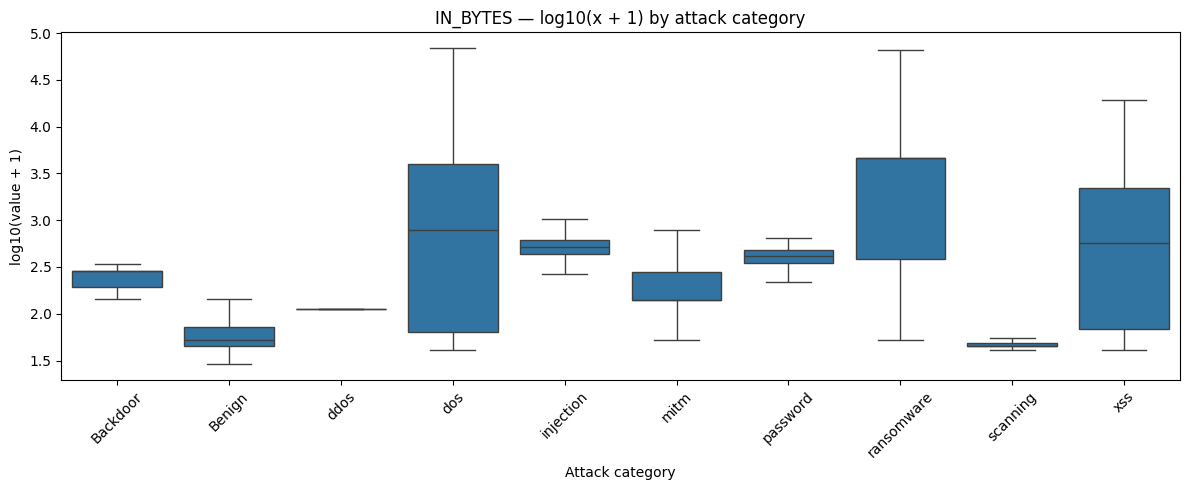

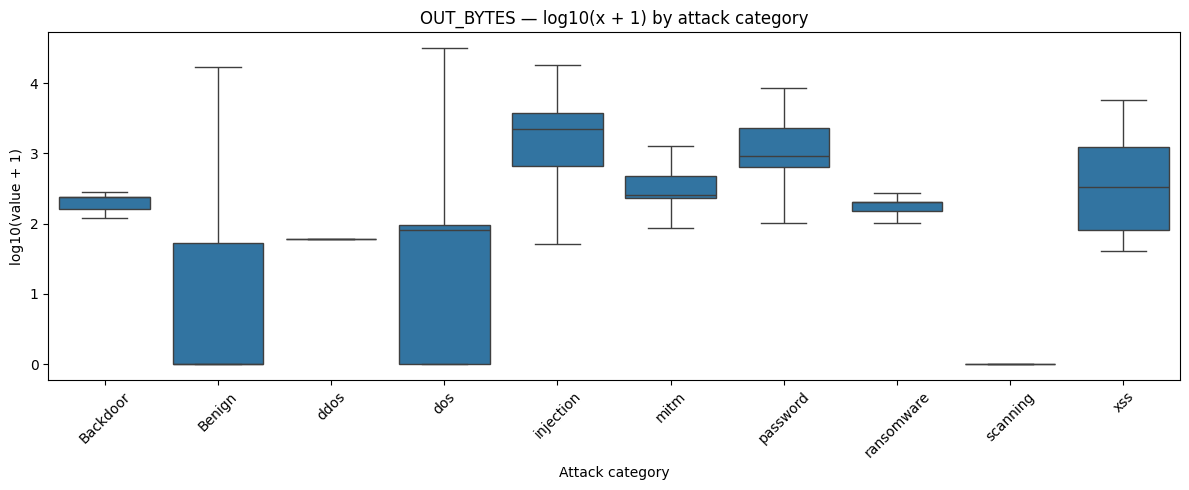

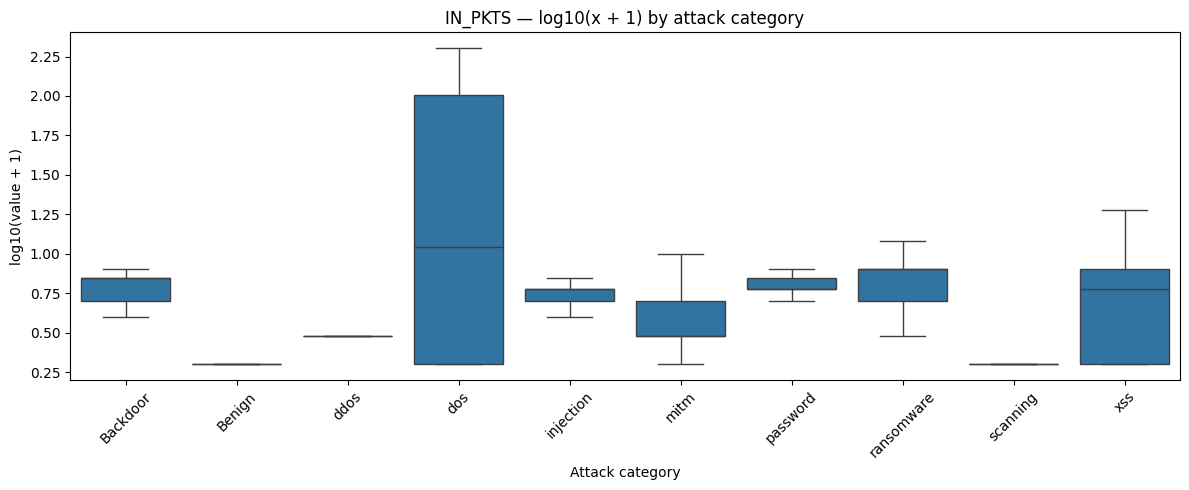

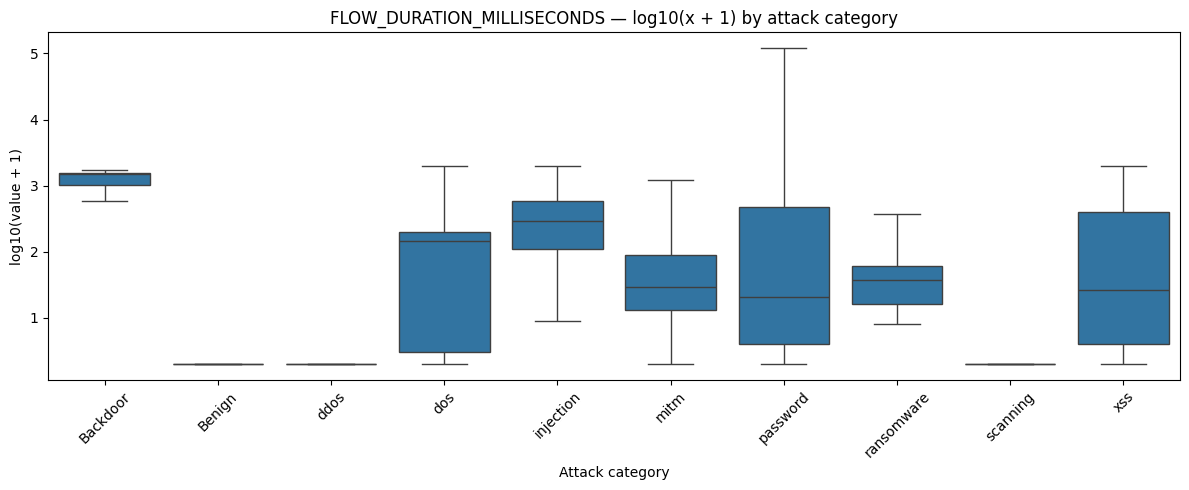

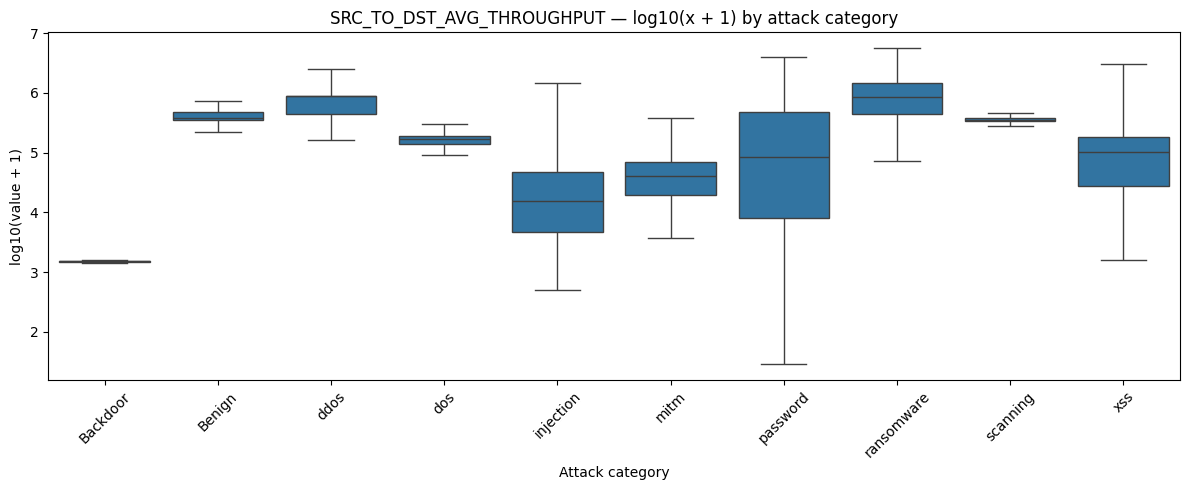

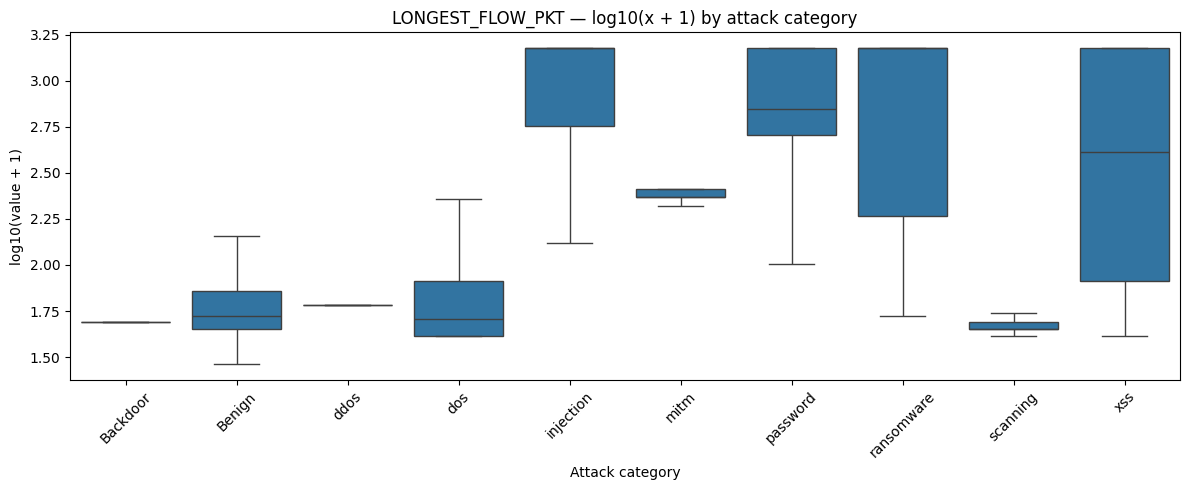

In [10]:

# STEP 6.2 — Log-scale boxplots by attack category

import matplotlib.pyplot as plt
import seaborn as sns

plot_features = [
    "IN_BYTES",
    "OUT_BYTES",
    "IN_PKTS",
    "FLOW_DURATION_MILLISECONDS",
    "SRC_TO_DST_AVG_THROUGHPUT",
    "LONGEST_FLOW_PKT"
]

# At most 20,000 records per attack category
plot_df = (
    sample_df.groupby("Attack", group_keys=False)
    .apply(
        lambda group: group.sample(
            n=min(len(group), 20_000),
            random_state=42
        )
    )
    .reset_index(drop=True)
)

for feature in plot_features:
    plt.figure(figsize=(12, 5))

    sns.boxplot(
        data=plot_df,
        x="Attack",
        y=np.log10(plot_df[feature].clip(lower=0) + 1),
        showfliers=False
    )

    plt.title(f"{feature} — log10(x + 1) by attack category")
    plt.xlabel("Attack category")
    plt.ylabel("log10(value + 1)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


In [11]:

# STEP 6.3 — Physical limits (sample-based)

checks = {
    "Longest packet (bytes)": sample_df["LONGEST_FLOW_PKT"].max(),
    "Packets above 1514 bytes": (
        sample_df["LONGEST_FLOW_PKT"] > 1514
    ).sum(),
    "Longest flow (milliseconds)": (
        sample_df["FLOW_DURATION_MILLISECONDS"].max()
    ),
    "Flows above 120 seconds": (
        sample_df["FLOW_DURATION_MILLISECONDS"] > 120_000
    ).sum(),
    "Highest source-to-destination throughput": (
        sample_df["SRC_TO_DST_AVG_THROUGHPUT"].max()
    ),
    "Largest incoming flow (bytes)": sample_df["IN_BYTES"].max(),
    "Largest outgoing flow (bytes)": sample_df["OUT_BYTES"].max(),
    "Highest DNS TTL (seconds)": sample_df["DNS_TTL_ANSWER"].max()
}

for name, value in checks.items():
    print(f"{name}: {value}")


Longest packet (bytes): 2125
Packets above 1514 bytes: 15
Longest flow (milliseconds): 120957
Flows above 120 seconds: 63
Highest source-to-destination throughput: 372400000
Largest incoming flow (bytes): 4874312
Largest outgoing flow (bytes): 12912826
Highest DNS TTL (seconds): 604800


In [12]:

# STEP 6.4 — Top 10 most skewed measurement columns

skewness = (
    sample_df[measurement_cols]
    .skew()
    .sort_values(ascending=False)
)

print("Top 10 highest skewness values:")
display(skewness.head(10).to_frame("Skewness"))


Top 10 highest skewness values:


,Skewness
NUM_PKTS_256_TO_512_BYTES,929.648747
OUT_PKTS,771.671713
RETRANSMITTED_IN_PKTS,688.422907
RETRANSMITTED_IN_BYTES,661.373381
OUT_BYTES,641.562956
IN_PKTS,609.559897
RETRANSMITTED_OUT_PKTS,559.160304
RETRANSMITTED_OUT_BYTES,530.094042
DST_TO_SRC_IAT_MIN,328.906268
NUM_PKTS_512_TO_1024_BYTES,243.708615


In [13]:

# STEP 7.1 — Near-constant columns (>99%)
# Full dataset, chunk by chunk

from collections import defaultdict, Counter
import pandas as pd

value_counts = defaultdict(Counter)
total_rows = 0

for chunk in pd.read_csv(path, chunksize=500_000):
    total_rows += len(chunk)

    for col in chunk.columns:
        # Count each distinct value across the entire dataset
        value_counts[col].update(
            chunk[col].value_counts(dropna=False).to_dict()
        )

results = []

for col, counts in value_counts.items():
    most_common_value, count = counts.most_common(1)[0]
    percentage = 100 * count / total_rows

    if percentage > 99:
        results.append({
            "Column": col,
            "Most common value": most_common_value,
            "Count": count,
            "Percentage": round(percentage, 4)
        })

near_constant = pd.DataFrame(results)

print("Total rows checked:", total_rows)
print("Near-constant columns (>99%):", len(near_constant))
display(near_constant.sort_values("Percentage", ascending=False))


Total rows checked: 27520260
Near-constant columns (>99%): 1


,Column,Most common value,Count,Percentage
0,FTP_COMMAND_RET_CODE,0,27432034,99.6794


In [14]:

# STEP 7.2 — Source IP behaviour (full dataset)

import pandas as pd

ip_status = {}

for chunk in pd.read_csv(
    path,
    usecols=["IPV4_SRC_ADDR", "Attack"],
    chunksize=500_000
):
    # 1 = Benign, 2 = Attack
    chunk_status = (
        chunk.assign(
            status=(chunk["Attack"] != "Benign").astype("uint8") + 1
        )
        .groupby("IPV4_SRC_ADDR")["status"]
        .agg(lambda x: int(
            (1 if (x == 1).any() else 0) |
            (2 if (x == 2).any() else 0)
        ))
    )

    for ip, status in chunk_status.items():
        ip_status[ip] = ip_status.get(ip, 0) | status

status_counts = pd.Series(ip_status).value_counts()

print("Total unique source IPs:", len(ip_status))
print("Only Benign:", status_counts.get(1, 0))
print("Only Attack:", status_counts.get(2, 0))
print("Both Benign and Attack:", status_counts.get(3, 0))


Total unique source IPs: 15270
Only Benign: 15244
Only Attack: 2
Both Benign and Attack: 24


In [15]:

# STEP 7.3 — Traffic distribution by hour and date

import pandas as pd

hour_counts = pd.Series(0, index=range(24), dtype="int64")
attack_hour_counts = pd.Series(0, index=range(24), dtype="int64")
date_attack_parts = []

for chunk in pd.read_csv(
    path,
    usecols=["FLOW_START_MILLISECONDS", "Attack"],
    chunksize=500_000
):
    timestamps = pd.to_datetime(
        chunk["FLOW_START_MILLISECONDS"],
        unit="ms",
        utc=True,
        errors="coerce"
    )

    hours = timestamps.dt.hour
    dates = timestamps.dt.date
    is_attack = chunk["Attack"] != "Benign"

    hour_counts = hour_counts.add(
        hours.value_counts(), fill_value=0
    ).astype("int64")

    attack_hour_counts = attack_hour_counts.add(
        hours[is_attack].value_counts(), fill_value=0
    ).astype("int64")

    date_attack_parts.append(
        pd.crosstab(dates, chunk["Attack"])
    )

date_attack = pd.concat(date_attack_parts).groupby(level=0).sum()

hour_summary = pd.DataFrame({
    "Total flows": hour_counts,
    "Attack flows": attack_hour_counts
})

hour_summary["Attack %"] = (
    100 * hour_summary["Attack flows"] /
    hour_summary["Total flows"].replace(0, float("nan"))
).round(2)

print("Hours containing traffic:",
      (hour_summary["Total flows"] > 0).sum())

print("Hours containing attacks:",
      (hour_summary["Attack flows"] > 0).sum())

print("Hours with >90% attacks:",
      (hour_summary["Attack %"] > 90).sum())

print("\nHourly summary:")
display(hour_summary)

print("\nDate × Attack crosstab:")
display(date_attack)


Hours containing traffic: 24
Hours containing attacks: 24
Hours with >90% attacks: 2

Hourly summary:


,Total flows,Attack flows,Attack %
0,1013814,512524,50.55
1,1122059,537372,47.89
2,974883,540442,55.44
3,2819111,993886,35.26
4,958003,329057,34.35
5,1440683,396538,27.52
6,1180187,823411,69.77
7,536045,460834,85.97
8,627771,548941,87.44
9,546233,487475,89.24



Date × Attack crosstab:


Attack,Benign,scanning,dos,injection,ddos,password,xss,Backdoor,ransomware,mitm
FLOW_START_MILLISECONDS,,,,,,,,,,
2019-04-23,5580827,262207.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2019-04-24,3108051,1096770.0,133307.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2019-04-25,3434087,0.0,70149.0,381777.0,2487061.0,0.0,0.0,0.0,0.0,0.0
2019-04-26,2140689,0.0,0.0,0.0,1654195.0,1032571.0,0.0,0.0,0.0,0.0
2019-04-27,354308,0.0,0.0,0.0,0.0,562206.0,2834435.0,0.0,0.0,0.0
2019-04-28,215980,0.0,0.0,0.0,0.0,0.0,0.0,109536.0,3971.0,0.0
2019-04-29,1958272,0.0,0.0,0.0,0.0,0.0,0.0,93848.0,0.0,6013.0


In [16]:

# STEP 7.4 — Highly correlated measurement features
# Sample-based analysis

import numpy as np
import pandas as pd

corr = sample_df[measurement_cols].corr().abs()

# Keep only the upper triangle to avoid duplicate pairs
upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

high_corr = (
    upper.stack()
    .reset_index()
)

high_corr.columns = ["Feature 1", "Feature 2", "Absolute correlation"]

high_corr = (
    high_corr[high_corr["Absolute correlation"] > 0.98]
    .sort_values("Absolute correlation", ascending=False)
)

print("Highly correlated feature pairs (>0.98):", len(high_corr))
display(high_corr)


Highly correlated feature pairs (>0.98): 3


,Feature 1,Feature 2,Absolute correlation
290,LONGEST_FLOW_PKT,MAX_IP_PKT_LEN,1.000000
231,MIN_TTL,MAX_TTL,0.999644
138,FLOW_DURATION_MILLISECONDS,DURATION_IN,0.995203


In [17]:

# STEP 7.4 — Verify ICMP relationship (full dataset)

import pandas as pd

total_rows = 0
mismatches = 0
examples = []

for chunk in pd.read_csv(
    path,
    usecols=["ICMP_IPV4_TYPE", "ICMP_TYPE"],
    chunksize=500_000
):
    expected = chunk["ICMP_TYPE"] // 256
    invalid = chunk["ICMP_IPV4_TYPE"] != expected

    total_rows += len(chunk)
    mismatches += int(invalid.sum())

    if len(examples) < 5:
        bad = chunk.loc[invalid].head(5 - len(examples))
        examples.extend(bad.to_dict("records"))

print("Total rows checked:", total_rows)
print("ICMP relationship mismatches:", mismatches)
print("Example mismatches:", examples)


Total rows checked: 27520260
ICMP relationship mismatches: 0
Example mismatches: []


In [18]:

# STEP 7.5 — MAX_TTL distribution by label (full dataset)

import pandas as pd

ttl_parts = []

for chunk in pd.read_csv(
    path,
    usecols=["MAX_TTL", "Attack"],
    chunksize=500_000
):
    ttl_parts.append(
        pd.crosstab(chunk["MAX_TTL"], chunk["Attack"])
    )

ttl_table = pd.concat(ttl_parts).groupby(level=0).sum().astype("int64")

benign = ttl_table.get("Benign", pd.Series(0, index=ttl_table.index))
attacks = ttl_table.drop(columns=["Benign"], errors="ignore").sum(axis=1)

only_benign = ttl_table.index[(benign > 0) & (attacks == 0)].tolist()
only_attacks = ttl_table.index[(benign == 0) & (attacks > 0)].tolist()
both = ttl_table.index[(benign > 0) & (attacks > 0)].tolist()

print("TTL values only in Benign:", only_benign)
print("TTL values only in attacks:", only_attacks)
print("TTL values in both:", len(both))

print("\nTop 10 TTL values in Benign:")
display(benign.sort_values(ascending=False).head(10).to_frame("Benign flows"))

print("\nTop 10 TTL values in attacks:")
display(attacks.sort_values(ascending=False).head(10).to_frame("Attack flows"))

print("\nMAX_TTL × Attack crosstab:")
display(ttl_table)


TTL values only in Benign: [2, 4, 10, 20, 22, 32, 34, 35, 36, 37, 38, 39, 40, 41, 43, 44, 45, 46, 48, 51, 52, 53, 54, 56, 58, 59, 60, 61, 63, 82, 99, 100, 101, 102, 104, 106, 107, 108, 109, 110, 111, 112, 113, 115, 116, 117, 122, 123, 126, 127, 222, 226, 227, 228, 229, 230, 231, 232, 235, 236, 237, 238, 240, 241, 242, 244, 245, 246, 247, 249, 250, 251, 252, 253]
TTL values only in attacks: [14, 71, 124, 140, 172, 185]
TTL values in both: 14

Top 10 TTL values in Benign:


,Benign flows
MAX_TTL,
0,15379611
64,943335
128,174974
1,54325
237,32302
235,18821
59,17079
4,14670
58,14642



Top 10 TTL values in attacks:


,Attack flows
MAX_TTL,
64,7308874
0,3112795
128,190933
71,52002
234,50640
14,8724
114,2313
185,1577
140,97



MAX_TTL × Attack crosstab:


Attack,Benign,scanning,dos,injection,ddos,password,xss,Backdoor,ransomware,mitm
MAX_TTL,,,,,,,,,,
0,15379611,1305096,98562,22584,326201,70238,1275607,12608,566,1333
1,54325,14,0,0,0,0,0,0,0,0
2,77,0,0,0,0,0,0,0,0,0
4,14670,0,0,0,0,0,0,0,0,0
10,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
250,1,0,0,0,0,0,0,0,0,0
251,1507,0,0,0,0,0,0,0,0,0
252,1,0,0,0,0,0,0,0,0,0


## Additional checks *(added from Ahmed Hamouda's analysis)*

These sections close the checklist gaps of this notebook so that it covers every check of the shared Steps 0–8. They keep the section numbers used in `report/data_problems/phase2_data_problems.pdf`. They run **locally from the repository** (`notebooks/`, data in `data/raw/`, shared functions from `src/config.py`), not in Colab; the outputs shown were computed on the full dataset.

### 0.1 Load the data *(added from Ahmed Hamouda's analysis)*

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pv
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import *

pd.set_option("display.max_columns", 100)

SOURCE = "ToN"
path = RAW_DIR / DATASETS[SOURCE]["file"]

# Large file: integer columns are read as int32 instead of int64, which halves the memory.
# Every value fits (pyarrow stops with an error if one does not); only the timestamps need int64.
header = pd.read_csv(path, nrows=0).columns
types = {c: pa.int32() for c in header if c not in ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "Attack"]}
types["FLOW_START_MILLISECONDS"] = types["FLOW_END_MILLISECONDS"] = pa.int64()
# These three columns hold decimals in some NetFlow files (UNSW, BoT-IoT): read them as float64 (see 0.4)
for c in ["L7_PROTO", "SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]:
    types[c] = pa.float64()
table = pv.read_csv(path, convert_options=pv.ConvertOptions(column_types=types))
df = table.to_pandas(self_destruct=True)
del table

print("rows:", len(df), "(official: 27,520,260)")
print("columns:", df.shape[1])
print(f"memory: {df.memory_usage(deep=True).sum() / 1e9:.1f} GB")

rows: 27520260 (official: 27,520,260)
columns: 55
memory: 7.8 GB


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27520260 entries, 0 to 27520259
Data columns (total 55 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   FLOW_START_MILLISECONDS      int64  
 1   FLOW_END_MILLISECONDS        int64  
 2   IPV4_SRC_ADDR                str    
 3   L4_SRC_PORT                  int32  
 4   IPV4_DST_ADDR                str    
 5   L4_DST_PORT                  int32  
 6   PROTOCOL                     int32  
 7   L7_PROTO                     float64
 8   IN_BYTES                     int32  
 9   IN_PKTS                      int32  
 10  OUT_BYTES                    int32  
 11  OUT_PKTS                     int32  
 12  TCP_FLAGS                    int32  
 13  CLIENT_TCP_FLAGS             int32  
 14  SERVER_TCP_FLAGS             int32  
 15  FLOW_DURATION_MILLISECONDS   int32  
 16  DURATION_IN                  int32  
 17  DURATION_OUT                 int32  
 18  MIN_TTL                      int32  
 19  MAX_TTL  

### 0.4 Same columns as the other NetFlow datasets? *(added from Ahmed Hamouda's analysis)*
The four NetFlow datasets are merged later, so they must have the same columns, in the same order and with
compatible types. Types are inferred by pyarrow from the raw CSV text (first 64 MB of each file).

In [6]:
def raw_types(file):
    with pv.open_csv(RAW_DIR / file, read_options=pv.ReadOptions(block_size=64 << 20)) as reader:
        return pd.Series({field.name: str(field.type) for field in reader.schema})

netflow = ["UNSW", "CIC18", "ToN", "BoT"]
types_all = pd.DataFrame({s: raw_types(DATASETS[s]["file"]) for s in netflow})
orders = {s: list(raw_types(DATASETS[s]["file"]).index) for s in netflow}

print("same column names in all 4:", all(set(orders[s]) == set(orders["UNSW"]) for s in netflow))
print("same order in all 4:       ", all(orders[s] == orders["UNSW"] for s in netflow))
types_all[types_all.nunique(axis=1) > 1]

same column names in all 4: True
same order in all 4:        True


,UNSW,CIC18,ToN,BoT
L7_PROTO,double,int64,int64,double
SRC_TO_DST_SECOND_BYTES,double,int64,int64,double
DST_TO_SRC_SECOND_BYTES,double,int64,int64,double


### 1.3 Are all labels in the team taxonomy? *(added from Ahmed Hamouda's analysis)*
`map_labels` (from `src/config.py`) stops with an error if a label is missing from the shared taxonomy.

In [10]:
try:
    map_labels(df[["Attack"]].drop_duplicates(), "Attack", SOURCE)
    print("all labels are in the taxonomy")
except ValueError as error:
    print(error)

all labels are in the taxonomy


**Mapping of every label** to the shared taxonomy, with the number of flows per label and per family.

In [11]:
try:
    mapped = map_labels(df[["Attack"]].drop_duplicates(), "Attack", SOURCE).set_index("Attack")[["attack_label", "attack_family"]]
    mapping = mapped.join(df["Attack"].value_counts().rename("flows")).sort_values(["attack_family", "flows"], ascending=[True, False])
    display(mapping)
    display(mapping.groupby("attack_family")["flows"].sum().sort_values(ascending=False))
except ValueError as error:
    print(error)

,attack_label,attack_family,flows
Attack,,,
Benign,Benign,Benign,16792214
password,Password,Credential attacks,1594777
ddos,DDoS,Denial of service,4141256
dos,DoS,Denial of service,203456
mitm,MITM,Interception and spoofing,6013
Backdoor,Backdoor,Malware and botnets,203384
ransomware,Ransomware,Malware and botnets,3971
scanning,Scanning,Reconnaissance,1358977
xss,XSS,Web and injection,2834435


attack_family
Benign                       16792214
Denial of service             4344712
Web and injection             3216212
Credential attacks            1594777
Reconnaissance                1358977
Malware and botnets            207355
Interception and spoofing        6013
Name: flows, dtype: int64

### 1.4 Class distribution *(added from Ahmed Hamouda's analysis)*

In [12]:
distribution = pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "percent": (100 * df["Attack"].value_counts(normalize=True)).round(3),
})
distribution

,flows,percent
Attack,,
Benign,16792214,61.018
ddos,4141256,15.048
xss,2834435,10.299
password,1594777,5.795
scanning,1358977,4.938
injection,381777,1.387
dos,203456,0.739
Backdoor,203384,0.739
mitm,6013,0.022


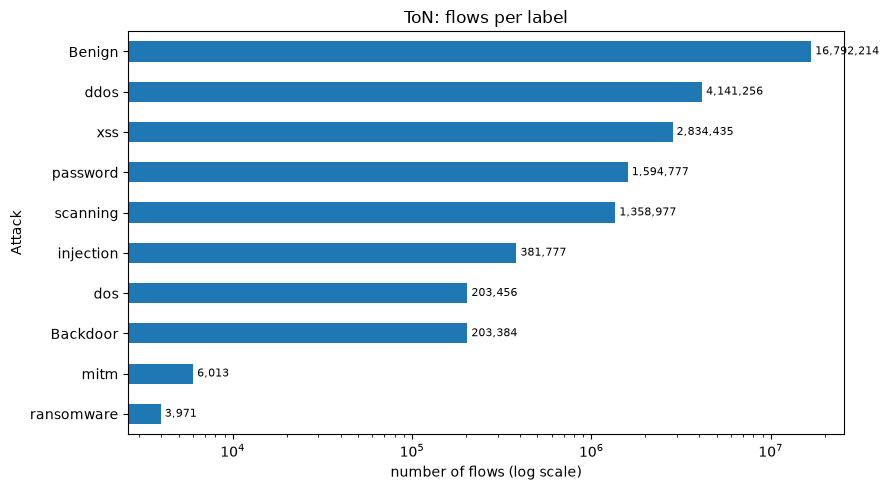

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
distribution["flows"].sort_values().plot.barh(ax=ax)
ax.set_xscale("log")
ax.set_xlabel("number of flows (log scale)")
ax.set_title(f"{SOURCE}: flows per label")
for i, v in enumerate(distribution["flows"].sort_values()):
    ax.text(v, i, f" {v:,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

### 2.1 Columns stored as text *(added from Ahmed Hamouda's analysis)*
Are there text columns that actually contain numbers?

In [14]:
text_cols = df.select_dtypes(exclude="number").columns
for col in text_cols:
    as_number = pd.to_numeric(df[col], errors="coerce")
    print(f"{col:15s} distinct: {df[col].nunique():>9,}   values that are numbers: {as_number.notna().sum():,}")

IPV4_SRC_ADDR   distinct:    15,270   values that are numbers: 0


IPV4_DST_ADDR   distinct:     8,777   values that are numbers: 0


Attack          distinct:        10   values that are numbers: 0


### 2.2 Timestamps stored as integers *(added from Ahmed Hamouda's analysis)*
`FLOW_START_MILLISECONDS` and `FLOW_END_MILLISECONDS` are milliseconds since 1 January 1970. Converted here only to check that the dates are plausible.

In [15]:
start = pd.to_datetime(df["FLOW_START_MILLISECONDS"], unit="ms")
end = pd.to_datetime(df["FLOW_END_MILLISECONDS"], unit="ms")
print("first flow starts:", start.min())
print("last flow ends:   ", end.max())

first flow starts: 2019-04-23 14:09:50.618000
last flow ends:    2019-04-29 14:45:55.861000


In [16]:
# Flows per capture day
start.dt.date.value_counts().sort_index()

FLOW_START_MILLISECONDS
2019-04-23    5843034
2019-04-24    4338128
2019-04-25    6373074
2019-04-26    4827455
2019-04-27    3750949
2019-04-28     329487
2019-04-29    2058133
Name: count, dtype: int64

### 2.3 Codes stored as numbers *(added from Ahmed Hamouda's analysis)*
These columns hold identifiers of a protocol, port, flag or message type. Their numbers have no order or size: an average port or protocol has no meaning.

In [17]:
code_cols = ["L4_SRC_PORT", "L4_DST_PORT", "PROTOCOL", "L7_PROTO",
             "TCP_FLAGS", "CLIENT_TCP_FLAGS", "SERVER_TCP_FLAGS",
             "ICMP_TYPE", "ICMP_IPV4_TYPE", "DNS_QUERY_TYPE", "FTP_COMMAND_RET_CODE"]

pd.DataFrame({
    "dtype": df[code_cols].dtypes.astype(str),
    "distinct values": df[code_cols].nunique(),
    "most common": [df[c].mode()[0] for c in code_cols],
})

,dtype,distinct values,most common
L4_SRC_PORT,int32,65536,443.0
L4_DST_PORT,int32,65536,80.0
PROTOCOL,int32,5,6.0
L7_PROTO,float64,133,0.0
TCP_FLAGS,int32,26,2.0
CLIENT_TCP_FLAGS,int32,25,2.0
SERVER_TCP_FLAGS,int32,20,0.0
ICMP_TYPE,int32,359,0.0
ICMP_IPV4_TYPE,int32,256,0.0
DNS_QUERY_TYPE,int32,13,0.0


**TCP flag values above 31.** Besides FIN, SYN, RST, PSH and ACK (1–31), TCP has two congestion flags: ECE = 64 and CWR = 128.

In [18]:
high_flags = df["TCP_FLAGS"] > 31
print(f"flows with ECE/CWR flags: {high_flags.sum():,} ({100 * high_flags.mean():.1f} %)")
(100 * high_flags.groupby(df["Attack"]).mean()).round(1).sort_values(ascending=False).rename("% of class")

flows with ECE/CWR flags: 7,290 (0.0 %)


Attack
Backdoor      0.0
Benign        0.0
ddos          0.0
dos           0.0
injection     0.0
mitm          0.0
password      0.0
ransomware    0.0
scanning      0.0
xss           0.0
Name: % of class, dtype: float64

**Protocol numbers present**

In [19]:
protocols = pd.crosstab(df["PROTOCOL"], df["Label"]).rename(columns={0: "benign", 1: "attack"})
protocols["name"] = protocols.index.map({1: "ICMP", 2: "IGMP", 6: "TCP", 17: "UDP", 47: "GRE", 58: "ICMPv6"})
protocols

Label,benign,attack,name
PROTOCOL,,,
1,215377,0,ICMP
2,24847,0,IGMP
6,13608306,9267685,TCP
17,2942429,1460361,UDP
58,1255,0,ICMPv6


### 2.4 `L7_PROTO` stored as a float *(added from Ahmed Hamouda's analysis)*
A value like `7.37` is two codes in one: the outer protocol (7 = HTTP) and the application inside it (37 = BitTorrent).

In [20]:
has_decimals = df["L7_PROTO"] % 1 != 0
print(f"flows with a decimal L7_PROTO: {has_decimals.sum():,} ({100 * has_decimals.mean():.2f} %)")
df.loc[has_decimals, "L7_PROTO"].value_counts()

flows with a decimal L7_PROTO: 0 (0.00 %)


Series([], Name: count, dtype: int64)

### 2.5 Invalid codes *(added from Ahmed Hamouda's analysis)*
Codes that do not exist in the official lists:
- **Protocol numbers:** IANA has assigned 0–147; 148–252 are unassigned, 253–254 are for experiments and 255 is reserved.
- **Port 0:** reserved and never used by real TCP/UDP traffic. Other protocols have no ports, so 0 is normal there.
- **DNS query types:** only the types assigned by IANA are valid.
- **ICMP types:** only the types assigned by IANA are valid. Checked on ICMP flows only.

In [21]:
unassigned_proto = df["PROTOCOL"] > 147
print(f"flows with an unassigned protocol number: {unassigned_proto.sum():,}")
print(f"distinct unassigned protocol numbers:     {df.loc[unassigned_proto, 'PROTOCOL'].nunique()}")
df.loc[unassigned_proto, "Attack"].value_counts()

flows with an unassigned protocol number: 0
distinct unassigned protocol numbers:     0


Series([], Name: count, dtype: int64)

In [22]:
tcp_udp = df["PROTOCOL"].isin([6, 17])
port0 = tcp_udp & ((df["L4_SRC_PORT"] == 0) | (df["L4_DST_PORT"] == 0))
print(f"TCP/UDP flows using port 0: {port0.sum():,}")
df.loc[port0, "Attack"].value_counts()

TCP/UDP flows using port 0: 4,782


Attack
Benign      4491
scanning     291
Name: count, dtype: int64

In [23]:
# IANA DNS record types: 1-260 are the standard range, 32768-32769 are DNSSEC-related
dns = df["DNS_QUERY_TYPE"]
invalid_dns = (dns != 0) & ~(dns.between(1, 260) | dns.isin([32768, 32769]))
print(f"flows with an invalid DNS query type: {invalid_dns.sum()}")
df.loc[invalid_dns, ["L4_DST_PORT", "DNS_QUERY_TYPE", "Attack"]]

flows with an invalid DNS query type: 1


,L4_DST_PORT,DNS_QUERY_TYPE,Attack
8205351,53,11828,Benign


In [24]:
# IANA ICMP types still in use
valid_icmp = [0, 3, 4, 5, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 30, 40, 41, 42, 43]
icmp = df["PROTOCOL"] == 1
invalid_icmp = icmp & ~df["ICMP_IPV4_TYPE"].isin(valid_icmp)
print(f"ICMP flows: {icmp.sum()}, with an invalid ICMP type: {invalid_icmp.sum()}")
df.loc[invalid_icmp, ["ICMP_TYPE", "ICMP_IPV4_TYPE", "Attack"]].value_counts()

ICMP flows: 215377, with an invalid ICMP type: 17


ICMP_TYPE  ICMP_IPV4_TYPE  Attack
9472       37              Benign    17
Name: count, dtype: int64

### 3.2 Infinite values *(added from Ahmed Hamouda's analysis)*

In [26]:
float_cols = df.select_dtypes("float").columns
print("float columns:", list(float_cols) or "none (integer columns cannot hold inf or NaN)")
inf_count = np.isinf(df[float_cols]).sum() if len(float_cols) else pd.Series(dtype=int)
pd.DataFrame({"infinite": inf_count, "percent": (100 * inf_count / len(df)).round(3)})[inf_count > 0]

float columns: ['L7_PROTO', 'SRC_TO_DST_SECOND_BYTES', 'DST_TO_SRC_SECOND_BYTES']


,infinite,percent


### 3.3 Where do the NaN and inf come from? *(added from Ahmed Hamouda's analysis)*
The two `..._SECOND_BYTES` columns are a division by the flow duration, so a duration of 0 is the first suspect.
We also check which byte column each one is actually computed from.

In [27]:
zero_duration = df["FLOW_DURATION_MILLISECONDS"] == 0
s2d, d2s = df["SRC_TO_DST_SECOND_BYTES"], df["DST_TO_SRC_SECOND_BYTES"]

print(f"flows with duration 0: {zero_duration.sum():,}")
pd.DataFrame({
    "duration = 0": [s2d[zero_duration].isna().sum(), np.isinf(s2d[zero_duration]).sum(), np.isinf(d2s[zero_duration]).sum()],
    "duration > 0": [s2d[~zero_duration].isna().sum(), np.isinf(s2d[~zero_duration]).sum(), np.isinf(d2s[~zero_duration]).sum()],
}, index=["SRC_TO_DST_SECOND_BYTES NaN", "SRC_TO_DST_SECOND_BYTES inf", "DST_TO_SRC_SECOND_BYTES inf"])

flows with duration 0: 0

,duration = 0,duration > 0
SRC_TO_DST_SECOND_BYTES NaN,0,0
SRC_TO_DST_SECOND_BYTES inf,0,0
DST_TO_SRC_SECOND_BYTES inf,0,0


In [28]:
# Which formula reproduces each column? (share of flows with duration > 0 that match)
ok = ~zero_duration
duration_ms = df.loc[ok, "FLOW_DURATION_MILLISECONDS"]
formulas = pd.DataFrame({
    col: {
        "IN_BYTES / duration (ms)": np.isclose(df.loc[ok, col], df.loc[ok, "IN_BYTES"] / duration_ms, rtol=1e-3).mean(),
        "OUT_BYTES / duration (ms)": np.isclose(df.loc[ok, col], df.loc[ok, "OUT_BYTES"] / duration_ms, rtol=1e-3).mean(),
        "IN_BYTES / duration (s)": np.isclose(df.loc[ok, col], df.loc[ok, "IN_BYTES"] / (duration_ms / 1000), rtol=1e-3).mean(),
    }
    for col in ["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]
})
(100 * formulas).round(2)

,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES
IN_BYTES / duration (ms),1.51,6.19
OUT_BYTES / duration (ms),50.01,38.80
IN_BYTES / duration (s),0.00,0.00


In [29]:
# The values are integers here: test the formulas with the decimals cut off (floor)
pd.DataFrame({
    col: {
        "floor(IN_BYTES / duration ms)": (np.floor(df["IN_BYTES"] / df["FLOW_DURATION_MILLISECONDS"]) == df[col]).mean(),
        "floor(OUT_BYTES / duration ms)": (np.floor(df["OUT_BYTES"] / df["FLOW_DURATION_MILLISECONDS"]) == df[col]).mean(),
        "share of zeros": (df[col] == 0).mean(),
    }
    for col in ["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]
}).mul(100).round(1)

,SRC_TO_DST_SECOND_BYTES,DST_TO_SRC_SECOND_BYTES
floor(IN_BYTES / duration ms),12.2,33.7
floor(OUT_BYTES / duration ms),74.6,47.9
share of zeros,72.0,56.8


In [30]:
# NaN rows: what do they have in common?
if s2d.isna().any():
    display(df.loc[s2d.isna(), ["IN_PKTS", "OUT_PKTS", "OUT_BYTES", "FLOW_DURATION_MILLISECONDS"]].describe().loc[["min", "max"]])
else:
    print("no NaN to describe")

no NaN to describe


### 3.4 Is the missingness linked to the attack class? *(added from Ahmed Hamouda's analysis)*

In [31]:
missing_by_class = pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "NaN or inf (%)": (100 * (s2d.isna() | np.isinf(s2d) | np.isinf(d2s)).groupby(df["Attack"]).mean()).round(2),
}).sort_values("NaN or inf (%)", ascending=False)
missing_by_class

,flows,NaN or inf (%)
Attack,,
Backdoor,203384,0.0
Benign,16792214,0.0
ddos,4141256,0.0
dos,203456,0.0
injection,381777,0.0
mitm,6013,0.0
password,1594777,0.0
ransomware,3971,0.0
scanning,1358977,0.0


### 3.5 Visualisation *(added from Ahmed Hamouda's analysis)*

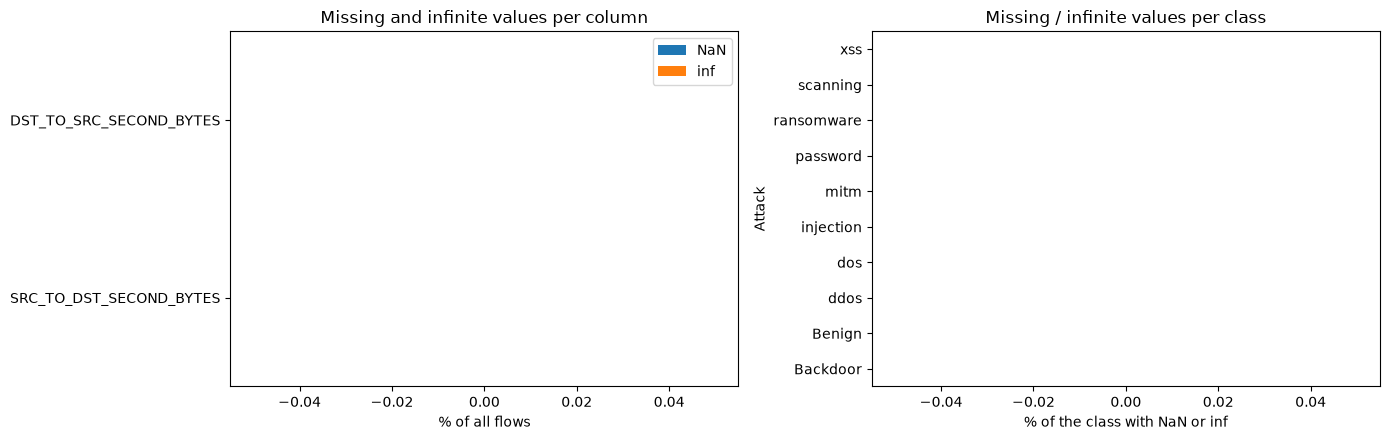

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

pd.DataFrame({
    "NaN": 100 * df[["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]].isna().mean(),
    "inf": 100 * np.isinf(df[["SRC_TO_DST_SECOND_BYTES", "DST_TO_SRC_SECOND_BYTES"]]).mean(),
}).plot.barh(stacked=True, ax=axes[0])
axes[0].set_xlabel("% of all flows")
axes[0].set_title("Missing and infinite values per column")

missing_by_class["NaN or inf (%)"].sort_values().plot.barh(ax=axes[1], color="indianred")
axes[1].set_xlabel("% of the class with NaN or inf")
axes[1].set_title("Missing / infinite values per class")
plt.tight_layout()
plt.show()

### 3.6 Disguised missing values *(added from Ahmed Hamouda's analysis)*
A value of 0 can mean "does not apply" (no DNS query in a web flow) or "not recorded". Each protocol-specific
field should only be filled for its own protocol.

In [33]:
is_dns = (df["L4_DST_PORT"] == 53) | (df["L4_SRC_PORT"] == 53) | (df["L7_PROTO"].astype(int) == 5)
is_ftp = (df["L4_DST_PORT"] == 21) | (df["L4_SRC_PORT"] == 21) | (df["L7_PROTO"].astype(int) == 1)
is_icmp = df["PROTOCOL"] == 1
is_tcp = df["PROTOCOL"] == 6

pd.DataFrame([
    ["DNS_QUERY_TYPE", "DNS flows", is_dns.sum(), (is_dns & (df["DNS_QUERY_TYPE"] == 0)).sum(), (~is_dns & (df["DNS_QUERY_TYPE"] != 0)).sum()],
    ["DNS_TTL_ANSWER", "DNS flows", is_dns.sum(), (is_dns & (df["DNS_TTL_ANSWER"] == 0)).sum(), (~is_dns & (df["DNS_TTL_ANSWER"] != 0)).sum()],
    ["FTP_COMMAND_RET_CODE", "FTP flows", is_ftp.sum(), (is_ftp & (df["FTP_COMMAND_RET_CODE"] == 0)).sum(), (~is_ftp & (df["FTP_COMMAND_RET_CODE"] != 0)).sum()],
    ["ICMP_TYPE", "ICMP flows", is_icmp.sum(), (is_icmp & (df["ICMP_TYPE"] == 0)).sum(), (~is_icmp & (df["ICMP_TYPE"] != 0)).sum()],
    ["ICMP_IPV4_TYPE", "ICMP flows", is_icmp.sum(), (is_icmp & (df["ICMP_IPV4_TYPE"] == 0)).sum(), (~is_icmp & (df["ICMP_IPV4_TYPE"] != 0)).sum()],
    ["TCP_FLAGS", "TCP flows", is_tcp.sum(), (is_tcp & (df["TCP_FLAGS"] == 0)).sum(), (~is_tcp & (df["TCP_FLAGS"] != 0)).sum()],
    ["TCP_WIN_MAX_IN", "TCP flows", is_tcp.sum(), (is_tcp & (df["TCP_WIN_MAX_IN"] == 0)).sum(), (~is_tcp & (df["TCP_WIN_MAX_IN"] != 0)).sum()],
], columns=["column", "applies to", "flows it applies to", "0 where it applies", "filled where it does NOT apply"])

,column,applies to,flows it applies to,0 where it applies,filled where it does NOT apply
0,DNS_QUERY_TYPE,DNS flows,4244443,12410,13055
1,DNS_TTL_ANSWER,DNS flows,4244443,3117017,11
2,FTP_COMMAND_RET_CODE,FTP flows,222989,134763,0
3,ICMP_TYPE,ICMP flows,215377,508,430546
4,ICMP_IPV4_TYPE,ICMP flows,215377,508,430541
5,TCP_FLAGS,TCP flows,22875991,1,0
6,TCP_WIN_MAX_IN,TCP flows,22875991,545492,0


In [34]:
# Which protocol carries the ICMP values that should not be there?
df.loc[~is_icmp & (df["ICMP_TYPE"] != 0), "PROTOCOL"].value_counts()

PROTOCOL
6     429291
58      1255
Name: count, dtype: int64

**DNS fields outside DNS.** Which ports and application protocols carry them?

In [35]:
outside_dns = ~is_dns & (df["DNS_QUERY_TYPE"] != 0)
print(f"flows with a DNS query type outside DNS: {outside_dns.sum():,}")
print("destination ports:", dict(df.loc[outside_dns, "L4_DST_PORT"].value_counts().head(3)))
print("L7_PROTO:         ", dict(df.loc[outside_dns, "L7_PROTO"].value_counts().head(3)))

flows with a DNS query type outside DNS: 13,055
destination ports: {5355: np.int64(13044), 53936: np.int64(1), 60646: np.int64(1)}
L7_PROTO:          {154.0: np.int64(13055)}


**ICMP fields on protocol 58.** Protocol 58 is ICMPv6, so ICMP types are legitimate there.

In [36]:
df.loc[df["PROTOCOL"] == 58, "ICMP_IPV4_TYPE"].value_counts().rename("ICMPv6 type (143 = MLDv2 report, 135 = neighbour solicitation)")

ICMP_IPV4_TYPE
135    643
143    502
133     57
134     51
136      2
Name: ICMPv6 type (143 = MLDv2 report, 135 = neighbour solicitation), dtype: int64

In [37]:
# TTL = 0: a packet with TTL 0 is discarded by the network, so 0 means "not recorded"
ttl0 = df["MIN_TTL"] == 0
print(f"flows with MIN_TTL = 0: {ttl0.sum():,}   with MAX_TTL = 0: {(df['MAX_TTL'] == 0).sum():,}")
print("by protocol:", dict(df.loc[ttl0, "PROTOCOL"].value_counts().head(3)))
print("by class:   ", dict(df.loc[ttl0, "Attack"].value_counts()))

flows with MIN_TTL = 0: 18,492,406   with MAX_TTL = 0: 18,492,406


by protocol: {6: np.int64(14248755), 17: np.int64(4173410), 1: np.int64(59439)}


by class:    {'Benign': np.int64(15379611), 'scanning': np.int64(1305096), 'xss': np.int64(1275607), 'ddos': np.int64(326201), 'dos': np.int64(98562), 'password': np.int64(70238), 'injection': np.int64(22584), 'Backdoor': np.int64(12608), 'mitm': np.int64(1333), 'ransomware': np.int64(566)}


In [38]:
# Share of each class with TTL = 0
(100 * ttl0.groupby(df["Attack"]).mean()).round(1).sort_values(ascending=False).rename("% with TTL = 0")

Attack
scanning      96.0
Benign        91.6
dos           48.4
xss           45.0
mitm          22.2
ransomware    14.3
ddos           7.9
Backdoor       6.2
injection      5.9
password       4.4
Name: % with TTL = 0, dtype: float64

### 5.4 Same behaviour, different label *(added from Ahmed Hamouda's analysis)*
Identifiers that do not describe behaviour (IP addresses, source port, timestamps, DNS query ID) are left out.
If the remaining behaviour is identical but the labels differ, no model can tell these flows apart.

In [50]:
behaviour_cols = [c for c in df.columns if c not in
                  ["IPV4_SRC_ADDR", "IPV4_DST_ADDR", "L4_SRC_PORT", "FLOW_START_MILLISECONDS",
                   "FLOW_END_MILLISECONDS", "DNS_QUERY_ID", "Label", "Attack"]]
behaviour = pd.util.hash_pandas_object(df[behaviour_cols], index=False)
labels_per_behaviour = df.groupby(behaviour)["Attack"].nunique()
conflict = behaviour.isin(labels_per_behaviour.index[labels_per_behaviour > 1])
binary_conflict = df[conflict].groupby(behaviour[conflict])["Label"].nunique().gt(1).sum()

print(f"rows with conflicting labels: {conflict.sum():,} in {behaviour[conflict].nunique():,} behaviour groups")
print(f"groups mixing Benign and attack: {binary_conflict}")
pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "conflicting": df.loc[conflict, "Attack"].value_counts(),
}).fillna(0).astype(int).assign(percent=lambda t: (100 * t["conflicting"] / t["flows"]).round(2)).sort_values("percent", ascending=False)

rows with conflicting labels: 13,543,510 in 184,757 behaviour groups
groups mixing Benign and attack: 173777


,flows,conflicting,percent
Attack,,,
scanning,1358977,1281283,94.28
ddos,4141256,3215934,77.66
dos,203456,89801,44.14
Benign,16792214,7216886,42.98
xss,2834435,1162598,41.02
password,1594777,533078,33.43
injection,381777,40474,10.60
mitm,6013,567,9.43
ransomware,3971,357,8.99


In [51]:
# The three largest groups of identical behaviour with different labels
for group in behaviour[conflict].value_counts().index[:3]:
    rows = df[behaviour == group]
    first = rows.iloc[0]
    print(f"protocol {first['PROTOCOL']}, dst port {first['L4_DST_PORT']}, {first['IN_PKTS']} packets / {first['IN_BYTES']} bytes, "
          f"reply packets {first['OUT_PKTS']} ->", dict(rows["Attack"].value_counts()))

protocol 6, dst port 443, 2 packets / 112 bytes, reply packets 1 -> {'ddos': np.int64(1671924), 'injection': np.int64(695), 'Benign': np.int64(33), 'xss': np.int64(2)}


protocol 6, dst port 80, 2 packets / 112 bytes, reply packets 1 -> {'ddos': np.int64(899037), 'Benign': np.int64(4184), 'injection': np.int64(2344), 'xss': np.int64(557), 'password': np.int64(14)}


protocol 6, dst port 443, 1 packets / 44 bytes, reply packets 0 -> {'scanning': np.int64(265628), 'Benign': np.int64(40544)}


**Which labels are mixed together?**

In [52]:
conflict_labels = (df.loc[conflict].groupby(behaviour[conflict])["Attack"]
                   .agg(lambda s: " + ".join(sorted(s.unique()))))
group_size = behaviour[conflict].value_counts()
pd.DataFrame({"labels": conflict_labels, "rows": group_size.reindex(conflict_labels.index)}) \
  .groupby("labels")["rows"].agg(groups="count", rows="sum").sort_values("rows", ascending=False).head(12)

,groups,rows
labels,,
Benign + scanning,151621,7851265
Benign + ddos + injection + xss,172,2157114
Benign + ddos + injection + password + xss,17,988204
Benign + password,6800,596129
Benign + ddos,603,554550
Benign + injection + password + xss,126,352241
Benign + ddos + injection,39,187950
Benign + injection + xss,536,152822
Benign + xss,7537,147774


**Attack flows whose behaviour also appears as Benign**

In [53]:
benign_behaviour = set(behaviour[df["Attack"] == "Benign"])
same_as_benign = behaviour.isin(benign_behaviour) & (df["Attack"] != "Benign")
pd.DataFrame({
    "flows": df["Attack"].value_counts(),
    "identical to a Benign flow": df.loc[same_as_benign, "Attack"].value_counts(),
}).fillna(0).astype(int).query("`identical to a Benign flow` > 0") \
  .assign(percent=lambda t: (100 * t["identical to a Benign flow"] / t["flows"]).round(1),
          left_if_removed=lambda t: t["flows"] - t["identical to a Benign flow"])

,flows,identical to a Benign flow,percent,left_if_removed
Attack,,,,
Backdoor,203384,2530,1.2,200854
ddos,4141256,3160296,76.3,980960
dos,203456,67354,33.1,136102
injection,381777,28752,7.5,353025
mitm,6013,508,8.4,5505
password,1594777,531206,33.3,1063571
ransomware,3971,355,8.9,3616
scanning,1358977,1281266,94.3,77711
xss,2834435,1046970,36.9,1787465


**What do the flows of each attack label look like?** A label with only one or two distinct behaviours, or
whose most common behaviour is a refused or empty connection, may be mislabelled (as SlowHTTPTest in CIC-2018).

In [54]:
profile = []
for label in df.loc[df["Label"] == 1, "Attack"].unique():
    in_label = df["Attack"] == label
    top = behaviour[in_label].value_counts()
    first = df.loc[in_label & (behaviour == top.index[0])].iloc[0]
    profile.append({
        "label": label,
        "flows": int(in_label.sum()),
        "distinct behaviours": len(top),
        "top behaviour %": round(100 * top.iloc[0] / in_label.sum(), 1),
        "top: protocol / dst port": f"{first['PROTOCOL']} / {first['L4_DST_PORT']}",
        "top: packets in / out": f"{first['IN_PKTS']} / {first['OUT_PKTS']}",
        "top: bytes in / out": f"{first['IN_BYTES']} / {first['OUT_BYTES']}",
        "top: client / server flags": f"{first['CLIENT_TCP_FLAGS']} / {first['SERVER_TCP_FLAGS']}",
        "main destination ports": dict(df.loc[in_label, "L4_DST_PORT"].value_counts().head(3)),
    })
pd.DataFrame(profile).set_index("label").sort_values("top behaviour %", ascending=False)

,flows,distinct behaviours,top behaviour %,top: protocol / dst port,top: packets in / out,top: bytes in / out,top: client / server flags,main destination ports
label,,,,,,,,
ddos,4141256,451474,40.4,6 / 443,2 / 1,112 / 60,18 / 18,"{443: 2347881, 80: 1665840, 53: 95074}"
scanning,1358977,225074,19.5,6 / 443,1 / 0,44 / 0,2 / 0,"{443: 286754, 80: 194976, 587: 9745}"
ransomware,3971,2830,9.0,6 / 445,1 / 0,184 / 0,24 / 0,"{445: 3389, 135: 113, 4444: 91}"
Backdoor,203384,20641,3.5,6 / 8080,6 / 6,288 / 240,2 / 20,"{8080: 120172, 80: 82814, 123: 194}"
password,1594777,697124,3.4,6 / 21,1 / 1,60 / 40,2 / 20,"{80: 1457494, 21: 136003, 53: 1120}"
xss,2834435,1561604,2.8,17 / 53,1 / 1,65 / 65,0 / 0,"{80: 1589297, 53: 1244884, 443: 236}"
dos,203456,121803,1.1,17 / 53,1 / 1,50 / 50,0 / 0,"{53: 94488, 80: 4702, 443: 1615}"
injection,381777,338686,0.6,6 / 80,2 / 1,112 / 60,18 / 18,"{80: 315511, 443: 49116, 53: 16469}"
mitm,6013,4951,0.4,6 / 80,1 / 1,52 / 52,16 / 16,"{53: 4677, 443: 877, 80: 453}"


### 5.5 Web attacks labelled on the DNS port (T5) *(added from Ahmed Hamouda's analysis)*
XSS and injection travel inside HTTP requests, over **TCP**, to ports 80 / 443. Are the XSS / injection flows to port 53
web traffic or DNS lookups? (A number 53 *inside* an XSS payload, e.g. `alert(53)`, is never visible in NetFlow: here 53 is
the destination port.)

In [ ]:
dns = df["L4_DST_PORT"] == 53
web_ports = df["L4_DST_PORT"].isin([80, 443])
rows = {}
for name, m in [("XSS to web ports 80/443", (df["Attack"] == "xss") & web_ports),
                ("XSS to port 53", (df["Attack"] == "xss") & dns),
                ("Injection to port 53", (df["Attack"] == "injection") & dns),
                ("Benign to port 53", (df["Attack"] == "Benign") & dns)]:
    g = df.loc[m]
    rows[name] = {"flows": len(g), "TCP %": round(100 * (g["PROTOCOL"] == 6).mean(), 1),
                  "UDP %": round(100 * (g["PROTOCOL"] == 17).mean(), 1),
                  "recognised as DNS (L7_PROTO 5) %": round(100 * (g["L7_PROTO"].astype(int) == 5).mean(), 1),
                  "median packets in": g["IN_PKTS"].median(), "median bytes in": g["IN_BYTES"].median()}
pd.DataFrame(rows).T

,flows,TCP %,UDP %,recognised as DNS (L7_PROTO 5) %,median packets in,median bytes in
XSS to web ports 80/443,1589533.0,100.0,0.0,0.0,6.0,1772.0
XSS to port 53,1244884.0,0.0,100.0,100.0,1.0,65.0
Injection to port 53,16469.0,0.0,100.0,100.0,1.0,65.0
Benign to port 53,913131.0,0.7,99.3,100.0,1.0,71.0


## Findings and decisions (merged)

Findings of both analyses of NF-ToN-IoT-v3. Every count measured in both is identical.

### Step 0 — Findings
- **The file is complete:** 27,520,260 rows × 55 columns, exactly the official numbers (SHA1 matches the manifest).
- **Same 55 columns in the same order as the other three NetFlow files.**
- **Three columns differ in type:** `L7_PROTO`, `SRC_TO_DST_SECOND_BYTES`, `DST_TO_SRC_SECOND_BYTES` are integers here and in CIC-2018, decimals in UNSW and BoT-IoT. They are read as float64 here.
- Read with `int32` columns: 7.8 GB in memory (loading peaks above 20 GB, so nothing else heavy can run at the same time).

### Step 1 — Findings
- **`Label` agrees with `Attack`** on every row.
- **Inconsistent spelling:** 8 labels are lower case (`ddos`, `xss`, `password`, ...) next to `Benign` and `Backdoor`. All map to the taxonomy (the lookup ignores case).
- **Imbalance:** Benign 61.0%; five attack labels are above 200k flows (DDoS 4.1 M, XSS 2.8 M, Password 1.6 M, Scanning 1.4 M, Injection 382 k).
- **Rare classes:** MITM 6,013 and Ransomware 3,971 (the only source of both).
- **6 of 9 families:** Credential, DoS, Interception (only here), Malware, Reconnaissance, Web and injection.

### Step 2 — Findings
- 15,270 source IPs; capture 23–29 April 2019.
- 11 code columns stored as numbers, as in the other datasets. `L7_PROTO` has no sub-codes.
- Protocols: TCP, UDP, ICMP (215,377 flows, all Benign), IGMP, ICMPv6 (1,255).
- ECE/CWR flags on only 7,290 flows (CIC-2018: 28%).
- **Invalid codes are rare and in Benign:** port 0 on 4,782 flows (4,491 Benign, 291 Scanning), 1 invalid DNS type, 17 ICMP flows of type 37.

### Step 3 — Findings
- **No NaN and no inf:** every flow lasts at least 1 ms.
- `SRC_TO_DST_SECOND_BYTES` = floor(OUT_BYTES ÷ duration ms) for 74.6% of the flows: the same swapped, per-millisecond formula as in the other datasets; 72% zeros.
- **ICMP fields filled for 429,291 TCP flows**; valid on 1,255 ICMPv6 flows.
- DNS query types outside DNS: 13,055 LLMNR flows (port 5355), legitimate.
- **TTL = 0 on 18,492,406 flows (67.2%)**: 91.6% of Benign and 96% of Scanning.

### Step 4 — Findings
- Shared rules pass (no negatives, invalid ports, end before start).
- **`MIN_IP_PKT_LEN` = 0 on 11,838,122 one-way flows (43%)**; `MAX_IP_PKT_LEN` = `LONGEST_FLOW_PKT` everywhere.
- `IN_BYTES` too small for the packet count on 53,198 TCP flows (mostly 9 bytes for 1 packet; Password 33,999).
- Size bins ≠ packet count on 148,670 flows; 554 UDP Benign flows have a packet above 1514 bytes (up to 3,990).
- Largest packet gap longer than the flow on 106,238 flows; 17 flows with `DURATION_IN/OUT` 1 ms too long; 5 DNS TTLs above 7 days; 1 TCP flow without flags.
- **4.4 extra rules (from the ToN-IoT review):** IAT average below minimum on 456,179 flows (the minimum skips gaps that round to 0 ms; the average is correct); TCP window 0 despite packets on 3,082,721 flows (server side 100% resets, client side 89%); `OUT_PKTS` = 0 but `MIN_IP_PKT_LEN` > 0 on 60; one-packet flows longer than `IN_BYTES` on 17.

### Step 5 — Findings
- **1,816,137 exact duplicates (6.6%)**: one Benign flow appears 437 times; every Backdoor flow appears exactly twice; 745 MITM copies.
- No identical rows with two labels; 1,306,753 non-duplicate rows share their flow key.
- **Same behaviour, different label: 13.5 M rows, 173,777 groups mix Benign and attack.** 94.3% of Scanning and 76.3% of DDoS are identical to Benign flows. Most flows are tiny (median 1 packet each way), so a probe and a normal short connection look the same: unlike CIC-2018, the labels are not wrong.
- Attack vs attack: the same 2-packet connection to port 443 is DDoS, Injection or XSS.
- **44% of XSS flows (1,244,884) are UDP queries to port 53**, plus 16,469 Injection flows: web attacks cannot travel in a DNS query, so these are the attacker's background lookups labelled with the attack.

### Step 6 — Findings
- IQR flags up to 23% of the flows per column; skewness up to 4,953. Attack flows are IQR outliers far more often than Benign in most columns.
- Physical limits respected apart from the 554 oversized packets: longest flow 121 s, highest throughput 372 Mbps, largest DNS TTL 70 days.

### Step 7 — Findings
- `FTP_COMMAND_RET_CODE` 99.7% zero; the IAT_MIN columns are **not** near-constant (as in CIC-2018).
- **IPs leak less than in UNSW/CIC-2018:** the attacker machines (192.168.1.30–39) also send most of the Benign traffic; only 2 IPs are attack-only.
- **Time leaks:** each attack runs on its own days (XSS only on 27 April, Ransomware and Backdoor on 28–29 April).
- Exact copies `TCP_FLAGS` and `ICMP_IPV4_TYPE`, as everywhere; few correlations above 0.98.
- **TTL is a partial fingerprint:** attacks mostly 64, Benign mostly 0; 62,439 attack flows have a TTL never seen in Benign.

### Additional findings from this notebook (Cyrine Chabbar), not in the shared checklist
| Finding | Size | Decision |
|---|---|---|
| End time − start time differs from the duration by exactly 1 ms | 21,583,549 flows | Keep: millisecond rounding (within the 1 ms tolerance) |
| `DURATION_IN` = 0 with more than one incoming packet / `DURATION_OUT` = 0 with more than one outgoing packet | 3,057,741 / 229,474 flows | Keep: bursts shorter than 1 ms round to 0 |
| IAT average below IAT minimum | 456,179 flows | Keep: the minimum skips 0-ms gaps, the average is correct (PDF K17) |
| TCP window 0 although packets were sent | 3,082,721 flows | Keep: server side 100% resets, client side 89% (PDF K18) |
| `OUT_PKTS` = 0 but `MIN_IP_PKT_LEN` > 0; one-packet flow longer than `IN_BYTES` | 60 / 17 flows | Keep; the `IP_PKT_LEN` columns are dropped anyway (PDF M7, K7) |
| `L7_PROTO` 91 (TLS) on FTP replies (port 21) | 27 flows | Keep: real FTP reply codes (220, 530) |
| Broken characters in the description of `NUM_PKTS_1024_TO_1514_BYTES` | documentation | Report (PDF K16) |


## Step 8 — Decisions

Decisions only: **nothing is changed in the data in this notebook.** "When" says whether the decision is applied to this
dataset **before** the merge (rows, labels, types) or once on the merged table **after** it (shared column rules); see
`report/data_problems/phase2_data_problems.pdf`. The last two columns give the matching decision in `01_unsw` and `02_cic18`.

| # | Check | Problem | Size | Decision | When | Also in UNSW? | Also in CIC-2018? |
|---|---|---|---|---|---|---|---|
| 1 | 1.1 | Lower-case / mixed label spelling | 10 labels | Map with `map_labels` to clean names and families | before | No | **Yes** (#1–2) |
| 2 | 1.4 | Imbalance, very large attack classes | Benign 61%; DDoS 4.1 M | 200k-per-label cap inside ToN-IoT; macro-F1 | before | **Yes** (#1) | **Yes** (#3) |
| 3 | 1.4 | Rare classes MITM, Ransomware | 6,013 / 3,971 | Keep all; family-level results too | before | **Yes** (#2) | **Yes** (#4) |
| 4 | 1.3 | 6 of 9 families | missing Exploitation, Fuzzing, Data theft | Document | before | **Yes** (#3) | **Yes** (#5) |
| 5 | 0.4 + 3.3 | Three columns typed differently; `SECOND_BYTES` swapped formula | 3 columns | Drop `SECOND_BYTES`; `L7_PROTO` → `L7_MAIN` + `L7_SUB = 0` | before | **Partly** (#7, #9–11) | **Yes** (#9–10) |
| 6 | 5.1 | Exact duplicates | 1,816,137 (6.6%) | Remove, keep first | before | **Yes** (#22) | **Yes** (#26) |
| 7 | 5.4 profile | XSS / Injection labelled on DNS queries (port 53) | 1,244,884 + 16,469 | Remove: 100% UDP, recognised as DNS, 1 packet of ~68 bytes; XSS to ports 80/443 is 100% TCP (PDF T5) | before | No | **Partly** (#28, #30) |
| 8 | 5.4 | Attack flows identical to Benign | 6.1 M (Scanning 94%, DDoS 76%) | **Keep**; do not apply the CIC-2018 rule (flows too short, labels not wrong) | before | No | **Partly** (#30: removed there) |
| 9 | 5.4 | Same behaviour, different attack label | e.g. DDoS / Injection / XSS | Keep; label- and family-level results | before | **Yes** (#24) | No |
| 10 | 2.3 | Codes stored as numbers | 11 columns | Categorical | after | **Yes** (#6) | **Yes** (#8) |
| 11 | 2.2 + 7.3 | Timestamps; time reveals the attack | 2 columns | Datetime for analysis; not features | after | **Yes** (#5, #26) | **Yes** (#7, #35) |
| 12 | 7.2 | IP addresses | 2 columns | Dropped by `clean()` | after | **Yes** (#26) | **Yes** (#34) |
| 13 | 7.5 + 3.6 | TTL fingerprint; TTL = 0 on 67.2% | 2 columns | Keep 0 as unknown; not features | after | **Yes** (#13, #27) | **Yes** (#18, #36) |
| 14 | 7.1 | Random identifiers | `L4_SRC_PORT`, `DNS_QUERY_ID` | Not features | after | **Yes** (#28) | **Yes** (#37) |
| 15 | 3.6 | ICMP fields on TCP flows | 429,291 | Set to 0 unless protocol 1 / 58 | after | **Yes** (#12) | **Yes** (#15) |
| 16 | 4.2 + 4.3 | `MIN_IP_PKT_LEN` = 0; `IP_PKT_LEN` copies | 11,838,122 | Drop both `IP_PKT_LEN` columns | after | **Yes** (#15) | **Yes** (#19) |
| 17 | 7.4 | Exact copies `TCP_FLAGS`, `ICMP_IPV4_TYPE` | 2 columns | Drop | after | **Yes** (#30) | **Yes** (#39) |
| 18 | 3.6 | 0 = not applicable (DNS, FTP); LLMNR; ICMPv6 | 13,055 LLMNR, 1,255 ICMPv6 | Keep | after | **Partly** (#14) | **Yes** (#13, #16) |
| 19 | 4.2 | `IN_BYTES` too small | 53,198 | Keep; document | after | **Yes** (#16) | No |
| 20 | 4.2 | Size bins ≠ packets; oversized packets | 148,670; 554 | Keep; document | after | **Yes** (#17) | **Yes** (#20–21) |
| 21 | 4.2 | Packet gap > flow; 1-ms rounding; port 0; invalid DNS/ICMP type; TCP without flags | 106,238; 17; 4,782; 18; 1 | Keep | after | **Yes** (#18, #21) | **Yes** (#22–24) |
| 22 | 5.3 | No unique flow key | 1,306,753 rows | No action | after | **Yes** (#23) | **Yes** (#31) |
| 23 | 6.1–6.4 | Statistical outliers, skew | up to 23% per column | Keep; log transform later | after | **Yes** (#25) | **Yes** (#32–33) |
| 24 | 7.1 | FTP code 99.7% zero; IAT_MIN informative | 2 columns | Decide in feature selection | after | **Partly** (#29) | **Yes** (#17, #38) |
| 25 | 7.4 | High correlations | few pairs | Feature selection rule | after | **Yes** (#31) | **Yes** (#40) |
| 26 | 0.3 | Documentation errors | same document | Report | after | **Yes** (#32) | **Yes** (#41) |
| 27 | 4.4 *new* | IAT average below IAT minimum (minimum skips 0-ms gaps; average correct) | 456,179 flows | Keep; read `IAT_MIN` as smallest non-zero gap | after | **Yes**: 316 | **Yes**: 862,525 |
| 28 | 4.4 *new* | TCP window 0 although packets were sent (server side 100% resets, client side 89%) | 3,082,721 flows | Keep; a reset carries window 0 by design | after | **Yes**: 45,884 (no resets, unexplained) | **Yes**: 1,371,482 |
| 29 | 4.4 *new* | `OUT_PKTS` = 0 but `MIN_IP_PKT_LEN` > 0; 1-packet flow longer than `IN_BYTES` | 60 / 17 flows | Keep; the `IP_PKT_LEN` columns are dropped anyway | after | **No**: 0 / 0 | **Yes**: 12 / 11 |


**Update after the ToN-IoT / BoT-IoT cross-check (Cyrine Chabbar).** Rows marked *new* come from section 4.4. The "200k per label" sampling mentioned in older rows is replaced by the plan in section 6 of `report/data_problems/phase2_data_problems.pdf`: one row per different behaviour (with a `count` column), class and network weights, a grouped 80/20 split and realistic 95/5 test sets. Pending team agreement.